# Trend inflation from four US price measures with stochastic volatility

Inflation has a persistent part and a transitory part. The persistent part, **trend inflation**, is the rate that inflation returns to once the transitory shocks (an energy price spike, a pandemic quarter) have passed, and it is the number that a central bank and a bond investor care about. It is not observed. What is observed is a set of price indexes, each of which measures the same underlying inflation with its own basket, formula and noise. In this notebook we estimate US trend inflation from four quarterly price measures, CPI, core CPI, PCE and core PCE, with one common random-walk trend, one transitory gap per measure, and **stochastic volatility**: the size of the trend shocks and of each gap is itself a random walk, so the model can be quiet in the 1990s and loud in the 1970s and in 2021 to 2023.

The model is a multi-measure version of the unobserved components stochastic volatility (UCSV) model of [Stock and Watson (2007)](https://doi.org/10.1111/j.1538-4616.2007.00014.x), close in spirit to [Stock and Watson (2016)](https://doi.org/10.1162/REST_a_00608) and [Mertens (2016)](https://doi.org/10.1162/REST_a_00549). It fits in the building blocks of `numpyro_forecast` without new code: [`innovations`](../../reference/models.innovations.html) samples the standardized steps of every random walk, [`predict`](../../reference/models.predict.html) takes an observation noise whose scale changes over time, and [`backtest`](../../reference/evaluate.backtest.html) runs the rolling-origin evaluation. The data ship with the package as [`load_us_inflation`](../../reference/datasets.load_us_inflation.html).

The notebook has three parts:

- **Estimation.** The model, its priors, a prior predictive check, the fit with NUTS, and the posterior of the trend, the volatilities and the measure offsets.
- **Forecast.** Core PCE inflation eight quarters ahead, with the stochastic volatility carried into the forecast bands.
- **Evaluation.** A rolling-origin backtest of a ladder of four models (constant variances, stochastic volatility, four measures, Student-t gaps) against the random-walk benchmark of [Atkeson and Ohanian (2001)](https://www.minneapolisfed.org/research/quarterly-review/are-phillips-curves-useful-for-forecasting-inflation), scored with the CRPS, the coverage and the MAE on core PCE.

The [VAR example](var.html) fits the same kind of quarterly US data with a vector autoregression; here the series share a latent component instead of lagged cross effects.

## Prepare notebook

In [1]:
import warnings

# preliz warns at import time when PyMC is not installed; this example does not use PyMC.
warnings.filterwarnings("ignore", message="PyMC not installed", category=UserWarning)

from functools import partial
from time import perf_counter

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import preliz as pz
import xarray as xr
from arviz_plots import PlotCollection
from jax import random
from jax.scipy.stats import norm
from matplotlib.collections import PolyCollection
from matplotlib.ticker import PercentFormatter
from numpyro.infer import MCMC, NUTS, Predictive

from numpyro_forecast import (
    BacktestResult,
    Horizon,
    backtest,
    eval_coverage,
    eval_crps,
    eval_mae,
    forecast,
    innovations,
    predict,
    predictions_to_datatree,
    time_reparam,
    to_datatree,
)
from numpyro_forecast.datasets import load_us_inflation
from numpyro_forecast.metrics import crps_empirical
from numpyro_forecast.typing import Array, ForecastFn, ForecastModel, Metric, ModelFactory

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"
# arviz-plots warns whenever `aes` maps `alpha`, even to `["prob"]` as the plots below do.
warnings.filterwarnings(
    "ignore", message="When multiple credible intervals are plotted", category=UserWarning
)

numpyro.set_host_device_count(n=4)
rng_key = random.PRNGKey(seed=42)

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## Read data

The four series are the monthly, seasonally adjusted price indexes `CPIAUCSL`, `CPILFESL`, `PCEPI` and `PCEPILFE` from [FRED](https://fred.stlouisfed.org/), averaged over each quarter and turned into **annualized quarterly log inflation** in percent,

$$
\pi_{t, m} = 400 \, (\log P_{t, m} - \log P_{t-1, m}),
$$

where $P_{t, m}$ is the quarterly average level of measure $m$ in quarter $t$. The sample runs from 1959Q2 to 2026Q3, and the values are the revised data as published on 2026-11-08, not the real-time vintages a forecaster had at each date. The BLS published no CPI for October 2025 (the federal government shutdown of 2025), so that month of the two CPI series is filled with the geometric mean of September and November 2025 before the quarterly average, which splits the two-month price change evenly, as the BLS did in its November release.

Two conventions of the loader matter below:

- **Core PCE is the last column.** It is the measure the Federal Reserve targets, it is the reference measure of the model (its offset is zero, so the trend is on the core PCE scale) and it is the series we score in the evaluation.
- **Time is at axis $-2$ and the measures at axis $-1$**, the package layout, so the `(quarters, measures)` array is the `data` of every model call.

In [2]:
inflation = load_us_inflation()
rates = inflation.rates  # (quarters, measures), core PCE last
dates = inflation.dates  # first day of each quarter
num_quarters, num_measures = rates.shape
measure_labels = ("CPI", "core CPI", "PCE", "core PCE")
date_num = mdates.date2num(dates)  # matplotlib date numbers for plot_lm

assert inflation.names == ("cpi", "core_cpi", "pce", "core_pce")
assert rates.shape == (270, 4)

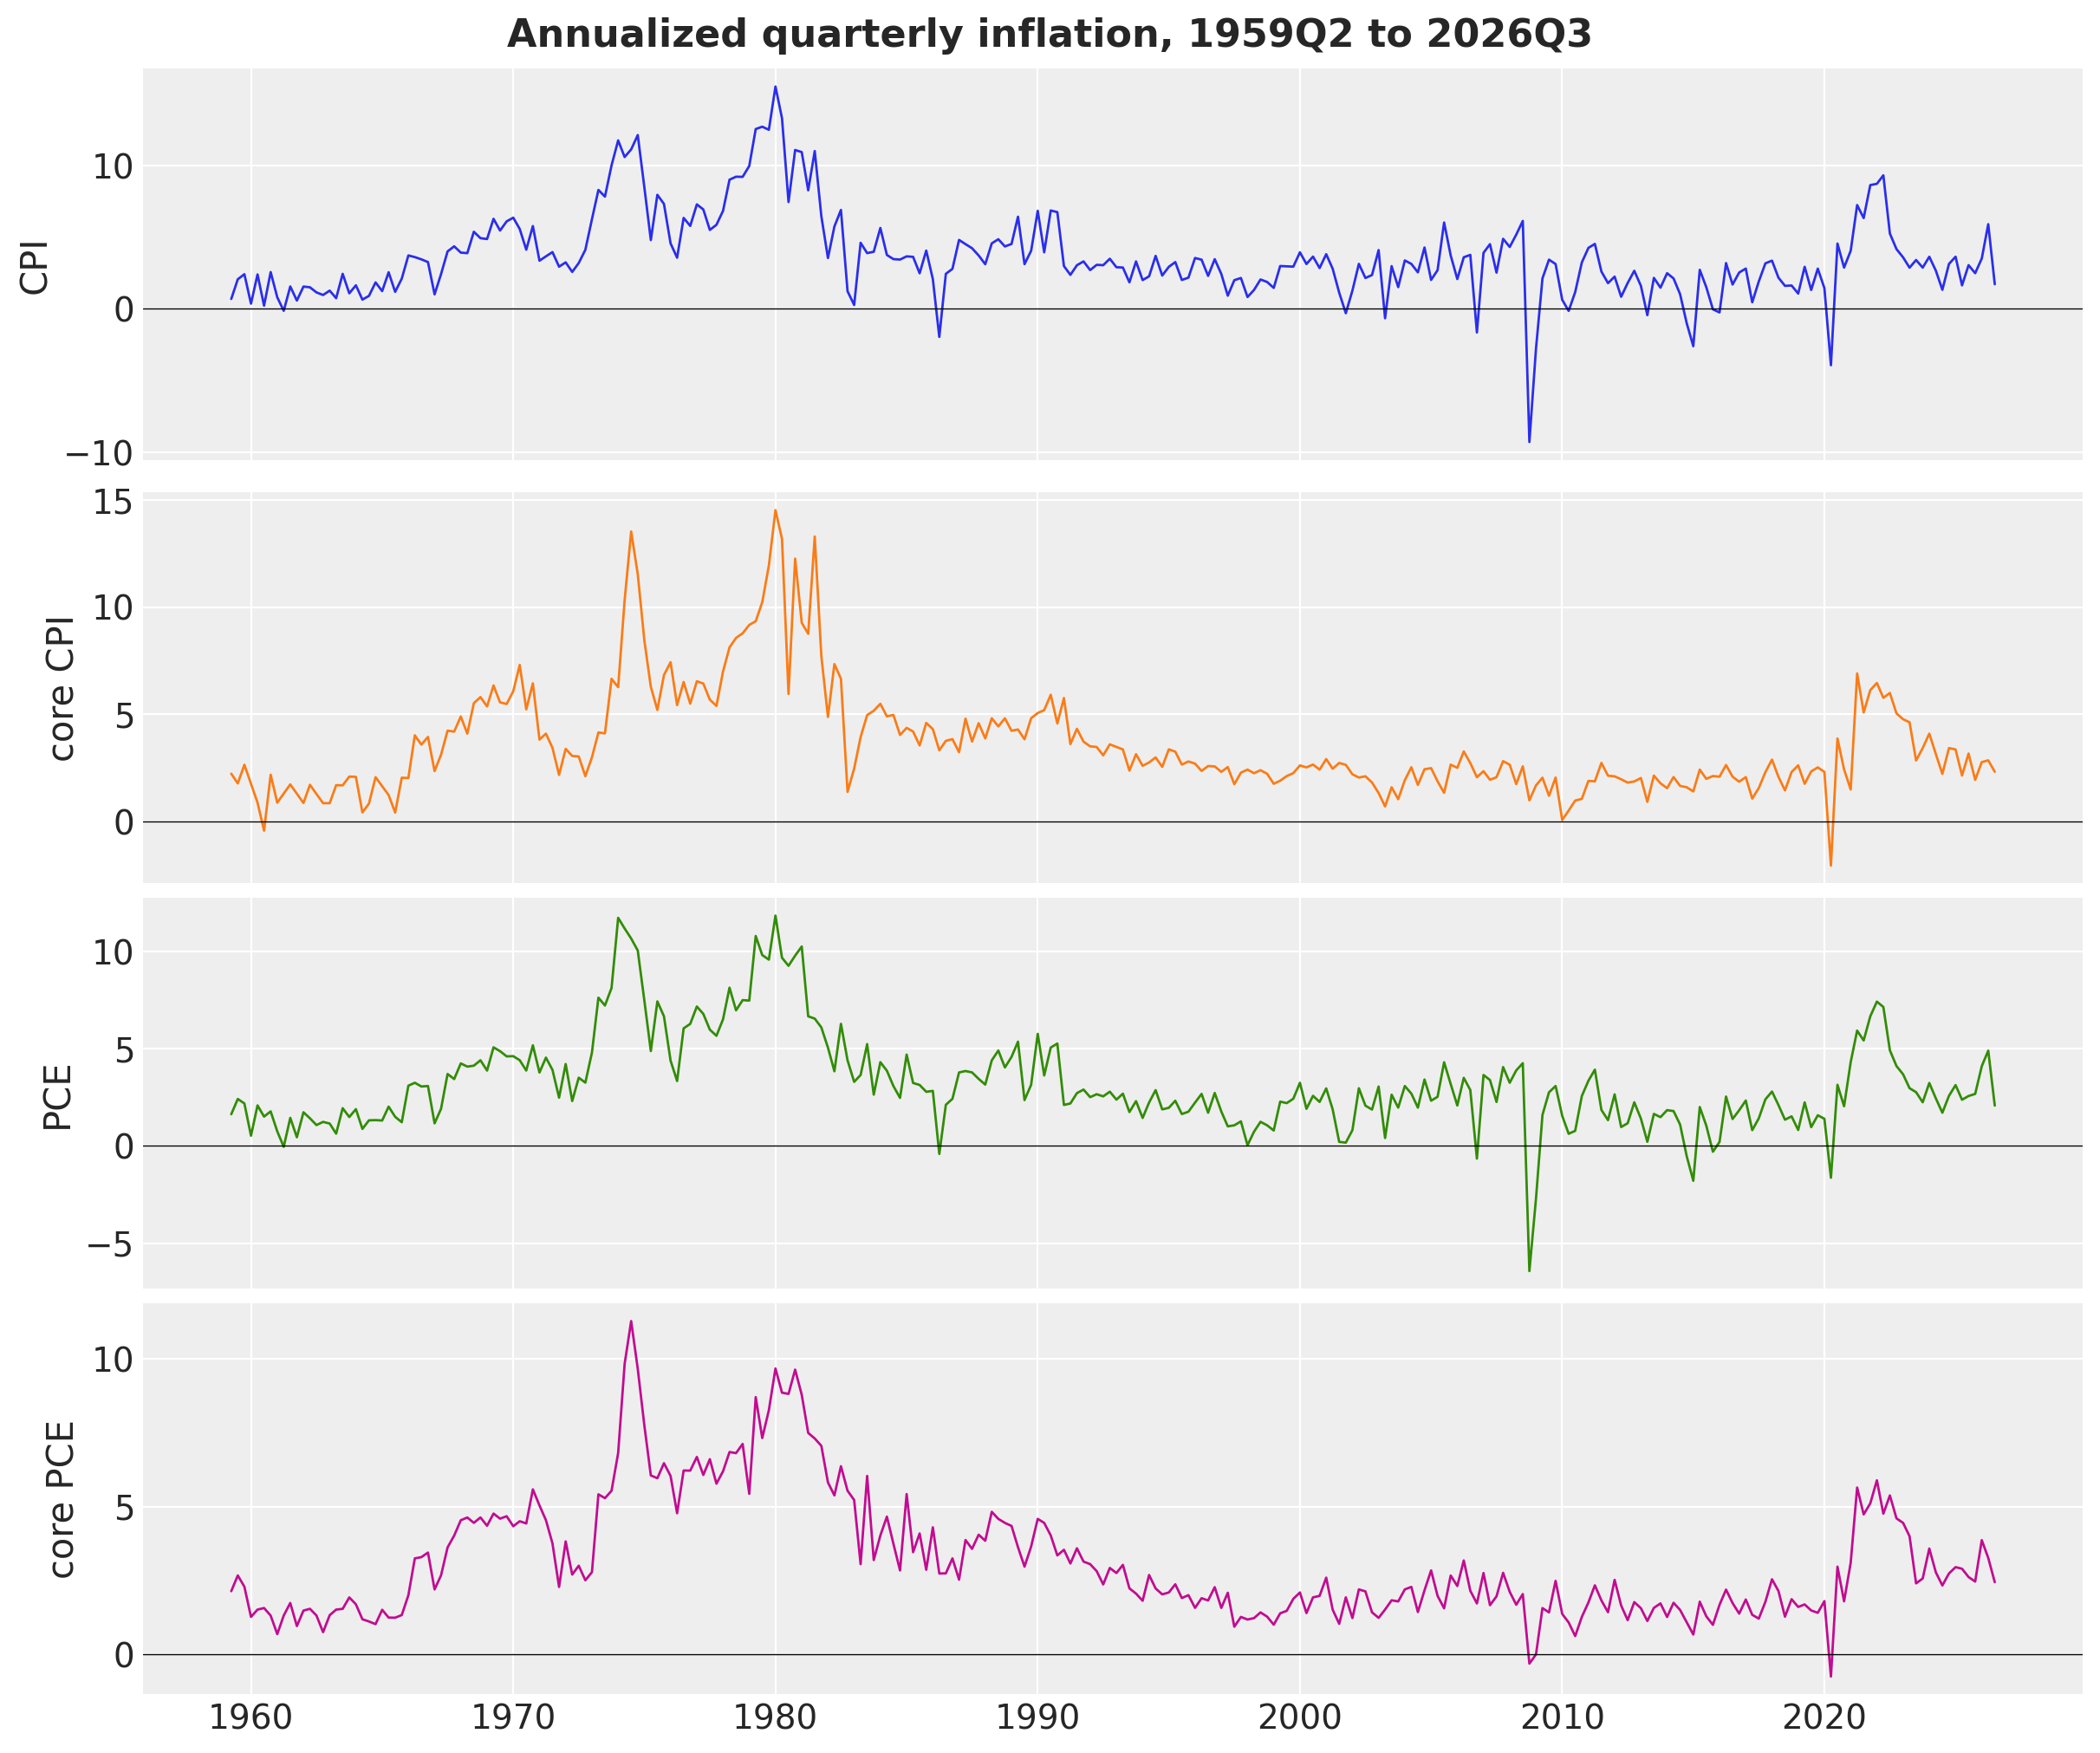

In [3]:
fig, axes = plt.subplots(nrows=num_measures, sharex=True, figsize=(12, 10), layout="constrained")

for ax, label, color, series in zip(
    axes, measure_labels, ("C0", "C1", "C2", "C3"), rates.T, strict=True
):
    ax.plot(dates, series, color=color, lw=1)
    ax.axhline(0.0, color="black", lw=0.5)
    ax.set(ylabel=label)

locator = mdates.AutoDateLocator()
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
fig.suptitle("Annualized quarterly inflation, 1959Q2 to 2026Q3", fontsize=16, fontweight="bold");

The four series tell the same story at different volumes:

- The 1970s have two peaks, around 1974 and 1980, where every measure runs above $10\%$ for several quarters.
- The Great Moderation, from the mid 1980s to 2007, keeps every measure in a narrow band around $2\%$ to $3\%$, and the core measures are visibly smoother than the headline ones.
- 2008Q4 is the quarter where the headline measures fall far below zero as oil prices collapse, while the core measures barely move.
- 2021 to 2023 is the surge after the pandemic, and 2020Q2 is the single-quarter dip before it.

The headline measures (CPI, PCE) swing more than their core counterparts at every date, because food and energy prices are in their baskets, and CPI runs above PCE on average, because of the formula and weight differences between the two indexes. The model below has one parameter for the average wedge (the measure offset) and one time-varying scale per measure for the difference in noise.

## Evaluation metrics and the benchmark

The evaluation scores forecasts of core PCE inflation at horizons of one to eight quarters, in two forms: the eight quarterly rates themselves and the **4-quarter average**, the mean of the first four quarterly rates of the horizon, which is the quantity policy discussions use. The mean of four annualized quarterly log rates is exactly the annual log change, $100 \, (\log P_{t+4} - \log P_t)$, so the second form is the one-year inflation rate from the forecast origin.

We use three metrics:

- The **continuous ranked probability score** (CRPS) of [Gneiting and Raftery (2007)](https://doi.org/10.1198/016214506000001437) scores the whole forecast distribution. For a forecast with draws $X, X'$ and a realized value $y$ it is $\text{E}|X - y| - \tfrac{1}{2} \text{E}|X - X'|$, in percentage points: the first term rewards accuracy and the second rewards sharpness, and a point forecast with no spread scores its absolute error. Lower is better.
- The **coverage** of the central $50\%$ and $94\%$ intervals is the share of realized quarters inside the interval; a calibrated forecast lands at the nominal level.
- The **mean absolute error** (MAE) of the forecast median is the point-forecast score we can compare with a benchmark that has no distribution.

The benchmark is the random-walk forecast of [Atkeson and Ohanian (2001)](https://www.minneapolisfed.org/research/quarterly-review/are-phillips-curves-useful-for-forecasting-inflation): the average inflation of the last four quarters before the origin, held flat over the horizon. It is a point forecast with no model, and it is the standard hard benchmark in the inflation forecasting literature because the models that beat it on the 4-quarter average are few. We score it with the MAE on both forms of the target.

## Model specification

For quarter $t = 1, \dots, T$ and measure $m = 1, \dots, M$ with $M = 4$, the model is

$$
\begin{align*}
\pi_{t, m} &= \alpha_m + \tau_t + \varepsilon_{t, m}, & \varepsilon_{t, m} &\sim \text{Normal}\left(0, \exp(g_{t, m} / 2)\right), \\
\tau_t &= \tau_{t-1} + \exp(h_t / 2) \, z_t, & z_t &\sim \text{Normal}(0, 1), \\
h_t &= h_{t-1} + \gamma \, u_t, & u_t &\sim \text{Normal}(0, 1), \\
g_{t, m} &= g_{t-1, m} + \gamma \, v_{t, m}, & v_{t, m} &\sim \text{Normal}(0, 1),
\end{align*}
$$

where

- $\pi_{t, m}$ is the annualized quarterly inflation of measure $m$,
- $\tau_t$ is **trend inflation**, common to all measures,
- $\alpha_m$ is the **offset** of measure $m$ relative to core PCE, with $\alpha_M = 0$ for core PCE, which identifies the level of the trend (without it, a constant could move between the trend and the offsets),
- $\varepsilon_{t, m}$ is the transitory **gap** of measure $m$, independent across measures and over time given its scale,
- $h_t$ and $g_{t, m}$ are the **log-variances** of the trend shock and of each gap, random walks with the common **vol-of-vol** $\gamma$, the standard deviation of their steps.

The random walks are written in non-centered form: the model samples the standardized steps $z_t$, $u_t$ and $v_{t, m}$ and builds the paths with a cumulative sum, so the latent paths are deterministic functions of unit normals and no reparameterization is needed. The trend and the four gaps are the two components of every measure, and the trend is the part that all four share.

The priors are

$$
\begin{align*}
\alpha_m &\sim \text{Normal}(0, 1), \quad m < M, \\
\tau_0 &\sim \text{Normal}(3, 2), \\
h_0 &\sim \text{Normal}(-1.5, 1), \\
g_{0, m} &\sim \text{Normal}(0, 1), \\
\gamma &= 0.1 \quad \text{(fixed)}.
\end{align*}
$$

On the scale of the data, where a typical quarter of core inflation sits between $1\%$ and $5\%$:

- $\tau_0 \sim \text{Normal}(3, 2)$ puts the trend at the start of the sample between $-1\%$ and $7\%$ with $95\%$ probability, which covers the late 1950s.
- $h_0 = -1.5$ is a trend shock with standard deviation $\exp(-0.75) \approx 0.47$ percentage points per quarter, and the prior standard deviation of $1$ on $h_0$ lets that scale range from about $0.3$ to $0.8$ within one standard deviation.
- $g_{0, m} = 0$ is a gap with a standard deviation of $1$ percentage point, the right order for the core measures; the headline measures move up from there through $g_{t, m}$.
- $\alpha_m \sim \text{Normal}(0, 1)$ allows offsets of about $\pm 2$ percentage points, which is wide for the CPI to PCE wedge of a few tenths.
- $\gamma$ is fixed, as in Stock and Watson (2007). After $t$ quarters the log-variance has prior standard deviation $\gamma \sqrt{t}$, about $1.6$ for $\gamma = 0.1$ and $t = 270$, so a volatility can drift by a factor of $\exp(0.8) \approx 2.2$ in either direction over the sample within one standard deviation. This is the quantity worth plotting, because it is what $\gamma$ means. We fix $\gamma$ instead of learning it because the data say little about it: the *Sensitivity to the vol-of-vol* section fits the model with a prior on $\gamma$ and shows what the posterior does.

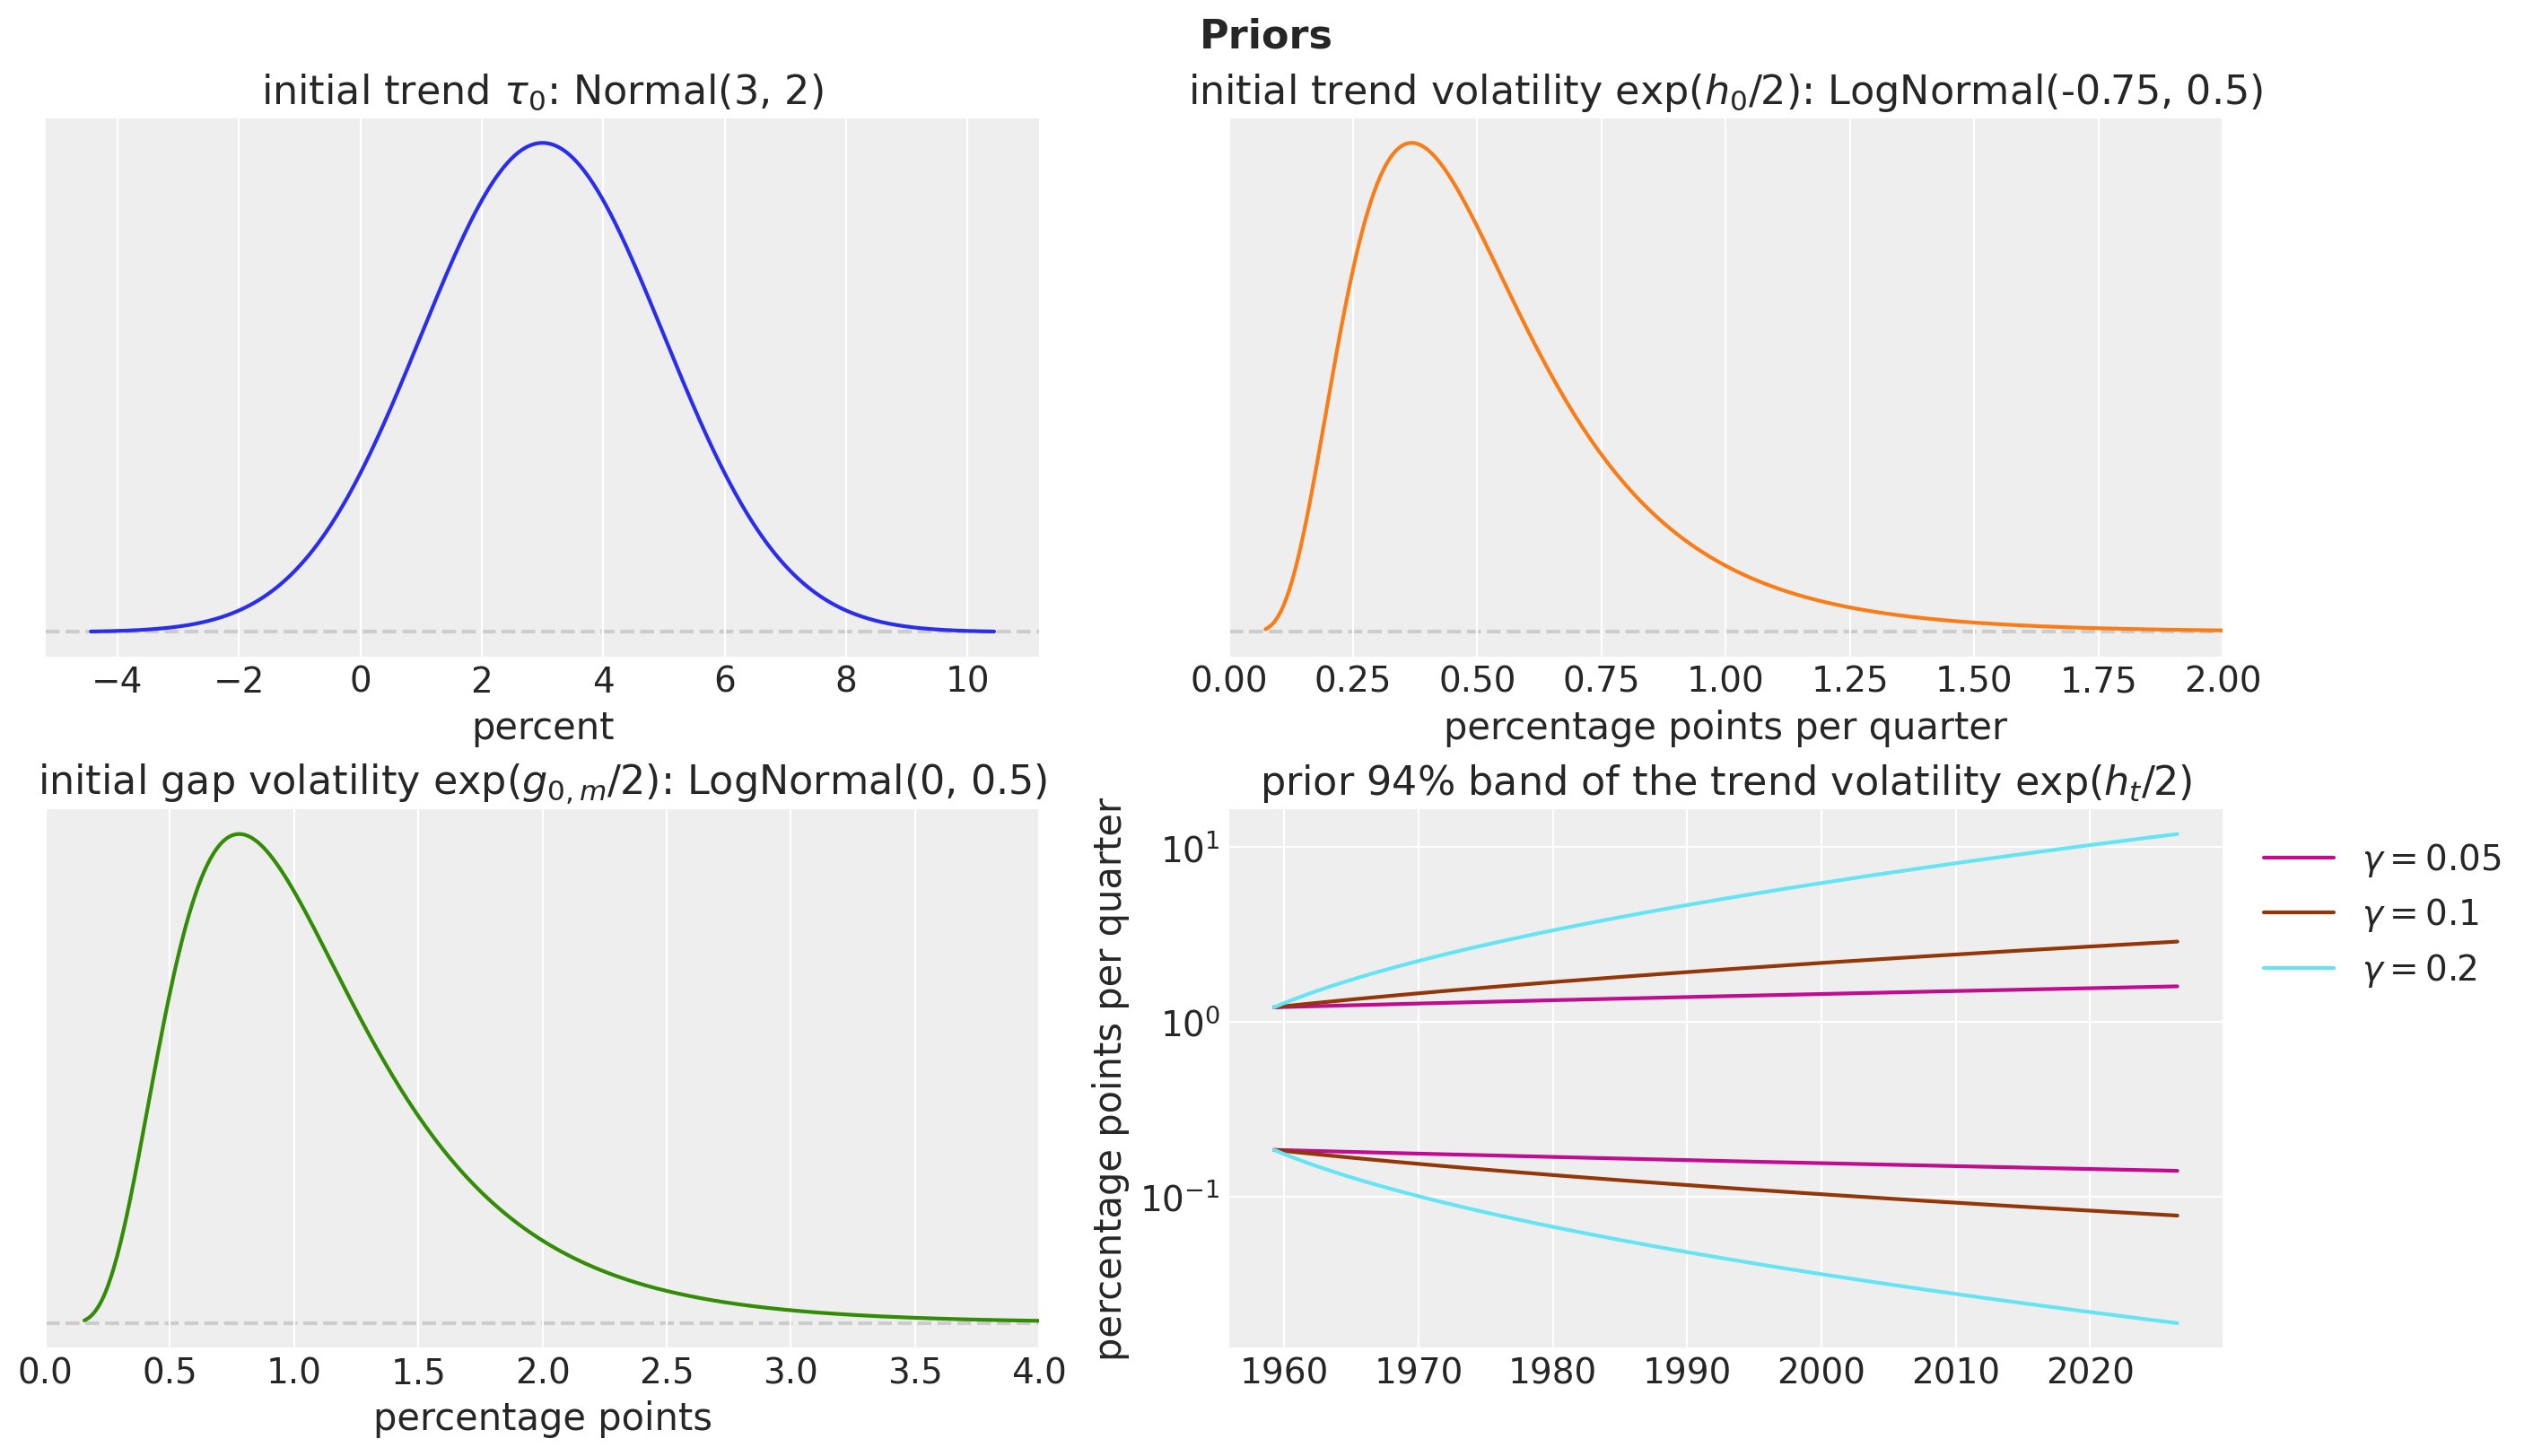

In [4]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 8), layout="constrained")
pz.Normal(3, 2).plot_pdf(ax=axes[0, 0], color="C0", legend=None)
axes[0, 0].set(title=r"initial trend $\tau_0$: Normal(3, 2)", xlabel="percent")
pz.LogNormal(-0.75, 0.5).plot_pdf(ax=axes[0, 1], color="C1", legend=None)
axes[0, 1].set(
    title=r"initial trend volatility $\exp(h_0 / 2)$: LogNormal(-0.75, 0.5)",
    xlabel="percentage points per quarter",
    xlim=(0, 2),
)
pz.LogNormal(0, 0.5).plot_pdf(ax=axes[1, 0], color="C2", legend=None)
axes[1, 0].set(
    title=r"initial gap volatility $\exp(g_{0, m} / 2)$: LogNormal(0, 0.5)",
    xlabel="percentage points",
    xlim=(0, 4),
)

# Prior 94% band of the trend volatility exp(h_t / 2) after t quarters, for three vol-of-vol values.
# h_t ~ Normal(-1.5, sqrt(1 + gamma^2 t)), so the band is exp((-1.5 +/- z sqrt(1 + gamma^2 t)) / 2).
steps = jnp.arange(num_quarters)  # (quarters,)
z_97 = norm.ppf(0.97)

for color, gamma in zip(("C3", "C4", "C5"), (0.05, 0.1, 0.2), strict=True):
    half_width = z_97 * jnp.sqrt(1.0 + gamma**2 * steps)  # (quarters,)
    axes[1, 1].plot(
        dates, jnp.exp((-1.5 + half_width) / 2.0), color=color, label=rf"$\gamma = {gamma}$"
    )
    axes[1, 1].plot(dates, jnp.exp((-1.5 - half_width) / 2.0), color=color)

axes[1, 1].set(
    title=r"prior $94\%$ band of the trend volatility $\exp(h_t / 2)$",
    ylabel="percentage points per quarter",
    yscale="log",
)
axes[1, 1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle("Priors", fontsize=16, fontweight="bold");

The three densities are the priors on the initial values, on the scale of the data. The fourth panel is what the fixed $\gamma$ implies: with $\gamma = 0.1$ the $94\%$ prior band of the trend volatility widens from $(0.18, 1.2)$ percentage points per quarter at the start of the sample to $(0.02, 10)$ at its end, so the prior lets the volatility fall by a factor of ten or rise by a factor of ten over 67 years, and it says nothing about when. With $\gamma = 0.05$ the band at the end is four times narrower; with $\gamma = 0.2$ it reaches from $0.001$ to $200$, which is the range where the prior stops constraining anything and the posterior has to find the path on its own.

## The model function

The model is one function with three switches, so that the ladder of the evaluation changes no code:

- `num_measures` is $M$; with `num_measures=1` there is no offset and the model is the univariate UCSV of Stock and Watson (2007).
- `stochastic_volatility=False` freezes $h_t = h_0$ and $g_{t, m} = g_{0, m}$: constant variances.
- `student_t=True` replaces the Normal gaps with Student-t gaps $\varepsilon_{t, m} \sim \text{StudentT}(\nu, 0, \exp(g_{t, m} / 2))$ with $\nu \sim \text{Gamma}(10, 1)$, a prior centered at $10$ degrees of freedom with a standard deviation of about $3$.

The model reads no covariates. [`Horizon.from_data`](../../reference/models.Horizon.html) takes the duration from the `covariates` array, so the training call passes `jnp.zeros((num_quarters, 0))` and a forecast call passes an array with eight more rows. Every random walk is a cumulative sum of standardized steps from `innovations`, which samples the in-sample steps under the `time` plate and, when the covariates are longer than the data, the horizon steps at a separate `_future` site. The gap volatility `gap_vol` has a time axis, and `predict` accepts a noise distribution whose scale varies over the full horizon, so the stochastic volatility propagates into the forecast without any extra code.

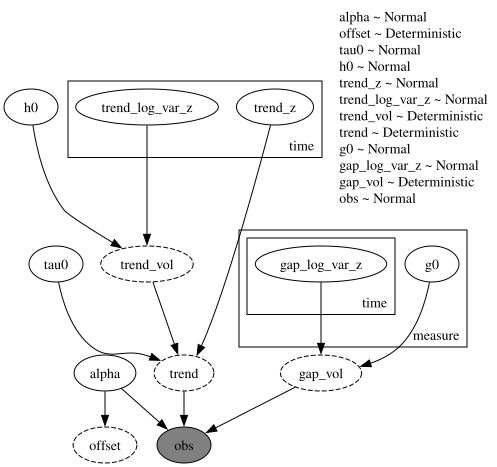

In [5]:
def make_trend_inflation_model(
    num_measures: int,
    *,
    vol_of_vol: float | Array = 0.1,
    stochastic_volatility: bool = True,
    student_t: bool = False,
) -> ForecastModel:
    """Build the trend inflation model: common trend, measure offsets, stochastic volatility."""

    def trend_inflation_model(covariates: Array, data: Array | None = None) -> None:
        """Trend inflation model for ``data`` shaped ``(duration, num_measures)``."""
        h = Horizon.from_data(covariates, data)
        measure_plate = numpyro.plate("measure", num_measures, dim=-1)

        # Offsets relative to the last measure (core PCE), whose offset is zero: (num_measures,)
        if num_measures > 1:
            alpha = numpyro.sample(
                "alpha", dist.Normal(0.0, 1.0).expand([num_measures - 1]).to_event(1)
            )
            offset = jnp.concatenate([alpha, jnp.zeros(1)])
        else:
            offset = jnp.zeros(1)
        numpyro.deterministic("offset", offset)

        # Trend: a random walk whose log-variance is a random walk. Shapes (duration, 1).
        tau0 = numpyro.sample("tau0", dist.Normal(3.0, 2.0))
        h0 = numpyro.sample("h0", dist.Normal(-1.5, 1.0))
        trend_z = innovations(h, "trend_z", dist.Normal(0.0, 1.0))
        if stochastic_volatility:
            trend_log_var_z = innovations(h, "trend_log_var_z", dist.Normal(0.0, 1.0))
            log_var_trend = h0 + vol_of_vol * jnp.cumsum(trend_log_var_z, axis=-2)
        else:
            log_var_trend = h0 * jnp.ones_like(trend_z)
        trend_vol = numpyro.deterministic("trend_vol", jnp.exp(log_var_trend / 2.0))
        trend = numpyro.deterministic("trend", tau0 + jnp.cumsum(trend_vol * trend_z, axis=-2))

        # Gaps: one log-variance random walk per measure. Shapes (duration, num_measures).
        with measure_plate:
            g0 = numpyro.sample("g0", dist.Normal(0.0, 1.0))
        if stochastic_volatility:
            with measure_plate:
                gap_log_var_z = innovations(h, "gap_log_var_z", dist.Normal(0.0, 1.0))
            log_var_gap = g0 + vol_of_vol * jnp.cumsum(gap_log_var_z, axis=-2)
        else:
            log_var_gap = jnp.broadcast_to(g0, (h.duration, num_measures))
        gap_vol = numpyro.deterministic("gap_vol", jnp.exp(log_var_gap / 2.0))

        # (duration, 1) trend + (num_measures,) offsets -> (duration, num_measures) predictor
        prediction = trend + offset
        if student_t:
            nu = numpyro.sample("nu", dist.Gamma(10.0, 1.0))
            predict(h, dist.StudentT(nu, 0.0, gap_vol), prediction)
        else:
            predict(h, dist.Normal(0.0, gap_vol), prediction)

    return trend_inflation_model


HORIZON = 8
covariates_train = jnp.zeros((num_quarters, 0))  # (quarters, 0): only the duration is read
covariates_full = jnp.zeros((num_quarters + HORIZON, 0))  # (quarters + 8, 0): adds the horizon

model = make_trend_inflation_model(num_measures)
numpyro.render_model(model, model_args=(covariates_train, rates), render_distributions=True)

## Prior predictive check

Before the data, we draw core PCE inflation from the priors over the whole sample and compare its band with the observed series. The band should contain the data with room to spare, and it should not contain values that no price index has ever produced.

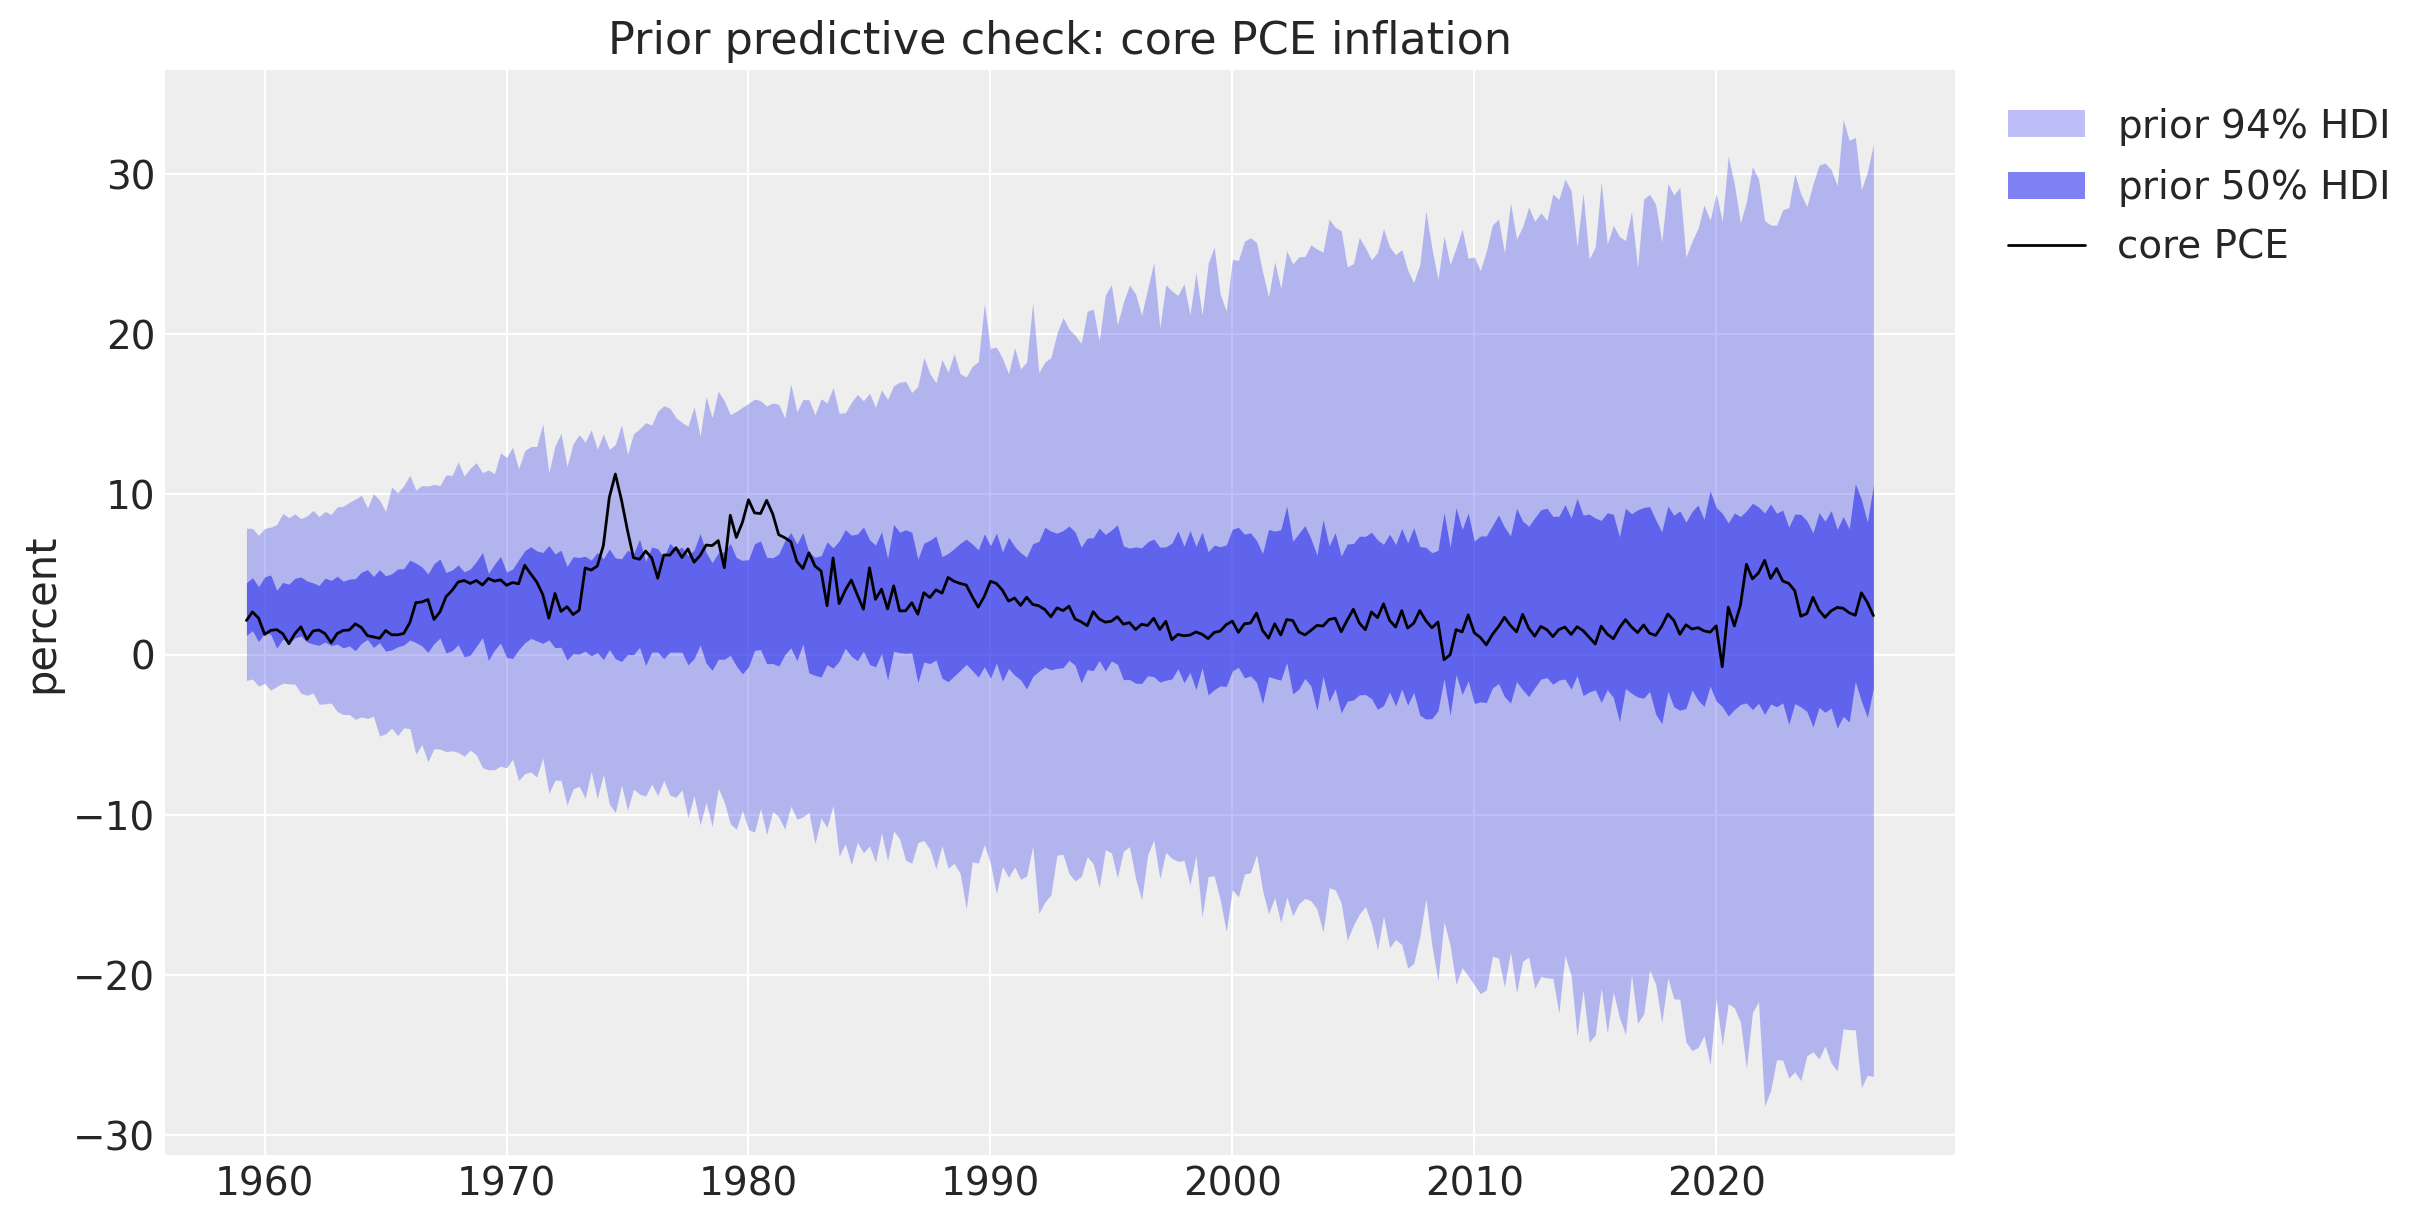

In [6]:
HDI_PROBS = (0.94, 0.5)
HDI_ALPHAS = (0.3, 0.6)


def hdi_label(prob: float) -> str:
    r"""Legend label of an HDI band, for example ``$94\%$ HDI``."""
    return rf"${prob:.0%}$ HDI".replace("%", r"\%")


rng_key, key_prior = random.split(rng_key)
prior_obs = Predictive(model, num_samples=1_000, return_sites=["obs"])(
    key_prior, covariates_train
)["obs"]  # (draws, quarters, measures)

prior_tree = predictions_to_datatree(
    prior_obs[:, :, -1:],
    date_num,
    ["core PCE"],
    group="prior_predictive",
    observed=rates[:, -1:],
)
pc = az.plot_lm(
    prior_tree,
    y="obs",
    x="t",
    plot_dim="time",
    group="prior_predictive",
    ci_kind="hdi",
    ci_prob=HDI_PROBS,
    smooth=False,
    visuals={
        "ci_band": {"color": "C0"},
        "observed_scatter": False,
        "pe_line": False,
        "xlabel": False,
        "ylabel": False,
    },
    aes={"alpha": ["prob"]},
    alpha=HDI_ALPHAS,
    figure_kwargs={"figsize": (12, 6)},
)
ax = pc.viz["figure"].item().axes[0]
(observed_line,) = ax.plot(date_num, rates[:, -1], color="black", lw=1, label="core PCE")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
band_handles = []

for prob in HDI_PROBS:
    band = pc.viz["ci_band"]["t"].sel(prob=prob).item()
    band.set_label(f"prior {hdi_label(prob)}")
    band_handles.append(band)

ax.legend(handles=[*band_handles, observed_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(title="Prior predictive check: core PCE inflation", ylabel="percent");

The prior band widens with time, because both random walks accumulate variance: the $94\%$ band is about $\pm 6$ percentage points wide in 1960 and about $\pm 20$ percentage points wide in 2026. It contains the data everywhere, with the 1980 peak well inside the band, and it also allows annualized rates of $-15\%$ at the end of the sample, which the US has never produced in a quarter. The priors are weak on purpose: the posterior will have to decide how volatile the trend and the gaps are at each date, and the only thing fixed is how fast that volatility is allowed to change.

## Inference with NUTS

We sample the posterior with four NUTS chains of $1{,}000$ warmup and $1{,}000$ draws each. The model has about $1{,}600$ latent dimensions (five standardized random walks of 270 steps plus the initial values and the offsets), all continuous, and the non-centered form keeps the geometry regular enough for the default settings except for one knob: we raise `target_accept_prob` from its default of $0.8$ to $0.9$, which shortens the leapfrog steps, because the posterior has a funnel where a gap volatility approaches zero. The figure after the trace plot shows where the remaining divergent transitions sit.

The fit returns the `MCMC` object and the wall time. `export` turns the posterior into an ArviZ `DataTree` with [`to_datatree`](../../reference/convert.to_datatree.html): the four chains, the in-sample posterior predictive, the eight-quarter forecast (because `covariates_full` extends past the data) and the quarter dates as the `time` coordinate, with the measure names on every site that has a measure axis.

In [7]:
NUM_CHAINS = 4
FULL_WARMUP = 1_000
FULL_SAMPLES = 1_000
TARGET_ACCEPT = 0.9
GLOBAL_SITES = ("tau0", "h0", "g0", "alpha", "nu", "vol_of_vol")


def fit_nuts(
    rng_key: Array, model: ForecastModel, data: Array, *, num_warmup: int, num_samples: int
) -> tuple[MCMC, float]:
    """Fit ``model`` with NUTS and return the sampler and the wall time in seconds."""
    mcmc = MCMC(
        NUTS(model, target_accept_prob=TARGET_ACCEPT),
        num_warmup=num_warmup,
        num_samples=num_samples,
        num_chains=NUM_CHAINS,
        progress_bar=False,
    )
    start = perf_counter()
    mcmc.run(rng_key, jnp.zeros((data.shape[0], 0)), data, extra_fields=("diverging",))
    jax.block_until_ready(mcmc.get_samples())
    return mcmc, perf_counter() - start


def num_divergences(mcmc: MCMC) -> int:
    """Total number of divergent transitions across chains."""
    return int(np.asarray(mcmc.get_extra_fields()["diverging"]).sum())


def diagnostics(mcmc: MCMC, sites: tuple[str, ...] = GLOBAL_SITES) -> tuple[float, float]:
    """Largest split R-hat and smallest effective sample size over the ``sites`` of the fit."""
    samples = mcmc.get_samples(group_by_chain=True)
    summary = numpyro.diagnostics.summary(
        {site: samples[site] for site in sites if site in samples}, group_by_chain=True
    )
    r_hat = max(float(np.max(stats["r_hat"])) for stats in summary.values())
    ess = min(float(np.min(stats["n_eff"])) for stats in summary.values())
    return r_hat, ess


def fit_title(label: str, mcmc: MCMC, seconds: float) -> str:
    """Title line with the wall time, the divergences, the largest R-hat and the smallest ESS."""
    r_hat, ess = diagnostics(mcmc)
    return (
        f"{label}: {seconds:.0f} s, {num_divergences(mcmc)} divergences, "
        rf"max $\hat{{R}}$ {r_hat:.3f}, min ESS {ess:,.0f}"
    )


rng_key, key_fit = random.split(rng_key)
mcmc, seconds = fit_nuts(key_fit, model, rates, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES)

In [8]:
future_dates = (dates[-1].astype("datetime64[M]") + 3 * np.arange(1, HORIZON + 1)).astype(
    "datetime64[D]"
)
future_date_num = mdates.date2num(future_dates)
time_coord = np.concatenate([dates, future_dates])
posterior_dims = {
    "trend": ["time"],
    "trend_vol": ["time"],
    "gap_vol": ["time", "measure"],
    "g0": ["measure"],
    "offset": ["measure"],
    "alpha": ["free_measure"],
}


def export(rng_key: Array, model: ForecastModel, mcmc: MCMC) -> xr.DataTree:
    """Posterior, in-sample predictive and forecast draws as a labeled ArviZ tree."""
    return to_datatree(
        rng_key,
        model,
        mcmc.get_samples(),
        rates,
        covariates_full,
        num_chains=NUM_CHAINS,
        coords={"measure": list(measure_labels), "free_measure": list(measure_labels[:-1])},
        time_coord=time_coord,
        posterior_dims=posterior_dims,
        obs_dims=["time", "measure"],
    )


rng_key, key_tree = random.split(rng_key)
tree = export(key_tree, model, mcmc)
tree

<xarray.DataTree>
Group: /
│   Attributes:
│       inference_library:  numpyro
│       creation_library:   numpyro_forecast
│       sample_dims:        ['chain', 'draw']
├── Group: /posterior
│       Dimensions:                (chain: 4, draw: 1000, free_measure: 3, measure: 4,
│                                   gap_log_var_z_dim_0: 270, gap_log_var_z_dim_1: 4,
│                                   time: 270, trend_dim_0: 1,
│                                   trend_log_var_z_dim_0: 270,
│                                   trend_log_var_z_dim_1: 1, trend_vol_dim_0: 1,
│                                   trend_z_dim_0: 270, trend_z_dim_1: 1)
│       Coordinates: (12/13)
│         * chain                  (chain) int64 32B 0 1 2 3
│         * draw                   (draw) int64 8kB 0 1 2 3 4 5 ... 995 996 997 998 999
│         * free_measure           (free_measure) <U8 96B 'CPI' 'core CPI' 'PCE'
│         * measure                (measure) <U8 128B 'CPI' 'core CPI' 'PCE' 'core PCE'
│         * gap_log_var_z_dim_0    (gap_log_var_z_dim_0) int64 2kB 0 1 2 ... 267 268 269
│         * gap_log_var_z_dim_1    (gap_log_var_z_dim_1) int64 32B 0 1 2 3
│           ...                     ...
│         * trend_dim_0            (trend_dim_0) int64 8B 0
│         * trend_log_var_z_dim_0  (trend_log_var_z_dim_0) int64 2kB 0 1 2 ... 268 269
│         * trend_log_var_z_dim_1  (trend_log_var_z_dim_1) int64 8B 0
│         * trend_vol_dim_0        (trend_vol_dim_0) int64 8B 0
│         * trend_z_dim_0          (trend_z_dim_0) int64 2kB 0 1 2 3 ... 266 267 268 269
│         * trend_z_dim_1          (trend_z_dim_1) int64 8B 0
│       Data variables:
│           alpha                  (chain, draw, free_measure) float32 48kB 0.4715 .....
│           g0                     (chain, draw, measure) float32 64kB 0.2719 ... -2.029
│           gap_log_var_z          (chain, draw, gap_log_var_z_dim_0, gap_log_var_z_dim_1) float32 17MB ...
│           gap_vol                (chain, draw, time, measure) float32 17MB 1.116 .....
│           h0                     (chain, draw) float32 16kB -1.694 -1.839 ... -1.329
│           offset                 (chain, draw, measure) float32 64kB 0.4715 ... 0.0
│           tau0                   (chain, draw) float32 16kB 1.568 1.353 ... 1.499
│           trend                  (chain, draw, time, trend_dim_0) float32 4MB 2.163...
│           trend_log_var_z        (chain, draw, trend_log_var_z_dim_0, trend_log_var_z_dim_1) float32 4MB ...
│           trend_vol              (chain, draw, time, trend_vol_dim_0) float32 4MB 0...
│           trend_z                (chain, draw, trend_z_dim_0, trend_z_dim_1) float32 4MB ...
│       Attributes:
│           created_at:                 2026-11-08T20:17:10.931192+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /posterior_predictive
│       Dimensions:  (chain: 4, draw: 1000, time: 270, measure: 4)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * time     (time) datetime64[s] 2kB 1959-04-01 1959-07-01 ... 2026-07-01
│         * measure  (measure) <U8 128B 'CPI' 'core CPI' 'PCE' 'core PCE'
│       Data variables:
│           obs      (chain, draw, time, measure) float32 17MB 1.256 2.835 ... 2.392
│       Attributes:
│           created_at:                 2026-11-08T20:17:11.173999+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /observed_data
│       Dimensions:  (time: 270, measure: 4)
│       Coordinates:
│         * time     (time) datetime64[s] 2kB 1959-04-01 1959-07-01 ... 2026-07-01
│         * measure  (measure) <U8 128B 'CPI' 'core CP

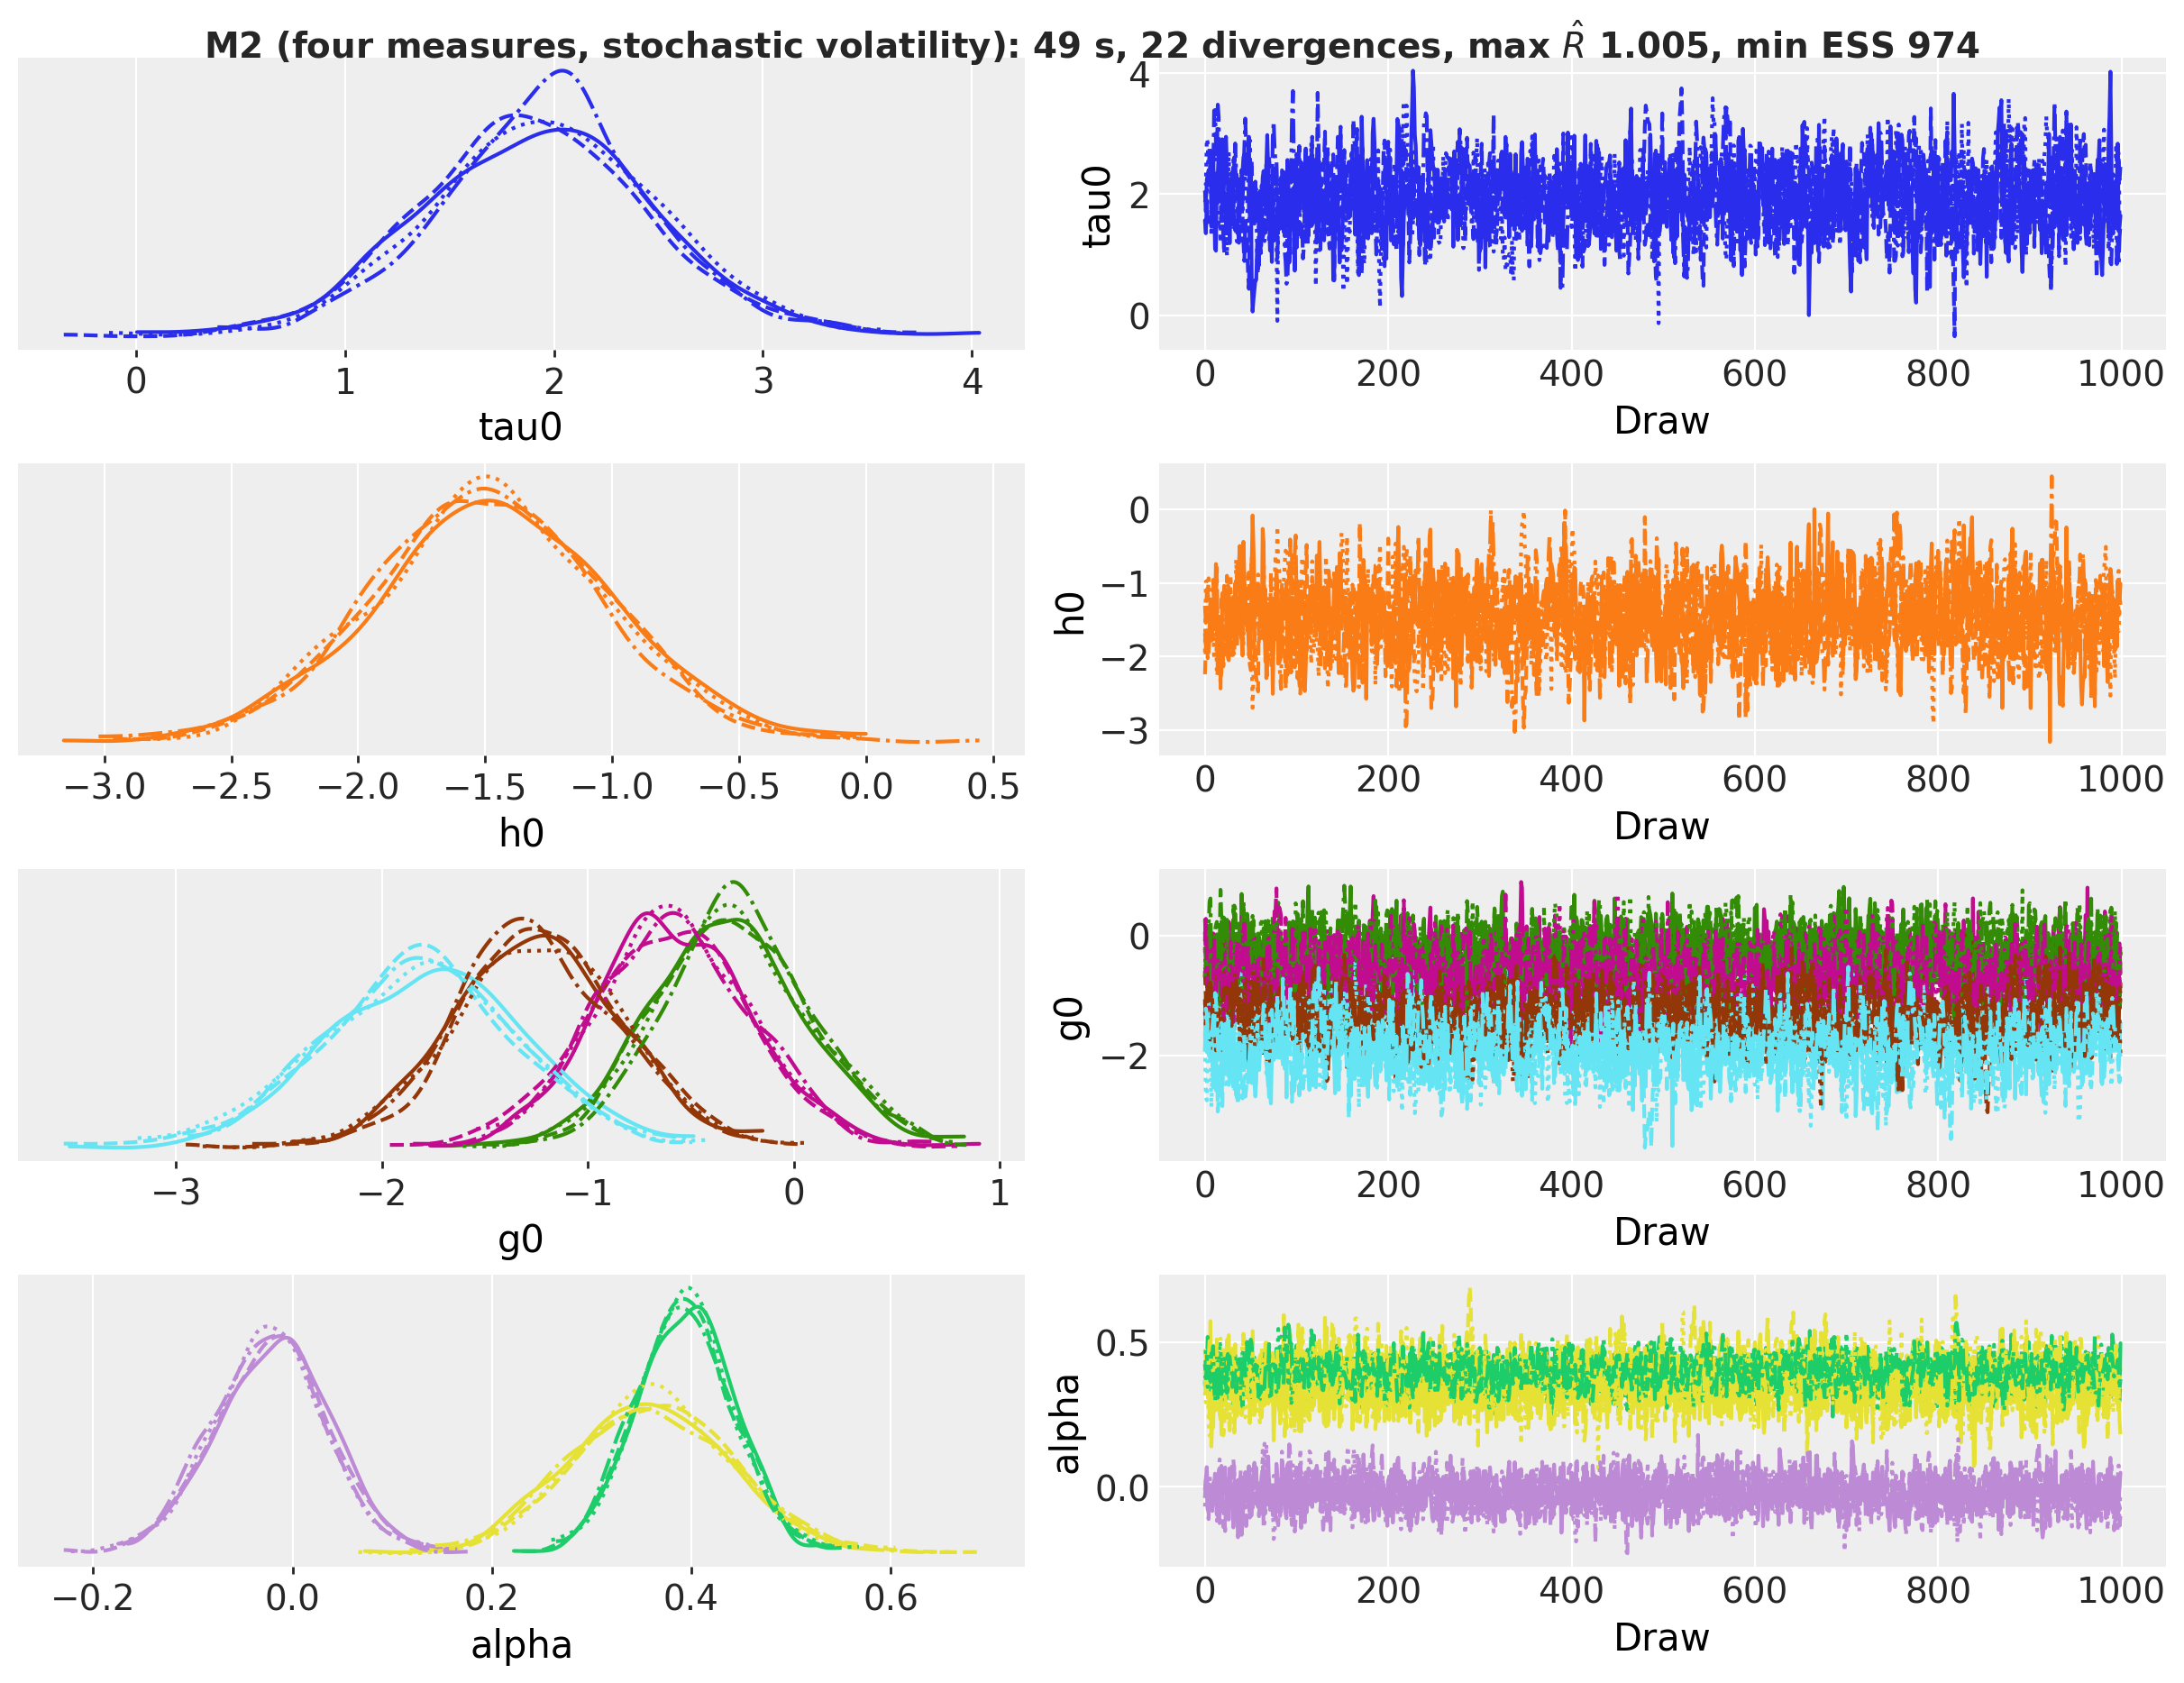

In [9]:
pc = az.plot_trace_dist(
    tree, var_names=["tau0", "h0", "g0", "alpha"], compact=True, figure_kwargs={"figsize": (12, 9)}
)
pc.viz["figure"].item().suptitle(
    fit_title("M2 (four measures, stochastic volatility)", mcmc, seconds),
    fontsize=14,
    fontweight="bold",
    y=1.02,
);

The four chains agree on every global parameter: the densities overlap, the largest $\hat{R}$ is below $1.01$ and the smallest effective sample size is in the hundreds. The divergences in the title are a small fraction of the $4{,}000$ draws. They are not a step-size problem, because the standardized steps have unit scale by construction. The next figure locates them: for every draw we take the smallest gap volatility of core PCE over the sample and mark the divergent draws on it.

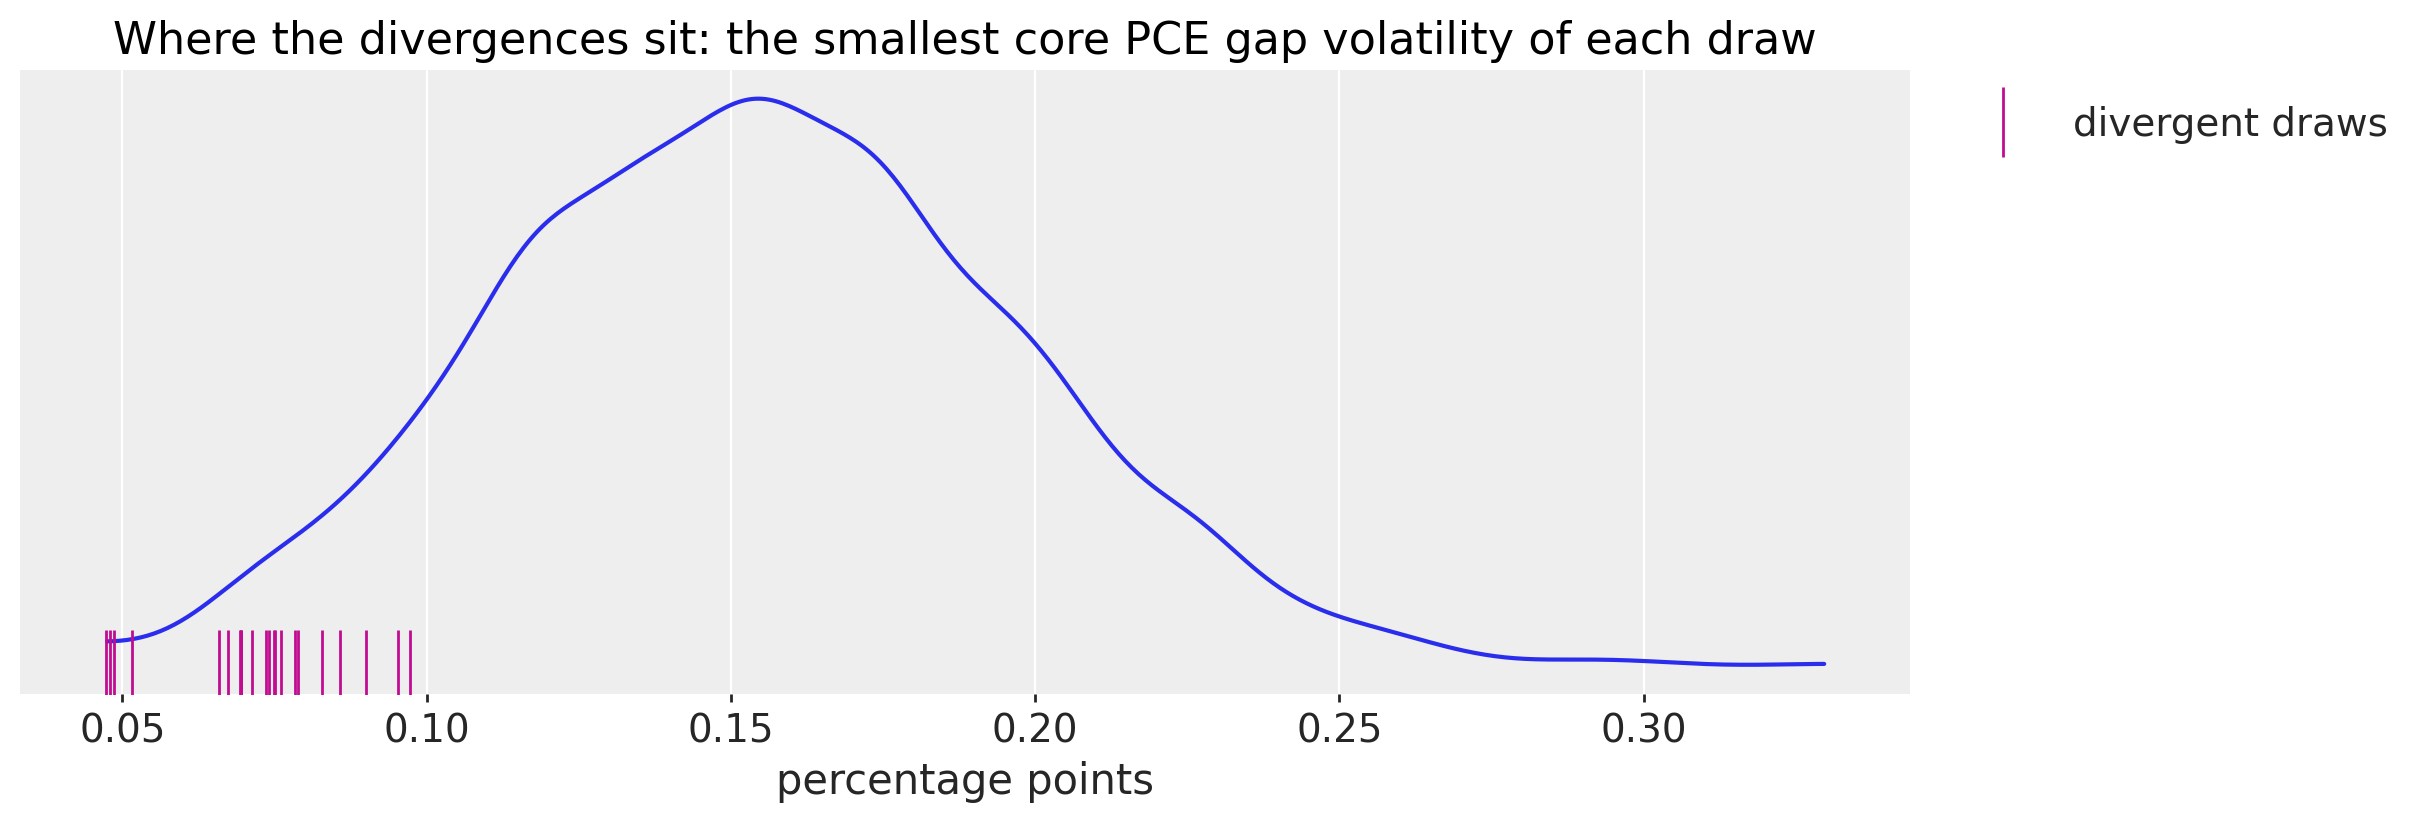

In [10]:
posterior = tree["posterior"].dataset
smallest_gap_vol = posterior["gap_vol"].sel(measure="core PCE").min("time")  # (chain, draw)
diverging = mcmc.get_extra_fields(group_by_chain=True)["diverging"]  # (chain, draw)

pc = az.plot_dist(
    smallest_gap_vol.to_dataset(name="smallest core PCE gap volatility"),
    kind="kde",
    visuals={"credible_interval": False, "point_estimate": False, "point_estimate_text": False},
    figure_kwargs={"figsize": (12, 4)},
)
ax = pc.viz["figure"].item().axes[0]
divergent_values = smallest_gap_vol.values[np.asarray(diverging)]
ax.plot(
    divergent_values,
    np.zeros_like(divergent_values),
    marker="|",
    linestyle="none",
    color="C3",
    markersize=25,
    label="divergent draws",
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title="Where the divergences sit: the smallest core PCE gap volatility of each draw",
    xlabel="percentage points",
);

The divergent draws sit in the left tail of the distribution, where the gap volatility of core PCE falls to a tenth of a percentage point or less. There the likelihood pins the trend to core PCE almost exactly in those quarters, the posterior narrows sharply in the direction of the trend steps, and the leapfrog integrator overshoots. The posterior mass in that tail is small, the chains agree on every parameter, and the quarters where it happens are the ones where core PCE is smoothest (the Great Moderation), so the draws we keep describe the same posterior. A model that put a floor under the gap volatility would remove the funnel, at the price of an extra parameter with no data to set it.

## Trend inflation

The trend is the part of inflation that all four measures share. We plot its posterior with core PCE inflation, the reference measure, on top: the gap between the line and the band is the transitory part of core PCE.

In [11]:
def stack_draws(variable: xr.DataArray) -> np.ndarray:
    """Posterior draws of a ``(chain, draw, time, ...)`` variable as ``(sample, time, ...)``."""
    return variable.stack(sample=("chain", "draw")).transpose("sample", "time", ...).to_numpy()


def plot_bands(
    draws: np.ndarray,
    x: np.ndarray,
    series: list[str],
    *,
    color: str = "C0",
    label: str = "",
    col_wrap: int = 1,
    figsize: tuple[int, int] = (12, 6),
) -> tuple[PlotCollection, list[PolyCollection]]:
    r"""Plot the $50\%$ and $94\%$ HDI bands of ``draws`` against ``x``, one panel per series.

    Returns the plot collection and the band handles, labeled ``f"{label}{hdi_label(prob)}"``.
    """
    pc = az.plot_lm(
        predictions_to_datatree(draws, x, series),
        y="obs",
        x="t",
        plot_dim="time",
        ci_kind="hdi",
        ci_prob=HDI_PROBS,
        smooth=False,
        col_wrap=col_wrap,
        visuals={
            "ci_band": {"color": color},
            "observed_scatter": False,
            "pe_line": False,
            "xlabel": False,
            "ylabel": False,
        },
        aes={"alpha": ["prob"]},
        alpha=HDI_ALPHAS,
        figure_kwargs={"figsize": figsize},
    )
    handles = []

    for prob in HDI_PROBS:
        band = pc.viz["ci_band"]["t"].sel(series=series[0], prob=prob).item()
        band.set_label(f"{label}{hdi_label(prob)}")
        handles.append(band)

    for ax in pc.viz["figure"].item().axes:
        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    return pc, handles

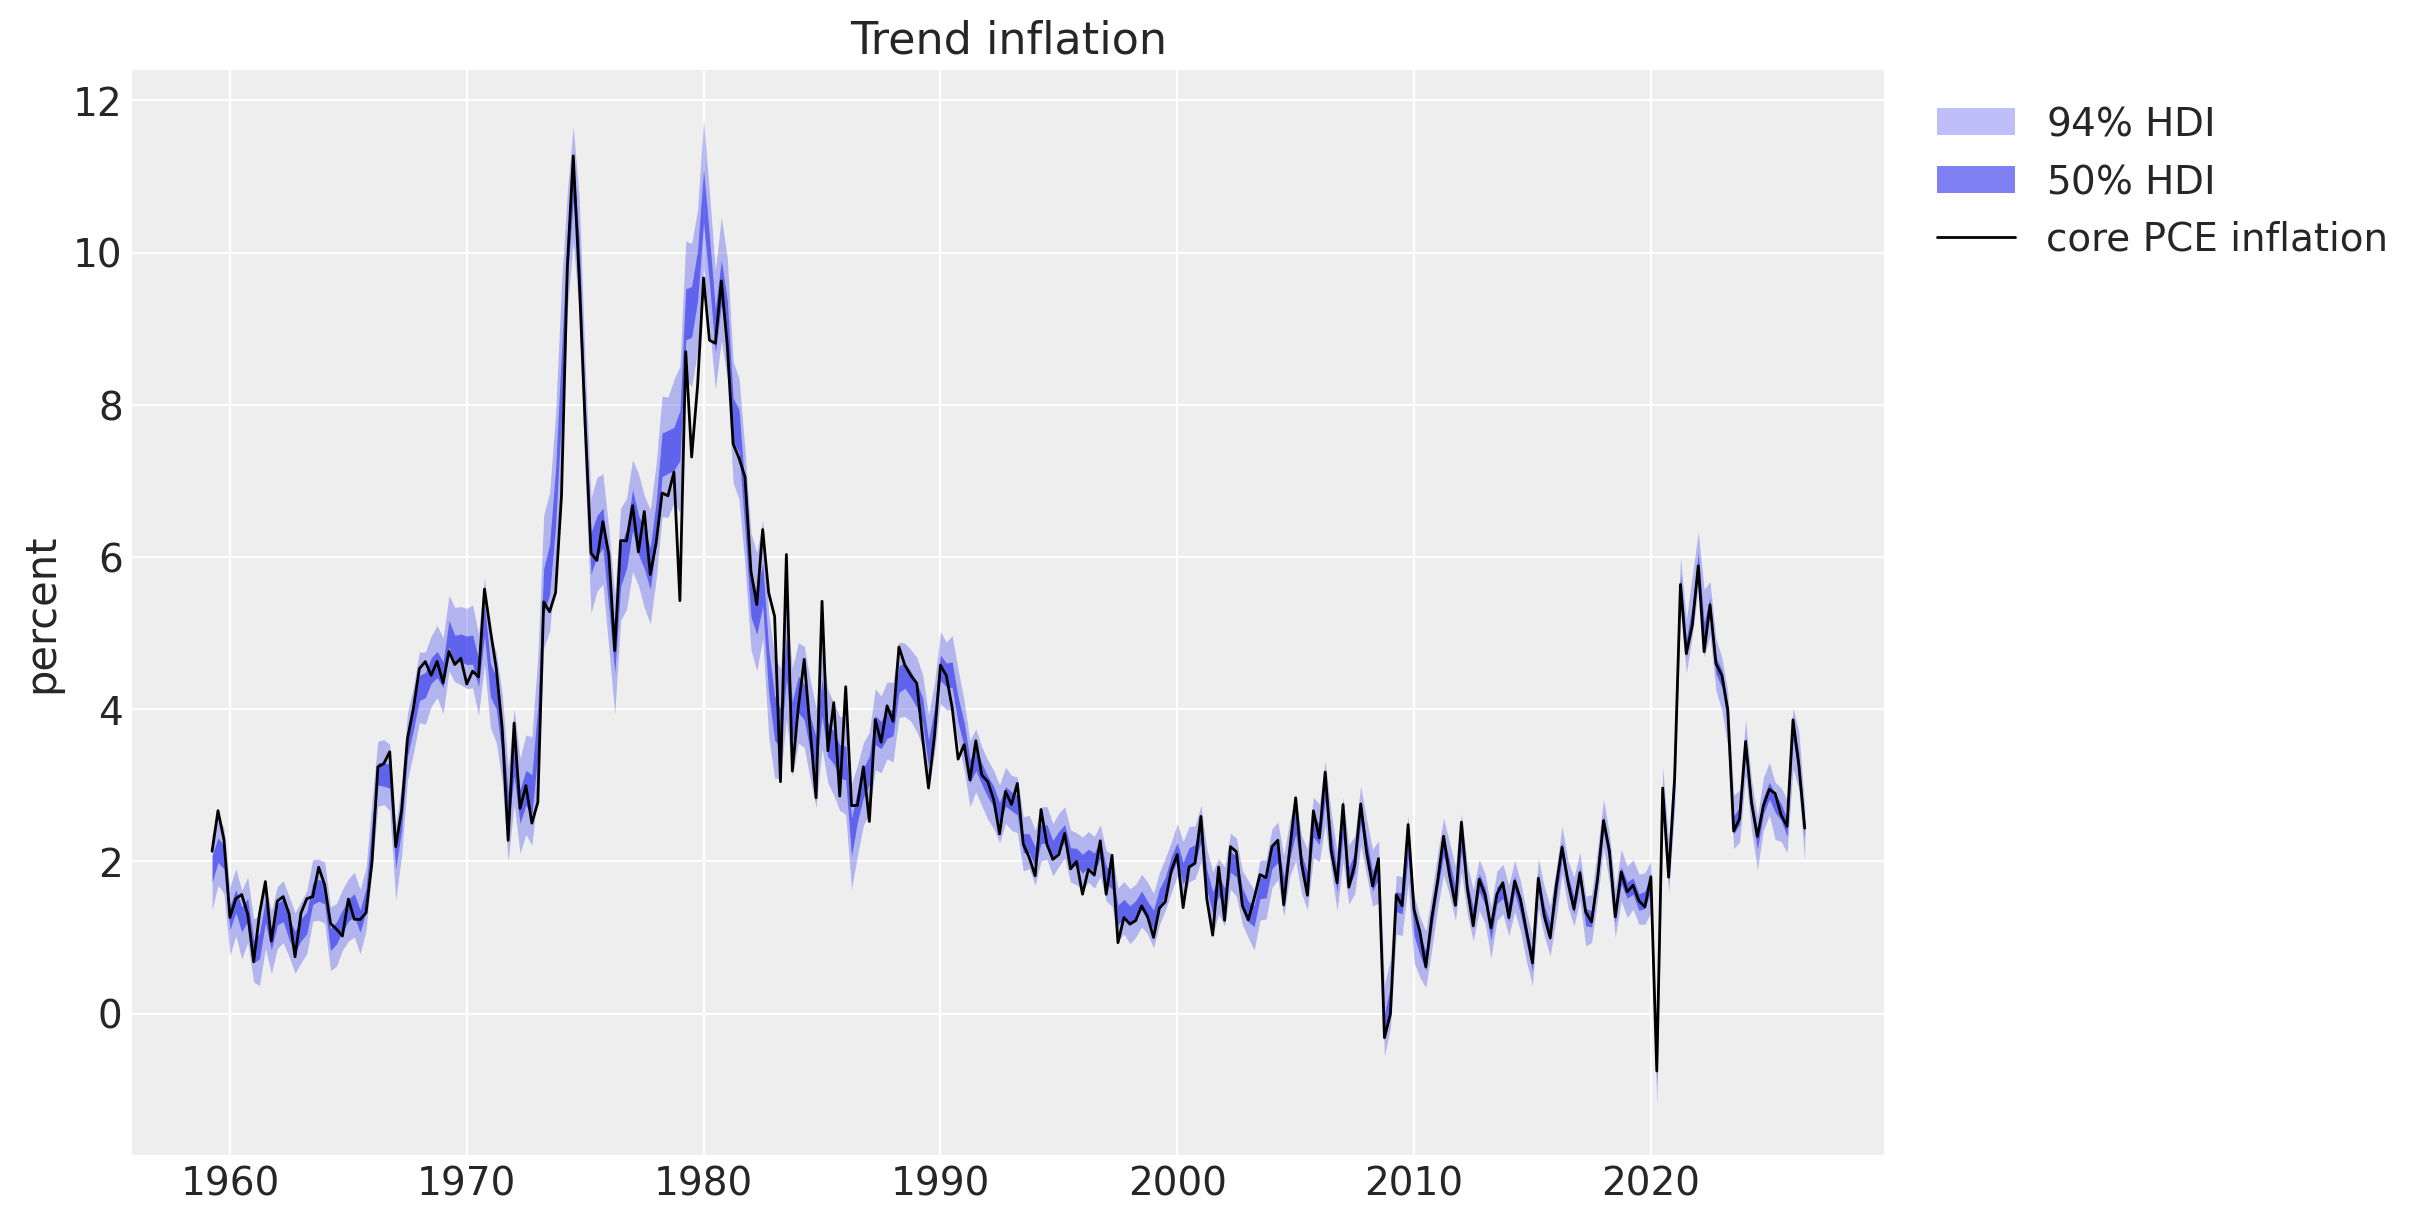

In [12]:
trend_draws = stack_draws(posterior["trend"])  # (samples, quarters, 1)
pc, band_handles = plot_bands(trend_draws, date_num, ["trend"])
ax = pc.viz["figure"].item().axes[0]
(core_line,) = ax.plot(date_num, rates[:, -1], color="black", lw=1, label="core PCE inflation")
ax.legend(handles=[*band_handles, core_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(title="Trend inflation", ylabel="percent");

Takeaway, to be read from the figure after execution.

## Volatilities

The model has five volatility paths: one for the trend shock and one per measure for the gap. The trend volatility says how fast the persistent part of inflation can move in a quarter; the gap volatilities say how noisy each measure is around the trend at each date.

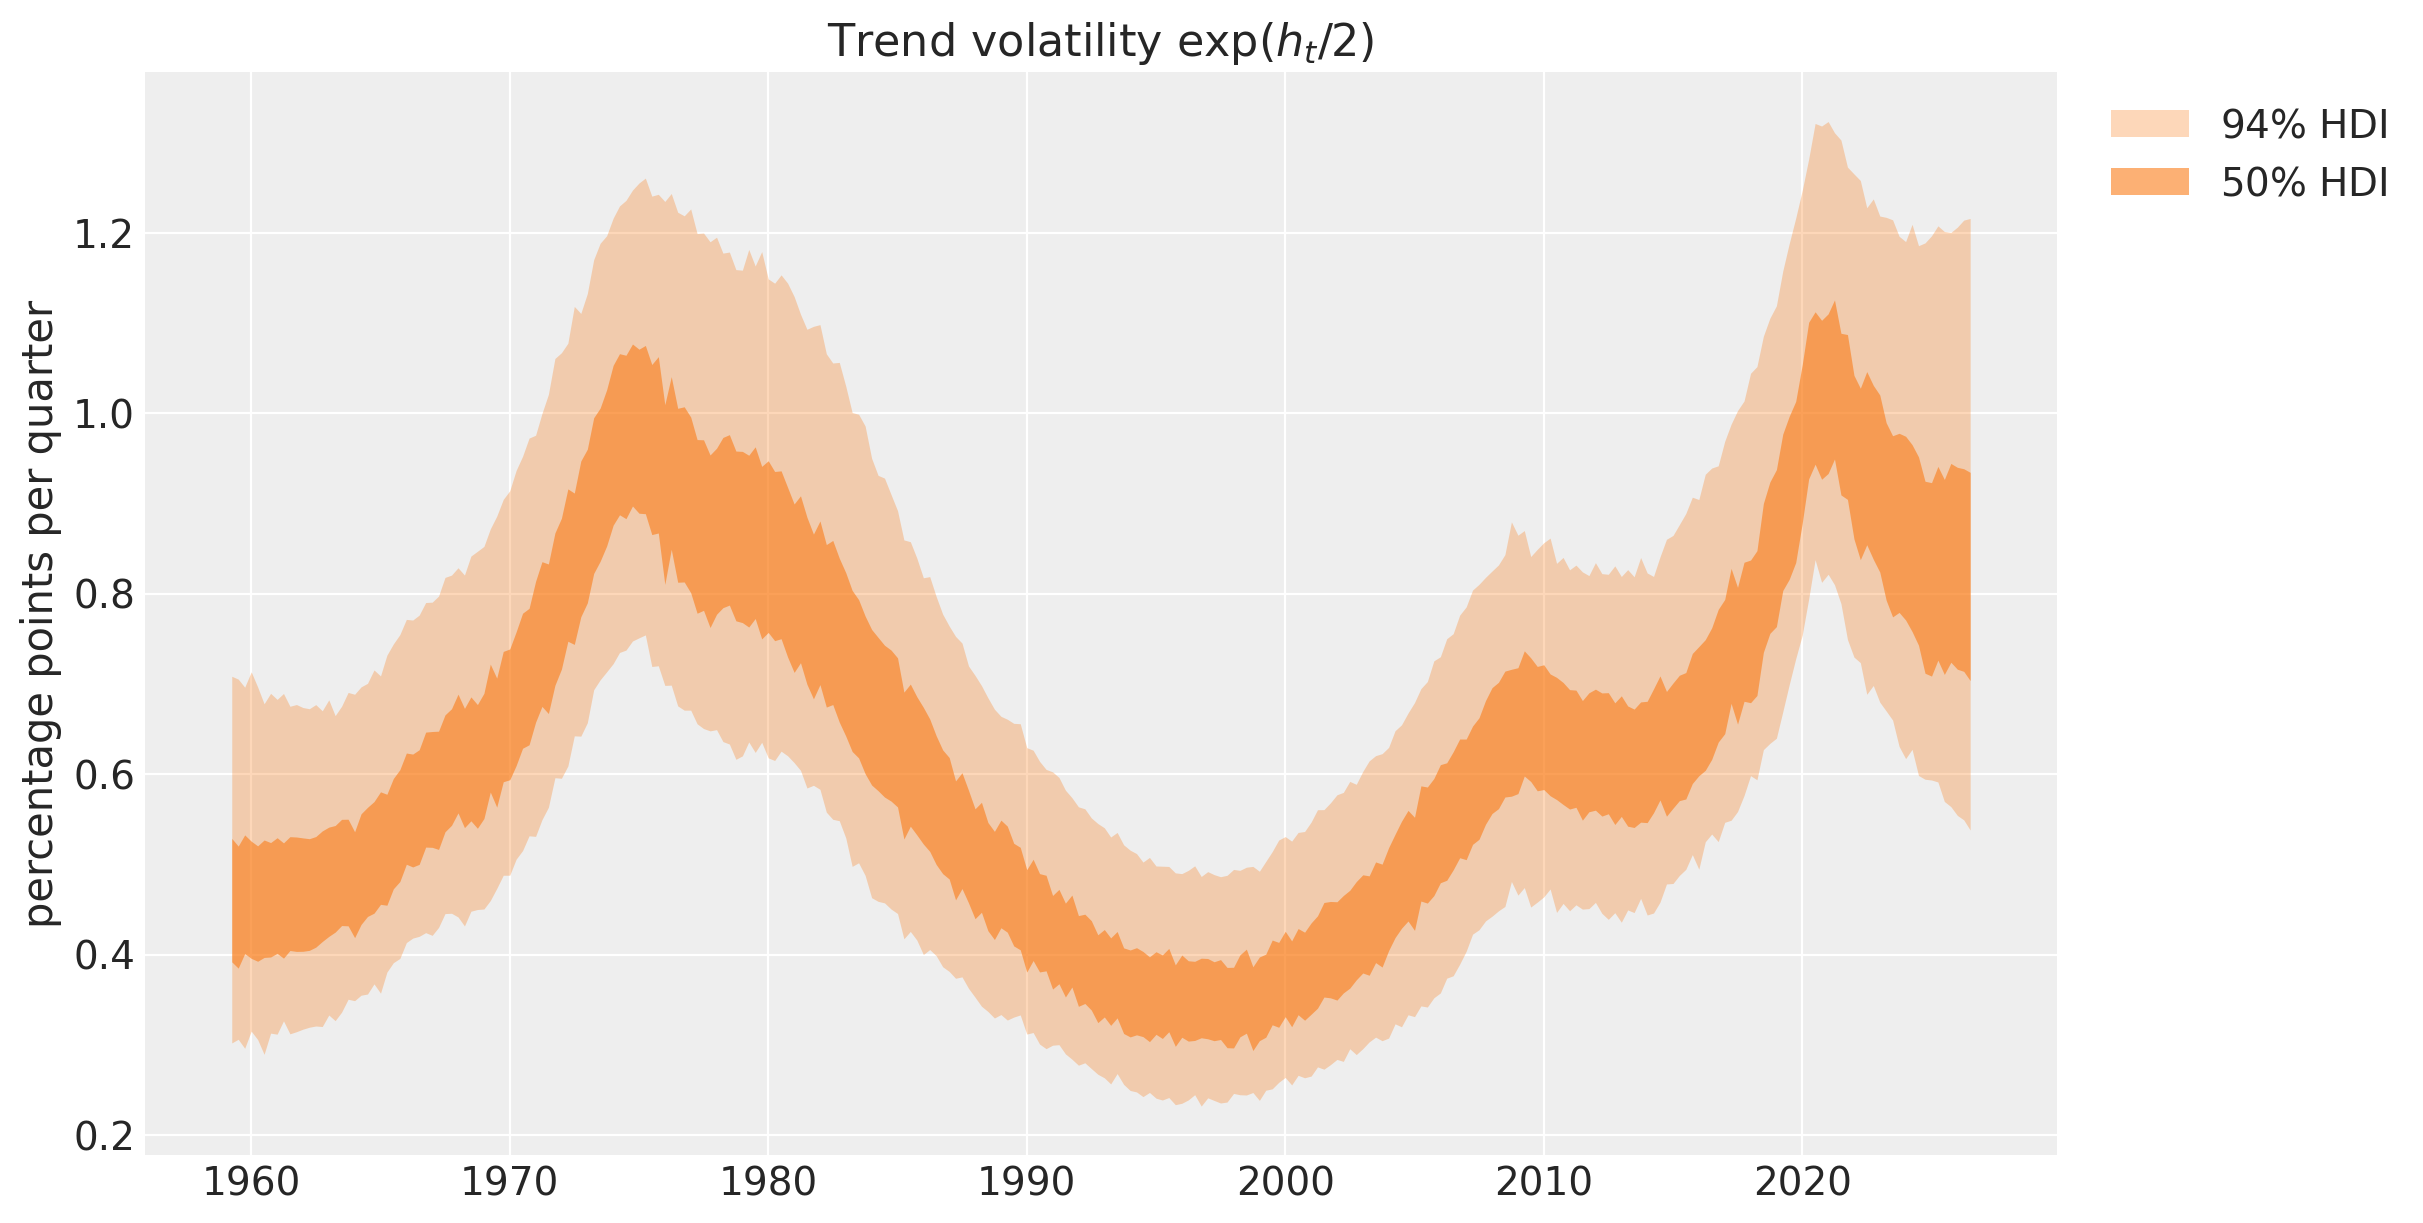

In [13]:
trend_vol_draws = stack_draws(posterior["trend_vol"])  # (samples, quarters, 1)
pc, band_handles = plot_bands(trend_vol_draws, date_num, ["trend volatility"], color="C1")
ax = pc.viz["figure"].item().axes[0]
ax.legend(handles=band_handles, loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(title=r"Trend volatility $\exp(h_t / 2)$", ylabel="percentage points per quarter");

Takeaway, to be read from the figure after execution.

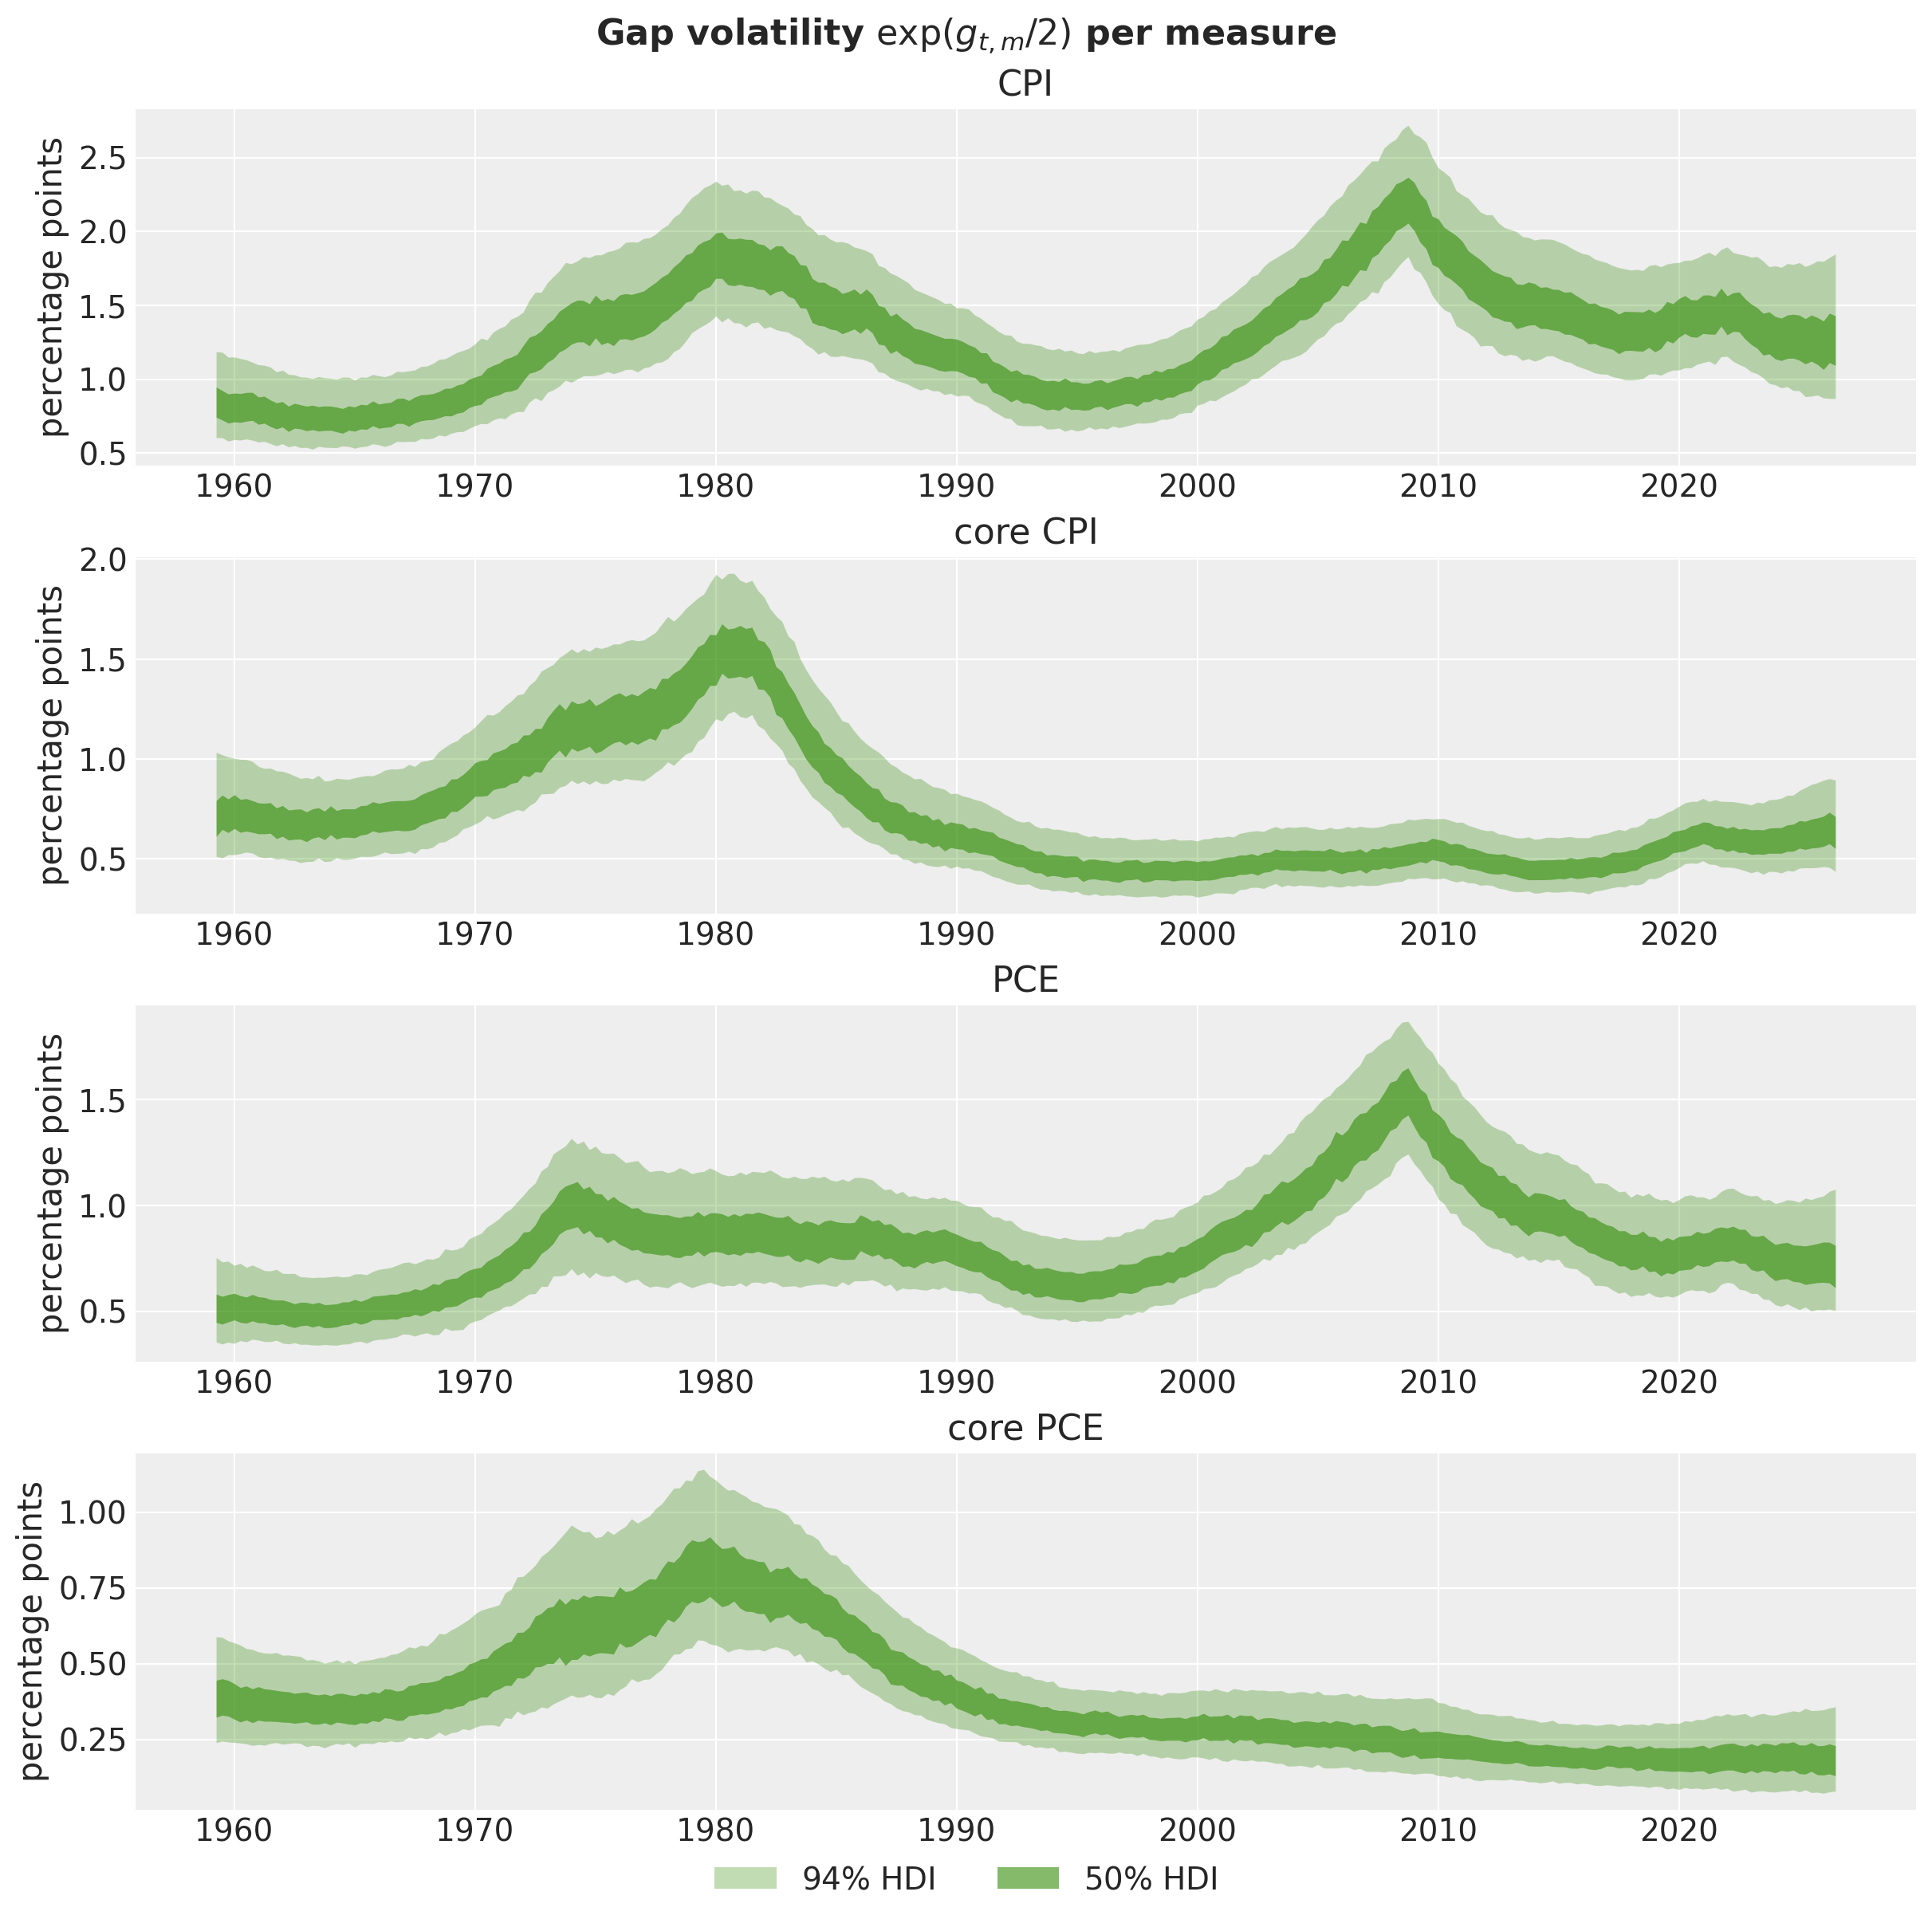

In [14]:
gap_vol_draws = stack_draws(posterior["gap_vol"])  # (samples, quarters, measures)
pc, band_handles = plot_bands(
    gap_vol_draws, date_num, list(measure_labels), color="C2", figsize=(12, 12)
)
fig = pc.viz["figure"].item()

for ax, label in zip(fig.axes, measure_labels, strict=True):
    ax.set(title=label, ylabel="percentage points")

fig.legend(handles=band_handles, loc="outside lower center", ncols=2)
fig.suptitle(r"Gap volatility $\exp(g_{t, m} / 2)$ per measure", fontsize=16, fontweight="bold");

Takeaway, to be read from the figure after execution.

## Measure offsets

The offsets are the average wedge of each measure over core PCE in percentage points, the level difference that the trend does not carry.

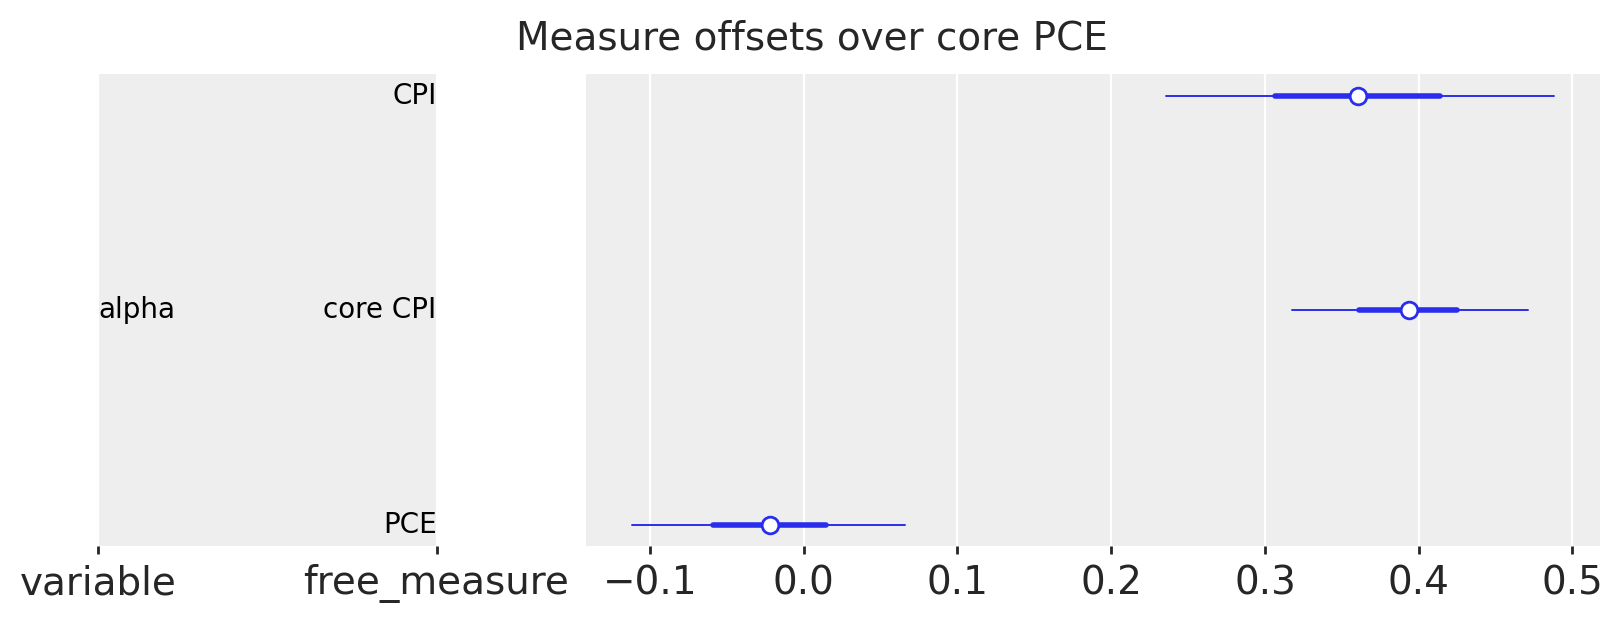

In [15]:
pc = az.plot_forest(tree, var_names=["alpha"], combined=True, figure_kwargs={"figsize": (8, 3)})
pc.viz["figure"].item().suptitle("Measure offsets over core PCE", fontsize=14);

Takeaway, to be read from the figure after execution.

## Forecast

The forecast draws the eight future steps of every random walk from the prior of the steps (unit normals) and pushes them through the posterior of the paths at the last observation, so the trend continues from its last level with its last volatility, and each gap keeps its last scale. `export` already drew the forecast, because `covariates_full` has eight rows more than the data; the `predictions` group of the tree holds it. We plot the last forty quarters of core PCE: the in-sample band is the **smoothed fit**, the posterior predictive given the whole sample, and the forecast band is the predictive from the last observation onward.

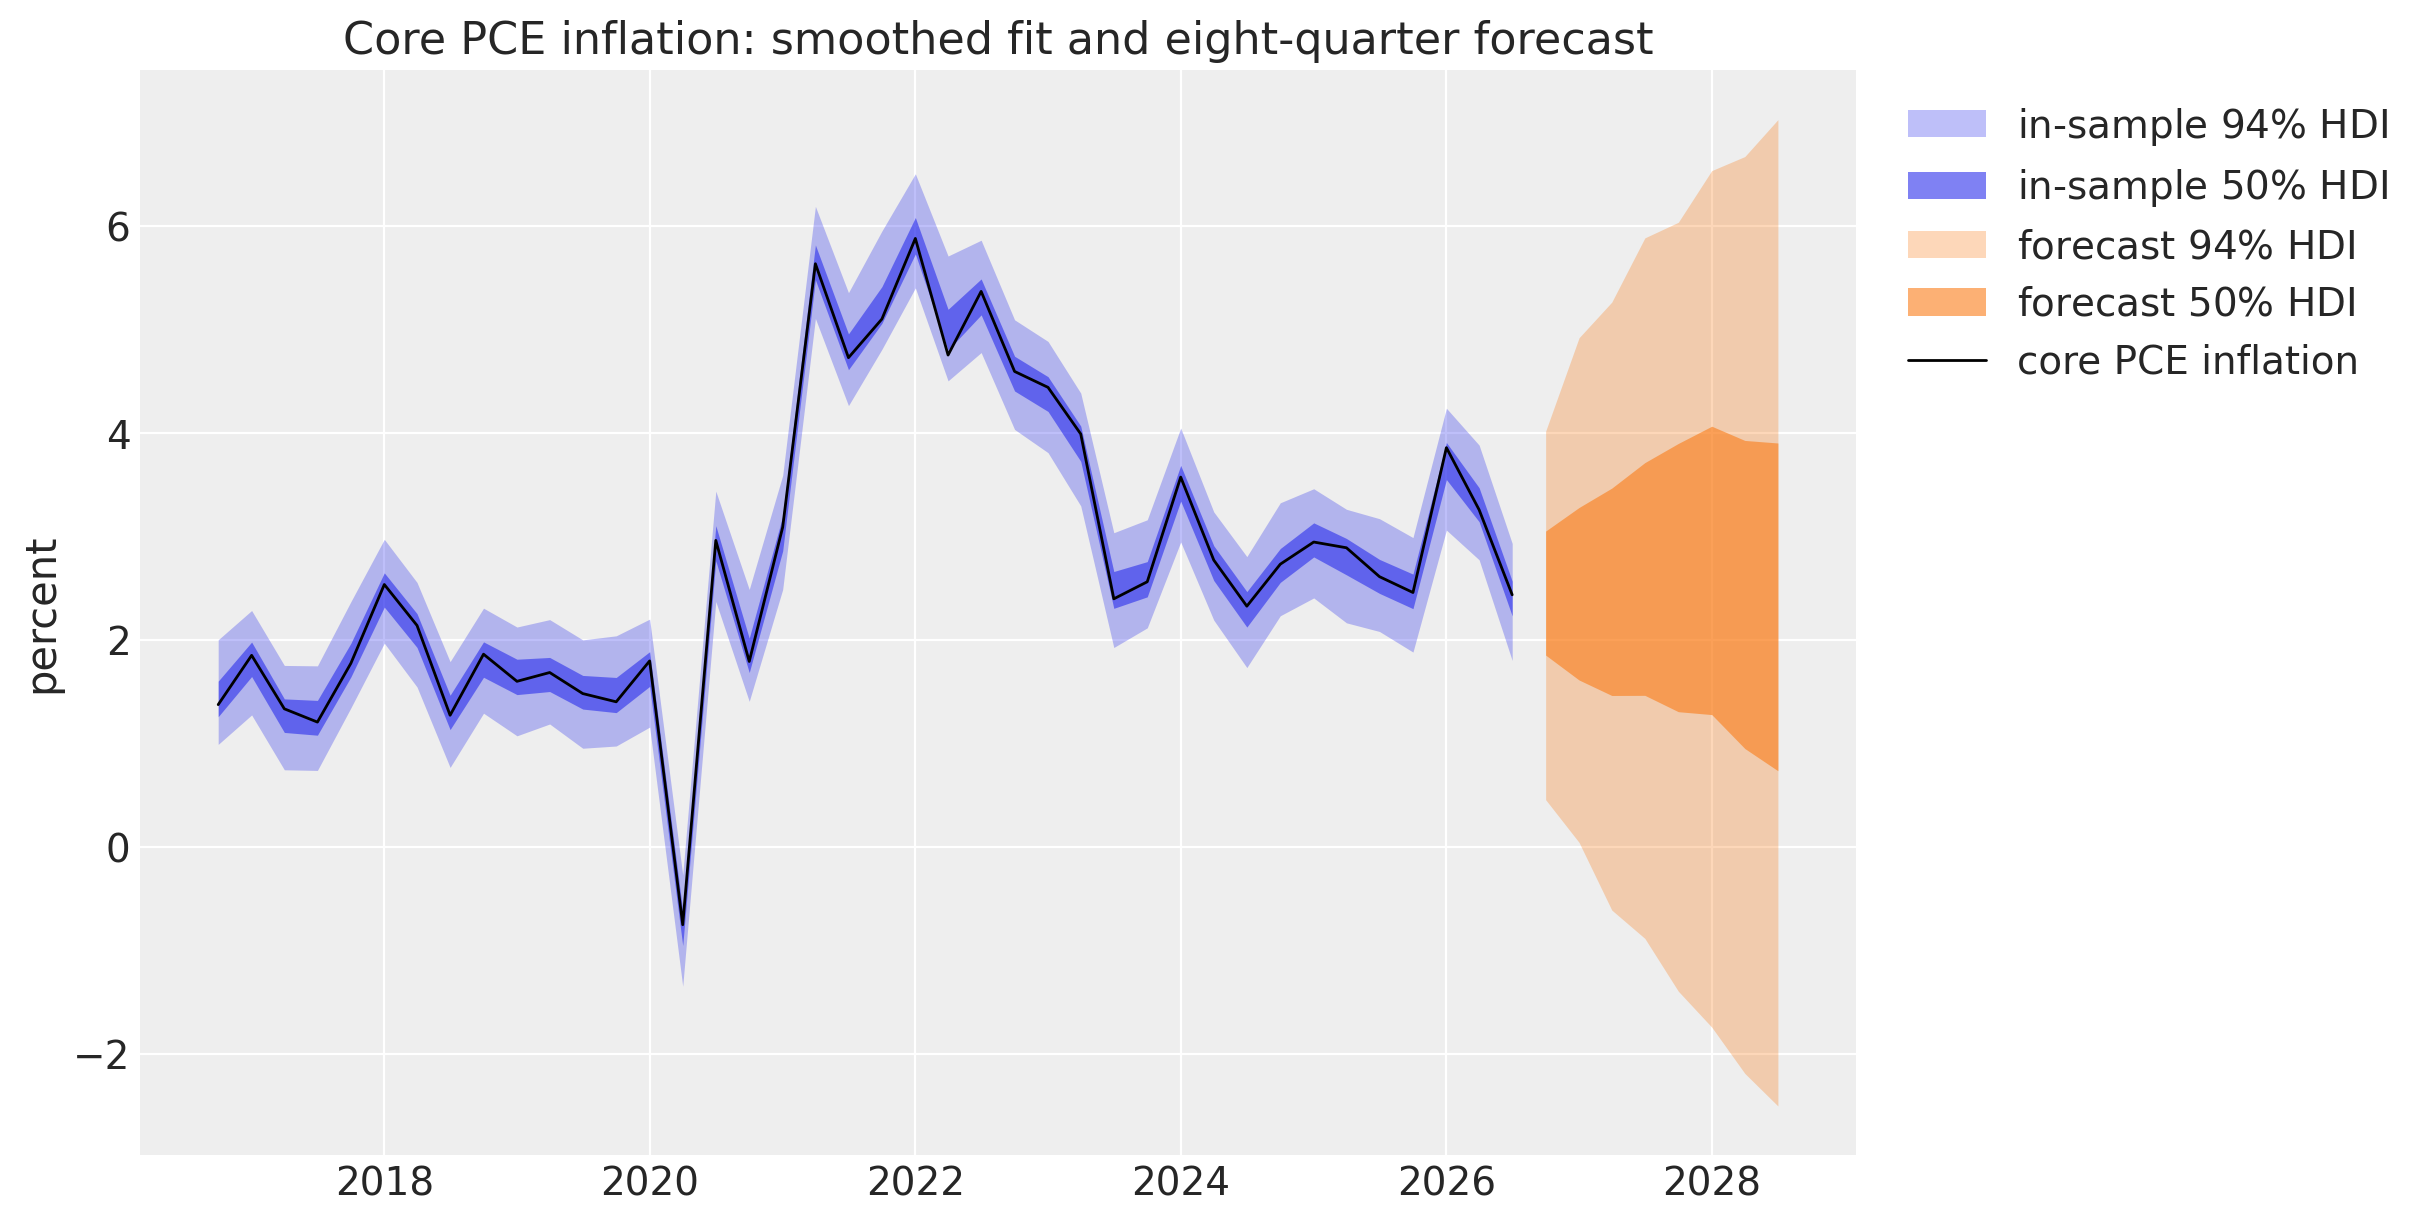

In [16]:
plot_start = num_quarters - 40
in_sample_draws = stack_draws(tree["posterior_predictive"]["obs"].sel(measure="core PCE"))
forecast_draws = stack_draws(tree["predictions"]["obs"].sel(measure="core PCE"))

pc, band_handles = plot_bands(
    in_sample_draws[:, plot_start:, None], date_num[plot_start:], ["core PCE"], label="in-sample "
)
az.plot_lm(
    predictions_to_datatree(forecast_draws[:, :, None], future_date_num, ["core PCE"]),
    y="obs",
    x="t",
    plot_dim="time",
    plot_collection=pc,
    ci_kind="hdi",
    ci_prob=HDI_PROBS,
    smooth=False,
    visuals={
        "ci_band": {"color": "C1"},
        "observed_scatter": False,
        "pe_line": False,
        "xlabel": False,
        "ylabel": False,
    },
)

for prob in HDI_PROBS:
    band = pc.viz["ci_band"]["t"].sel(prob=prob).item()
    band.set_label(f"forecast {hdi_label(prob)}")
    band_handles.append(band)

ax = pc.viz["figure"].item().axes[0]
(core_line,) = ax.plot(
    date_num[plot_start:], rates[plot_start:, -1], color="black", lw=1, label="core PCE inflation"
)
ax.legend(handles=[*band_handles, core_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(title="Core PCE inflation: smoothed fit and eight-quarter forecast", ylabel="percent");

Takeaway, to be read from the figure after execution.

## Backtest

A single forecast from the last observation says nothing about how good the model is. We run a rolling-origin evaluation with [`backtest`](../../reference/evaluate.backtest.html): the first forecast origin is 1985Q1, every fourth quarter after it is another origin, the training window expands from the start of the sample to the origin (so each fit uses all the revised data up to that date), and the horizon is eight quarters. That is 40 windows, the last one with origin 2024Q1, and the forecasts cover 1985 to 2025: the end of the Great Moderation, the 2008 recession, the long undershoot of the 2010s and the 2021 surge.

The ladder has four models, each adding one component to the previous one, and the benchmark:

- **AO**: the Atkeson and Ohanian random walk, a point forecast.
- **M0**: core PCE only, constant variances (`num_measures=1`, `stochastic_volatility=False`).
- **M1**: core PCE only, stochastic volatility: the UCSV model of Stock and Watson (2007).
- **M2**: all four measures, stochastic volatility: the model of this notebook.
- **M2-t**: M2 with Student-t gaps.

Every window fits the model with four NUTS chains of $1{,}000$ warmup and $250$ draws, so that a window takes a fraction of the full fit while the metrics still see $1{,}000$ forecast draws. `forecast_fn` records the divergences of every window, because a model is only as good as the fits behind its scores. The metrics are the ones of *Evaluation metrics and the benchmark*, all on the core PCE column; `on_core_pce` and `four_quarter_average` turn a package metric into one on that column and on the 4-quarter average, and `atkeson_ohanian` is a per-window metric that reads the last four quarters of the training window through the `per_window_metrics` hook of `backtest`.

In [17]:
BACKTEST_WARMUP = 1_000
BACKTEST_SAMPLES = 1_000
backtest_divergences: list[tuple[str, np.datetime64, int]] = []  # (rung, origin, divergences)


def make_forecast_fn(label: str) -> ForecastFn:
    """Build the ``forecast_fn`` of `backtest` for one rung: a NUTS fit, then `forecast`."""

    def forecast_fn(
        rng_key: Array,
        model: ForecastModel,
        train_data: Array,
        train_covariates: Array,
        full_covariates: Array,
        num_samples: int,
        *,
        batch_size: int | None = None,
    ) -> Array:
        key_fit, key_forecast = random.split(rng_key)
        mcmc, _ = fit_nuts(
            key_fit,
            model,
            train_data,
            num_warmup=BACKTEST_WARMUP,
            num_samples=num_samples // NUM_CHAINS,
        )
        backtest_divergences.append((label, dates[train_data.shape[0]], num_divergences(mcmc)))
        return forecast(
            key_forecast,
            model,
            mcmc.get_samples(),
            train_data,
            full_covariates,
            batch_size=batch_size,
        )

    return forecast_fn


def on_core_pce(metric: Metric) -> Metric:
    """Score ``metric`` on the core PCE column (the last one) only."""

    def scored(pred: Array, truth: Array) -> Array:
        return metric(pred[..., -1:], truth[..., -1:])

    return scored


def four_quarter_average(metric: Metric) -> Metric:
    """Score ``metric`` on the average of the first four quarters of core PCE."""

    def scored(pred: Array, truth: Array) -> Array:
        return metric(pred[:, :4, -1].mean(axis=-1), truth[:4, -1].mean())

    return scored


def atkeson_ohanian(train: Array) -> tuple[Metric, Metric]:
    """MAE of the Atkeson and Ohanian forecast, on the quarterly rates and on the 4-quarter average.

    The forecast is the mean core PCE inflation of the last four quarters of ``train``, held
    flat over the horizon; ``pred`` is ignored.
    """
    point = train[-4:, -1].mean()

    def quarterly(pred: Array, truth: Array) -> Array:
        return jnp.abs(truth[:, -1] - point).mean()

    def annual(pred: Array, truth: Array) -> Array:
        return jnp.abs(truth[:4, -1].mean() - point)

    return quarterly, annual


def benchmark_metrics(t0: int, t1: int, t2: int) -> dict[str, Metric]:
    """Return the two Atkeson and Ohanian scores of the window ``(t0, t1, t2)``."""
    quarterly, annual = atkeson_ohanian(rates[t0:t1])
    return {"mae_ao": quarterly, "mae_4q_ao": annual}


METRICS = {
    "crps": on_core_pce(eval_crps),
    "mae": on_core_pce(eval_mae),
    "coverage_50": on_core_pce(partial(eval_coverage, alpha=0.5)),
    "coverage_94": on_core_pce(partial(eval_coverage, alpha=0.94)),
    "crps_4q": four_quarter_average(eval_crps),
    "mae_4q": four_quarter_average(eval_mae),
}
BACKTEST_OPTIONS = {
    "min_train_window": 103,  # first origin 1985Q1
    "test_window": HORIZON,
    "stride": 4,
    "num_samples": BACKTEST_SAMPLES,
    "metrics": METRICS,
    "per_window_metrics": benchmark_metrics,
    "keep_predictions": True,
}

assert dates[BACKTEST_OPTIONS["min_train_window"]] == np.datetime64("1985-01-01")


def run_backtest(
    rng_key: Array, label: str, model_fn: ModelFactory, data: Array
) -> list[BacktestResult]:
    """Backtest one rung of the ladder on ``data`` with the shared window settings."""
    return backtest(
        rng_key,
        model_fn,
        data,
        jnp.zeros((data.shape[0], 0)),
        forecast_fn=make_forecast_fn(label),
        **BACKTEST_OPTIONS,
    )

In [18]:
core_pce = rates[:, -1:]  # (quarters, 1): the univariate rungs see core PCE only
LADDER: dict[str, tuple[ModelFactory, Array]] = {
    "M0": (partial(make_trend_inflation_model, 1, stochastic_volatility=False), core_pce),
    "M1": (partial(make_trend_inflation_model, 1), core_pce),
    "M2": (partial(make_trend_inflation_model, num_measures), rates),
    "M2-t": (partial(make_trend_inflation_model, num_measures, student_t=True), rates),
}
RUNG_COLORS = {"AO": "C4", "M0": "C1", "M1": "C2", "M2": "C0", "M2-t": "C3"}
backtest_results: dict[str, list[BacktestResult]] = {}

for label, (model_fn, data) in LADDER.items():
    rng_key, key_backtest = random.split(rng_key)
    backtest_results[label] = run_backtest(key_backtest, label, model_fn, data)

origins = np.array([dates[result.t1] for result in backtest_results["M2"]])

assert len(origins) == 40

The first figure is the summary: every metric averaged over the 40 windows, one bar per rung, with the Atkeson and Ohanian benchmark as a line in the MAE panels.

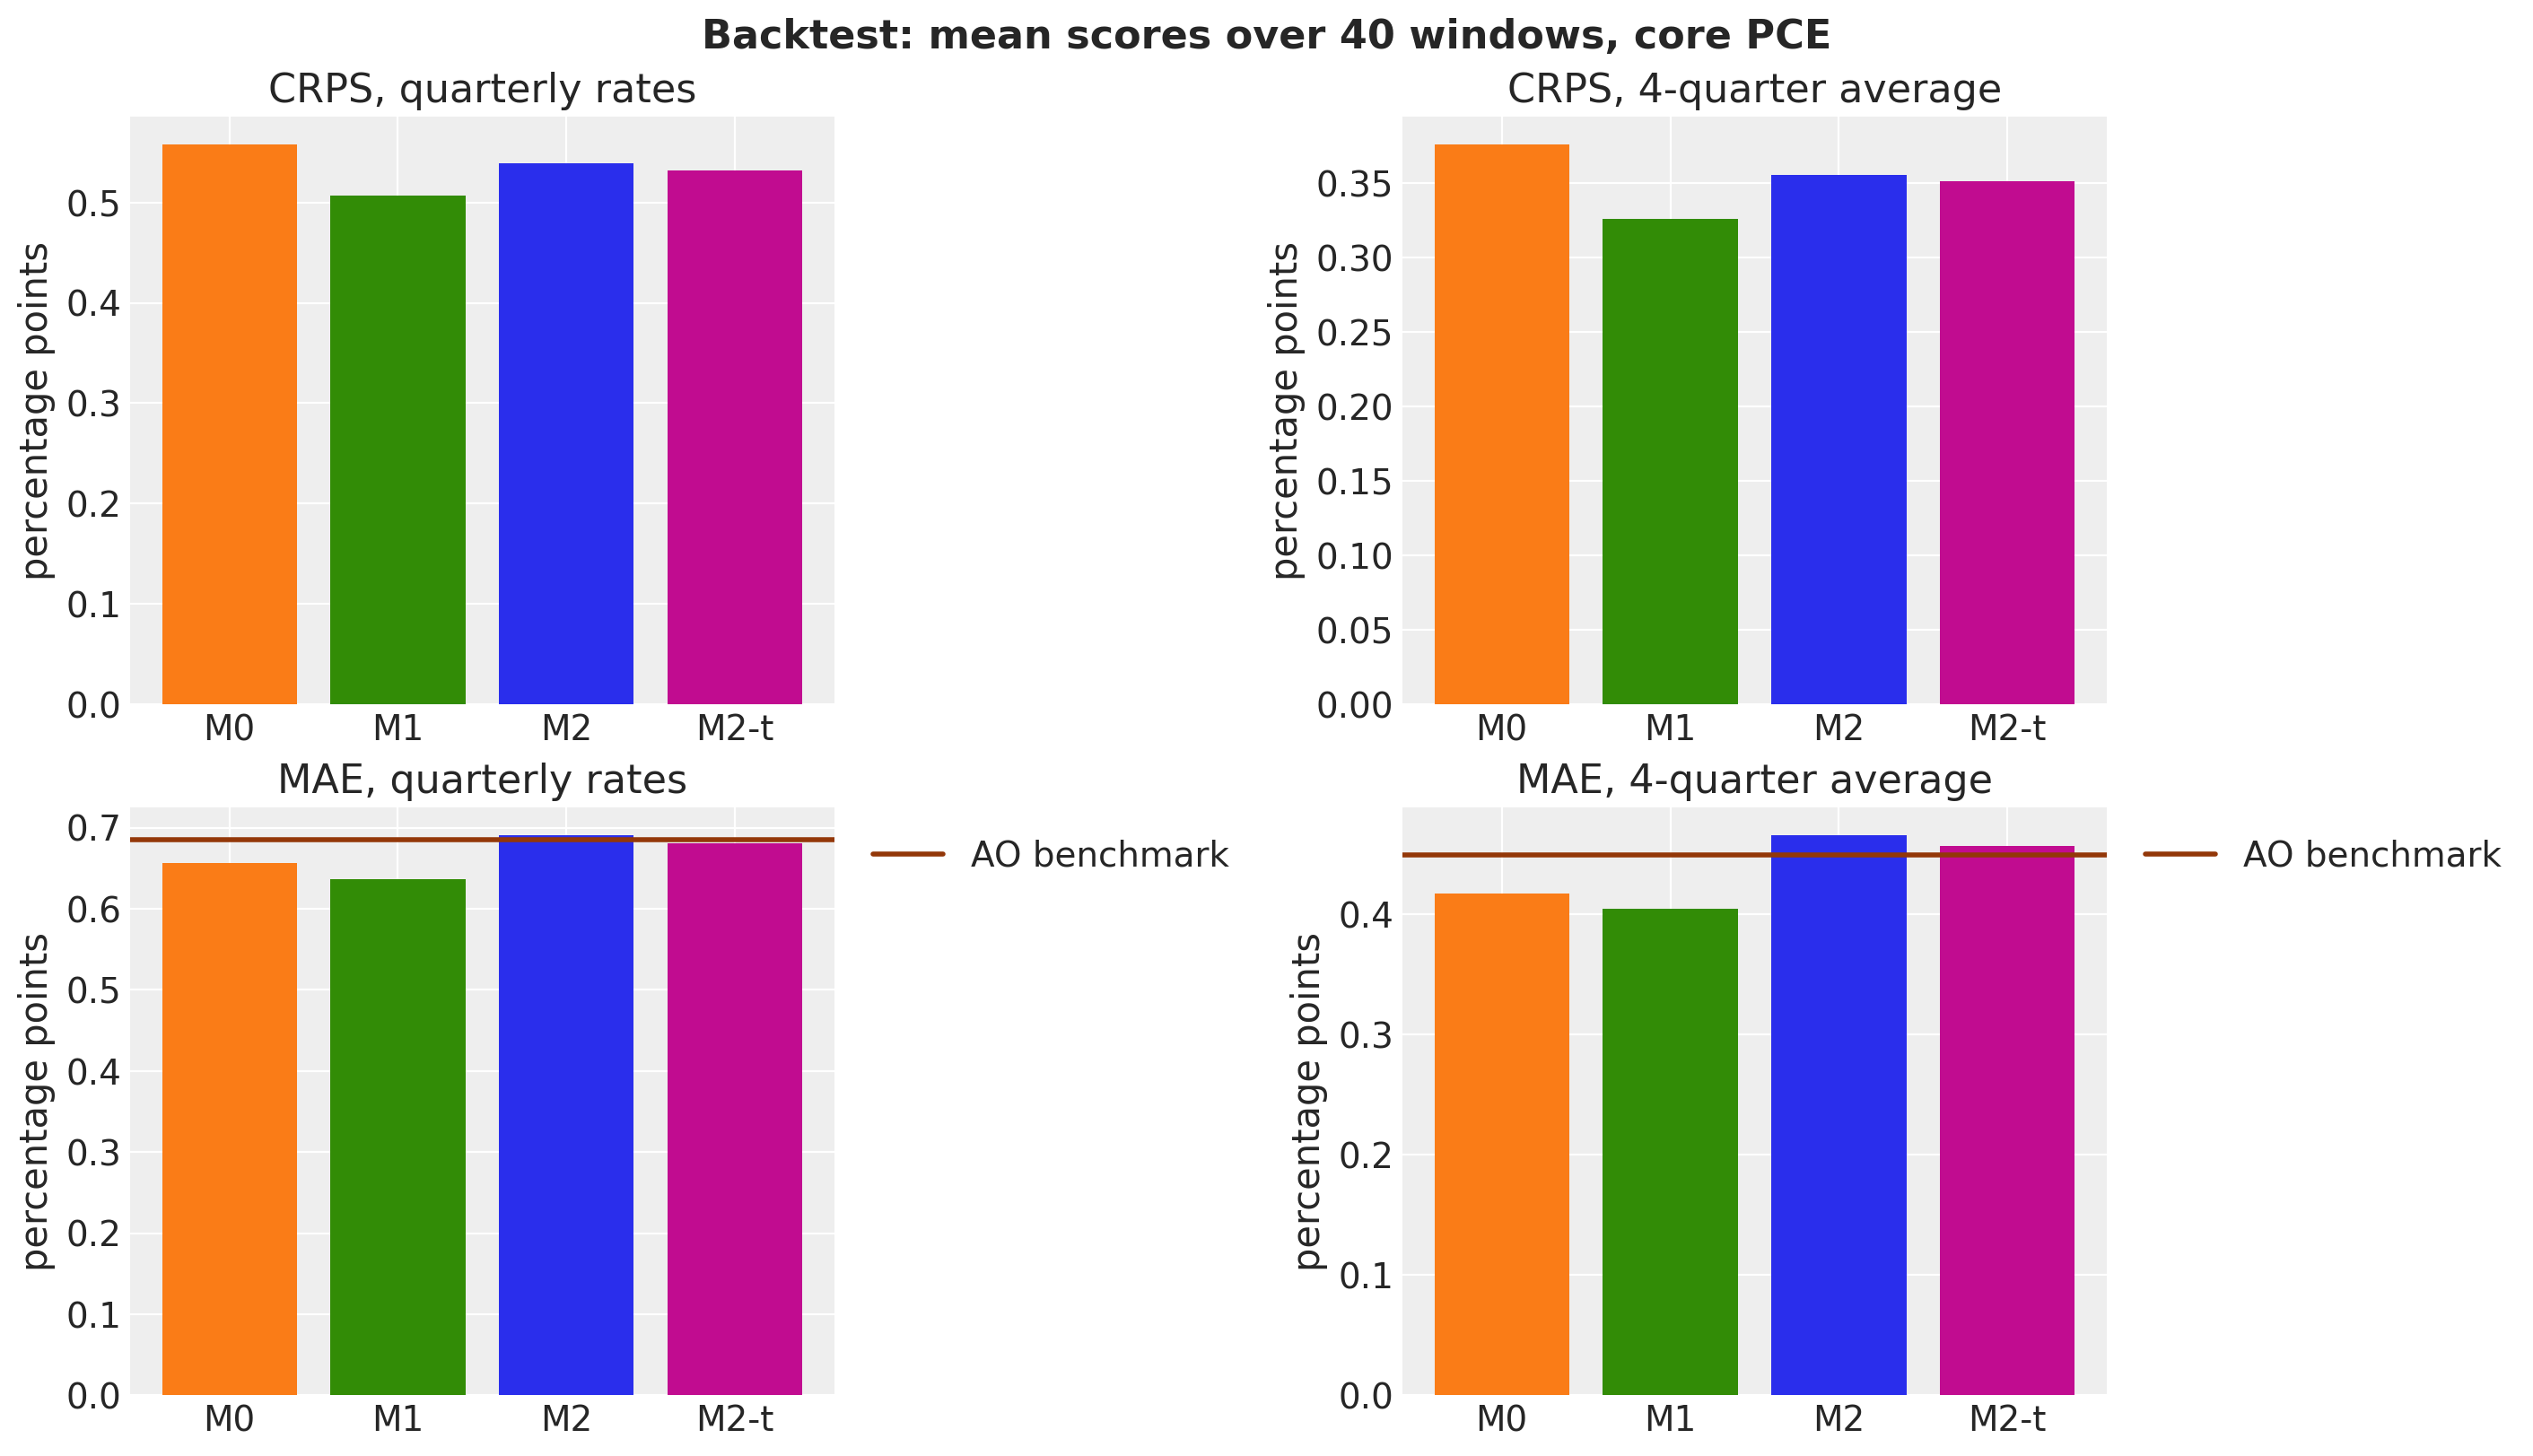

In [19]:
def metric_values(results: list[BacktestResult], metric: str) -> np.ndarray:
    """Return the per-window values of ``metric`` from ``results``, shape ``(windows,)``."""
    return np.array([result.metrics[metric] for result in results])


def plot_rung_bars(ax: plt.Axes, metric: str, title: str, benchmark: str | None = None) -> None:
    """Bar chart of the window mean of ``metric`` per rung, with the benchmark as a line."""
    labels = list(backtest_results)
    means = [metric_values(backtest_results[label], metric).mean() for label in labels]
    ax.bar(labels, means, color=[RUNG_COLORS[label] for label in labels])
    if benchmark is not None:
        ax.axhline(
            metric_values(backtest_results["M0"], benchmark).mean(),
            color=RUNG_COLORS["AO"],
            lw=2,
            label="AO benchmark",
        )
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.set(title=title, ylabel="percentage points")


fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 8), layout="constrained")
plot_rung_bars(axes[0, 0], "crps", "CRPS, quarterly rates")
plot_rung_bars(axes[0, 1], "crps_4q", "CRPS, 4-quarter average")
plot_rung_bars(axes[1, 0], "mae", "MAE, quarterly rates", benchmark="mae_ao")
plot_rung_bars(axes[1, 1], "mae_4q", "MAE, 4-quarter average", benchmark="mae_4q_ao")
fig.suptitle("Backtest: mean scores over 40 windows, core PCE", fontsize=16, fontweight="bold");

Takeaway, to be read from the figure after execution.

The means hide where the differences come from. The next figure shows the CRPS of every window against its origin date, one line per rung, so the periods where one component helps stand out.

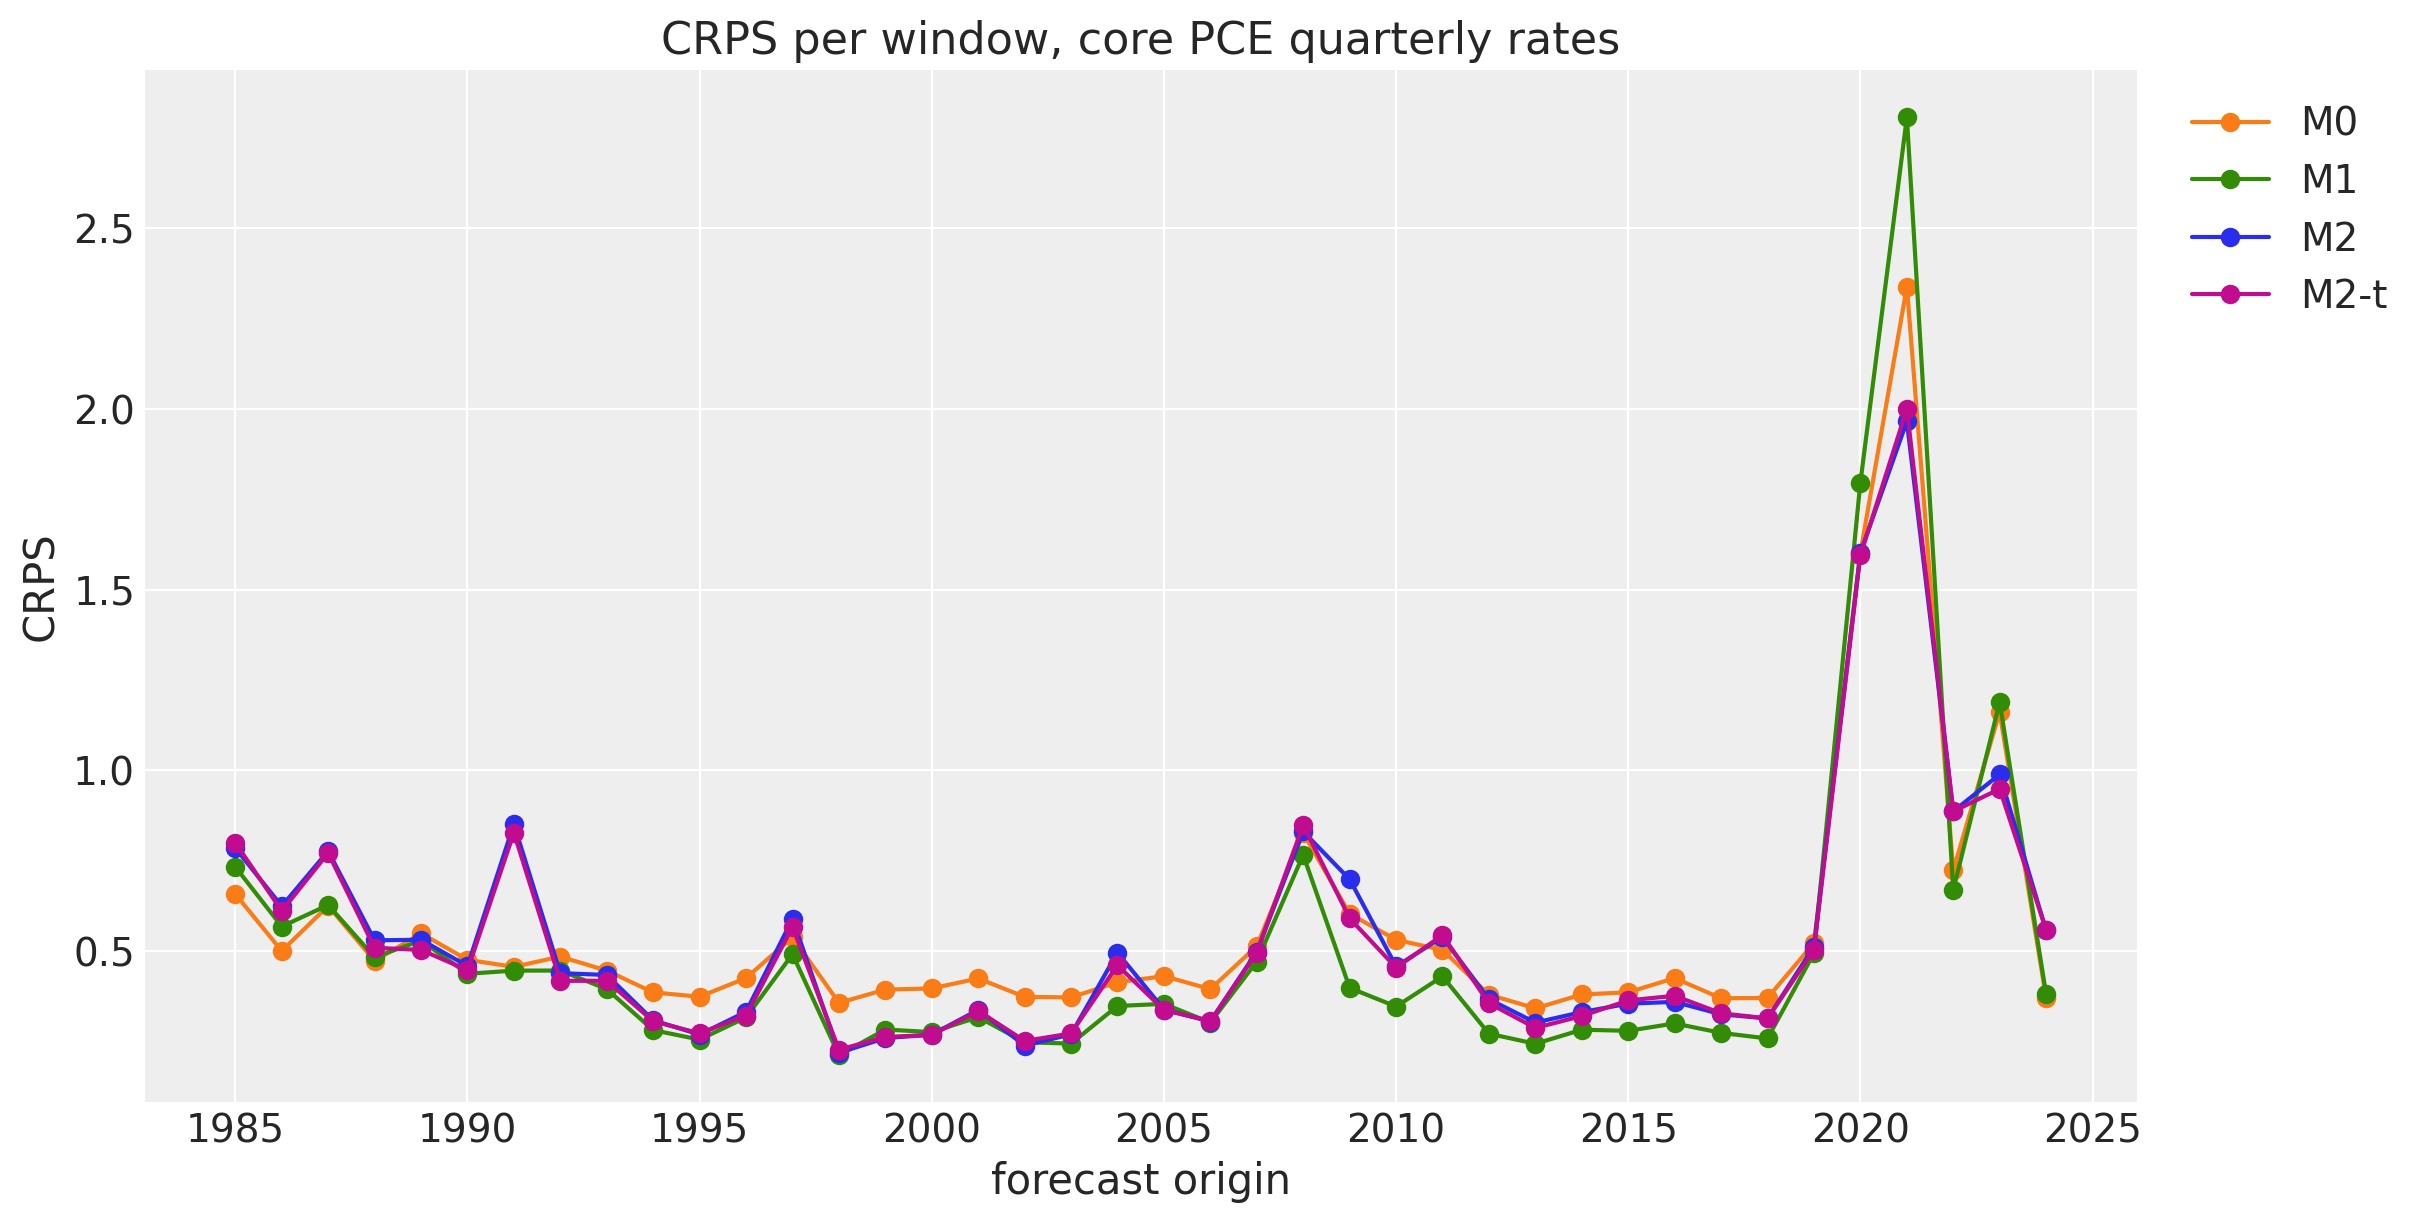

In [20]:
fig, ax = plt.subplots(figsize=(12, 6))

for label, results in backtest_results.items():
    ax.plot(
        origins, metric_values(results, "crps"), marker="o", color=RUNG_COLORS[label], label=label
    )

locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(title="CRPS per window, core PCE quarterly rates", xlabel="forecast origin", ylabel="CRPS");

Takeaway, to be read from the figure after execution.

A difference of means over 40 windows can be noise. For each step of the ladder we take the paired per-window difference in CRPS (the model with the component minus the model without it, on the same windows) and show its mean with two standard errors. The standard error treats the windows as independent; consecutive windows share four of their eight quarters, so it understates the uncertainty, and a bar that reaches zero is a difference the backtest cannot establish.

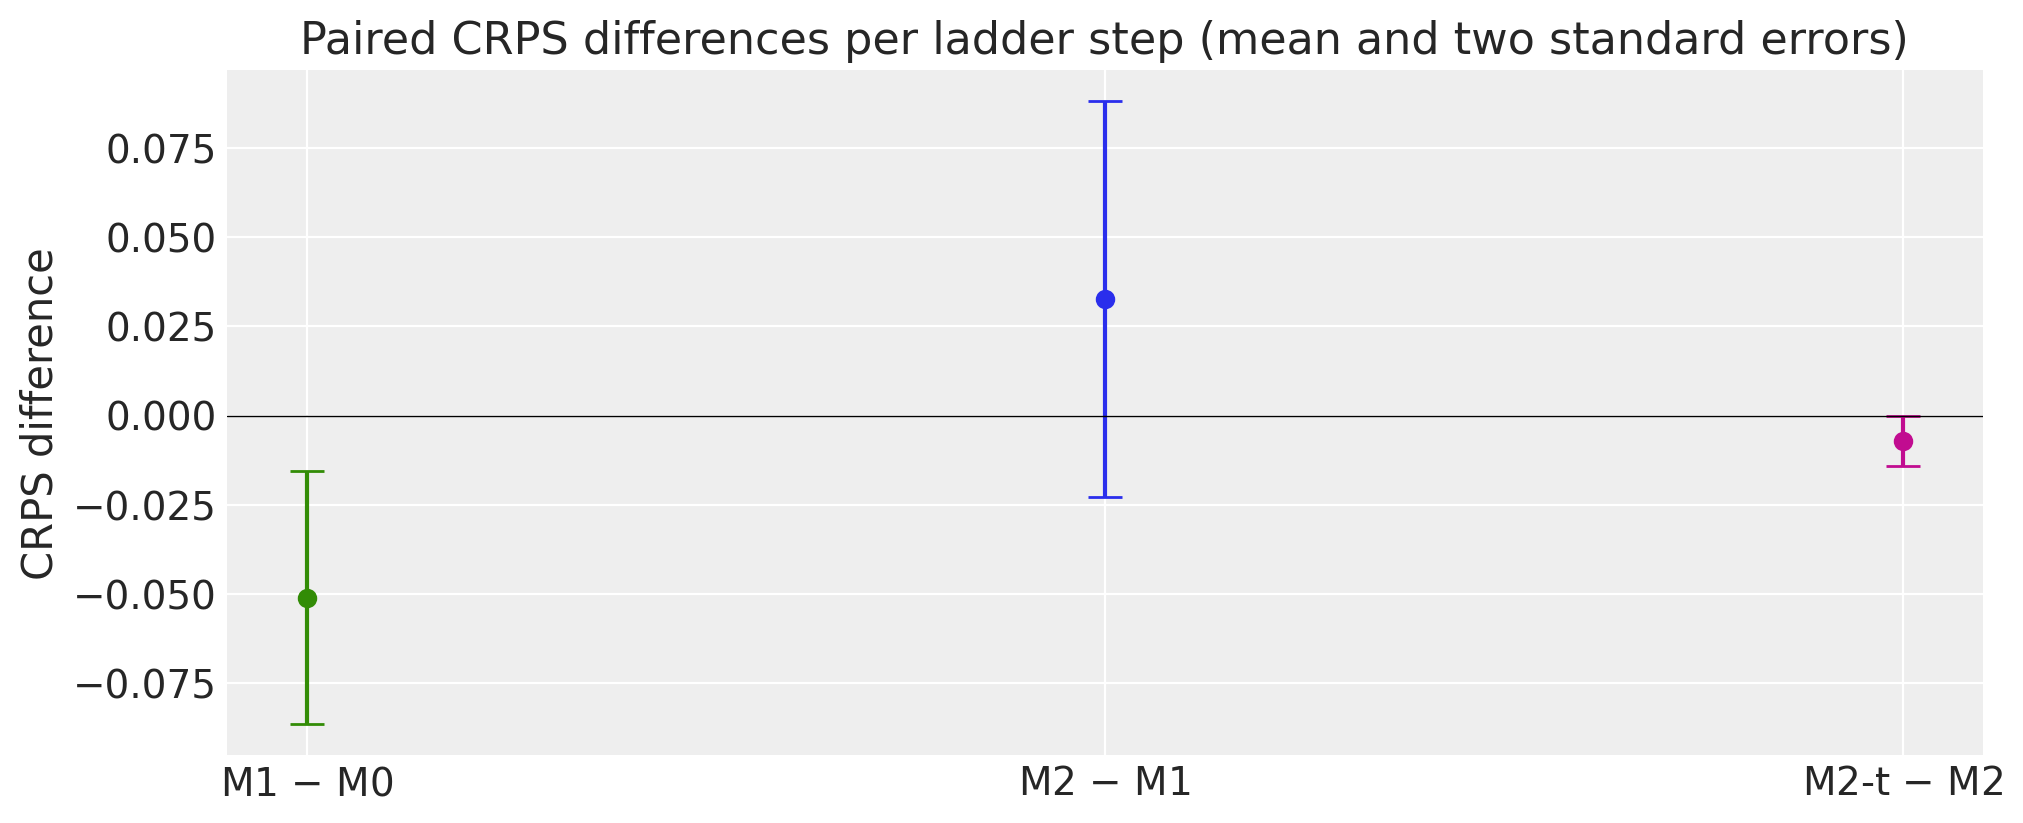

In [21]:
PAIRS = (("M1", "M0"), ("M2", "M1"), ("M2-t", "M2"))

fig, ax = plt.subplots(figsize=(10, 4))

for position, (with_component, without) in enumerate(PAIRS):
    difference = metric_values(backtest_results[with_component], "crps") - metric_values(
        backtest_results[without], "crps"
    )
    ax.errorbar(
        position,
        difference.mean(),
        yerr=2 * difference.std(ddof=1) / np.sqrt(len(difference)),
        fmt="o",
        color=RUNG_COLORS[with_component],
        capsize=6,
    )

ax.axhline(0.0, color="black", lw=0.5)
ax.set(
    xticks=range(len(PAIRS)),
    xticklabels=[f"{a} $-$ {b}" for a, b in PAIRS],
    title="Paired CRPS differences per ladder step (mean and two standard errors)",
    ylabel="CRPS difference",
);

Takeaway, to be read from the figure after execution.

The scores so far average over the eight horizon steps. The stored forecast draws let us score each step on its own: the CRPS at horizon $h$ and the coverage of the two central intervals at horizon $h$, averaged over the windows. Forty windows give one realized value per step, so the coverage of a calibrated forecast scatters around the nominal level with a binomial standard deviation of $\sqrt{0.94 \times 0.06 / 40} \approx 3.8$ percentage points at the $94\%$ level and $7.9$ at the $50\%$ level; the shaded band in the coverage panels is two of those standard deviations around the nominal level.

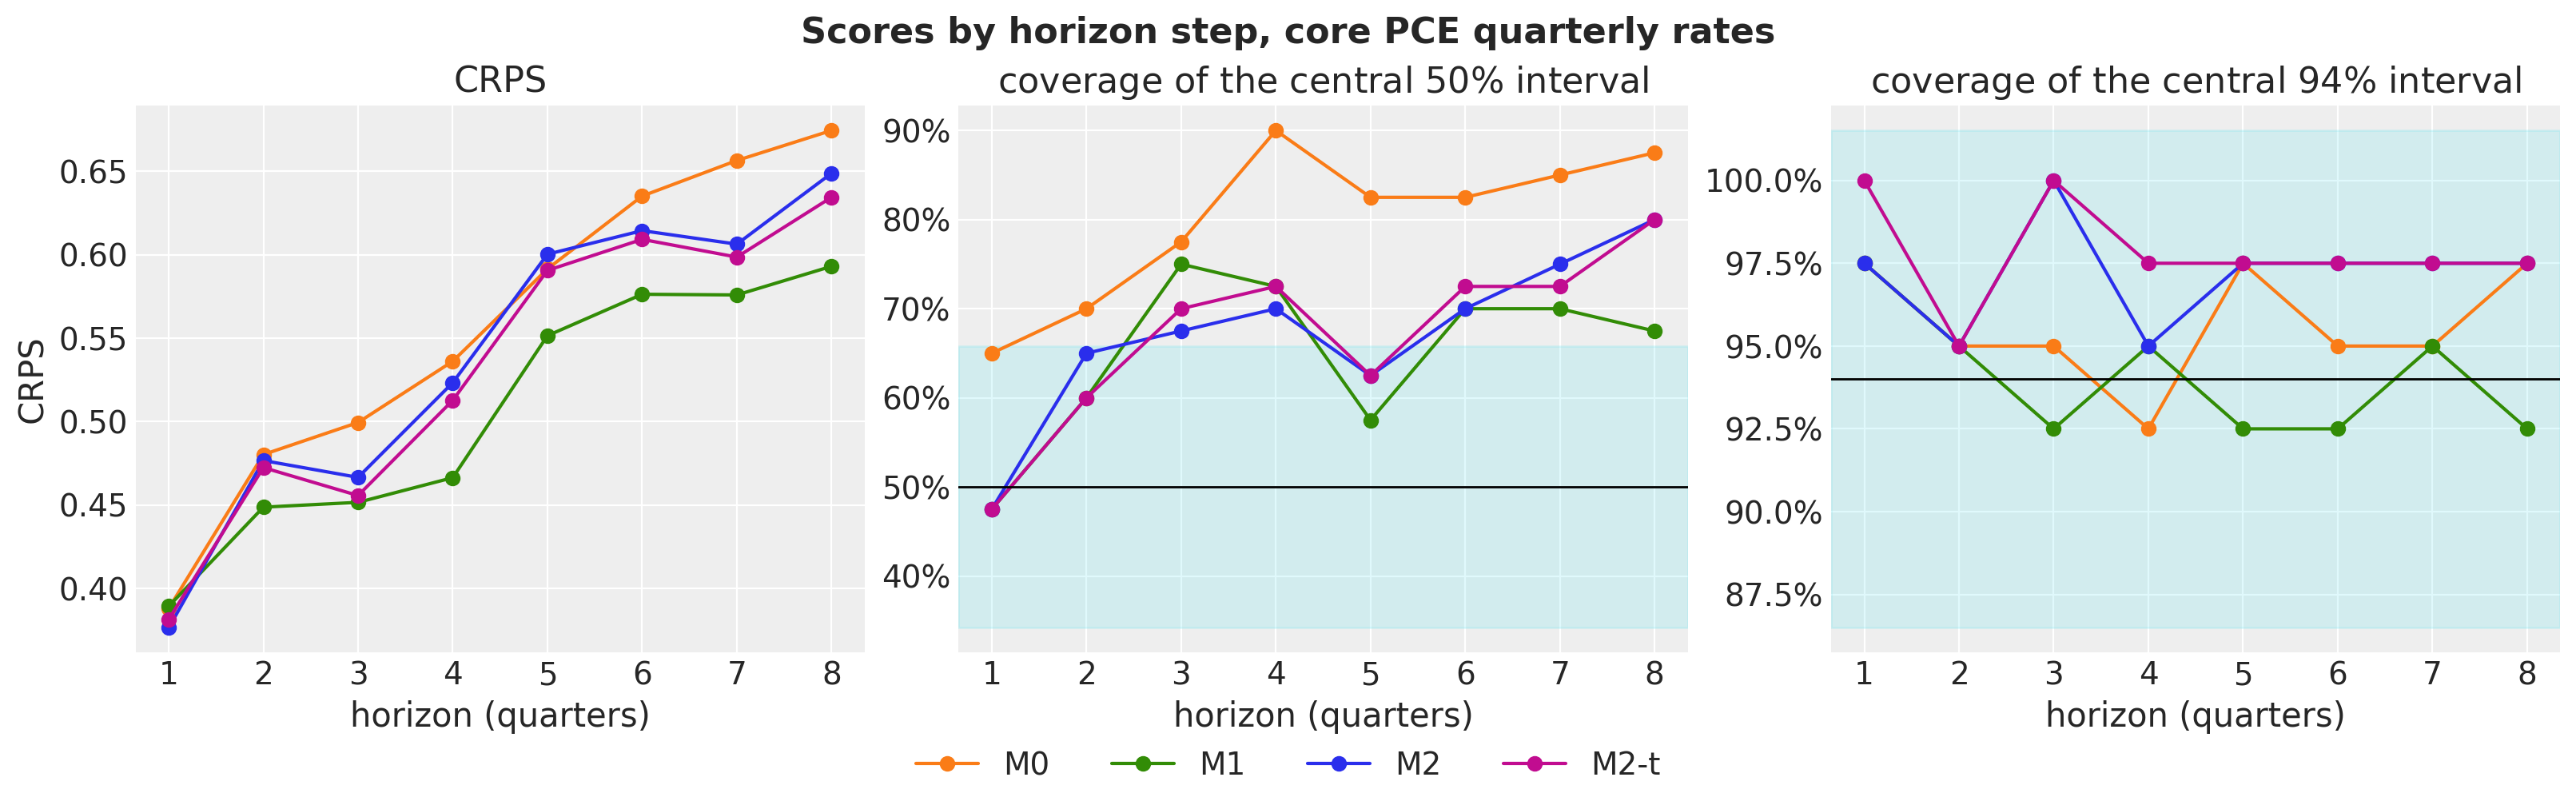

In [22]:
def per_horizon_scores(results: list[BacktestResult]) -> dict[str, np.ndarray]:
    """CRPS and central-interval coverage of core PCE at each horizon step, over the windows."""
    draws = jnp.stack([jnp.asarray(result.prediction)[..., -1] for result in results])  # (w, s, h)
    truth = jnp.stack([rates[result.t1 : result.t2, -1] for result in results])  # (windows, h)
    scores = {"crps": jax.vmap(crps_empirical)(draws, truth).mean(axis=0)}

    for prob in (0.5, 0.94):
        lower = jnp.quantile(draws, (1.0 - prob) / 2.0, axis=1)  # (windows, h)
        upper = jnp.quantile(draws, (1.0 + prob) / 2.0, axis=1)  # (windows, h)
        inside = (truth >= lower) & (truth <= upper)
        scores[f"coverage_{prob:.0%}"] = inside.mean(axis=0)

    return {name: np.asarray(value) for name, value in scores.items()}


horizon_scores = {
    label: per_horizon_scores(results) for label, results in backtest_results.items()
}
horizon_steps = np.arange(1, HORIZON + 1)

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 5), layout="constrained")

for label, scores in horizon_scores.items():
    axes[0].plot(horizon_steps, scores["crps"], marker="o", color=RUNG_COLORS[label], label=label)
    axes[1].plot(horizon_steps, scores["coverage_50%"], marker="o", color=RUNG_COLORS[label])
    axes[2].plot(horizon_steps, scores["coverage_94%"], marker="o", color=RUNG_COLORS[label])

for ax, prob in zip(axes[1:], (0.5, 0.94), strict=True):
    binomial_sd = np.sqrt(prob * (1 - prob) / len(origins))
    ax.axhline(prob, color="black", lw=1)
    ax.axhspan(prob - 2 * binomial_sd, prob + 2 * binomial_sd, color="C5", alpha=0.2)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
    ax.set(title=rf"coverage of the central ${prob:.0%}$ interval".replace("%", r"\%"))

axes[0].set(title="CRPS", ylabel="CRPS")
fig.legend(loc="outside lower center", ncols=len(horizon_scores))

for ax in axes:
    ax.set(xlabel="horizon (quarters)", xticks=horizon_steps)

fig.suptitle("Scores by horizon step, core PCE quarterly rates", fontsize=16, fontweight="bold");

Takeaway, to be read from the figure after execution.

The stored draws also let us look at one origin in detail. 2021Q1 is the origin just before the surge: the last observed quarter is 2020Q4, and the next eight quarters are the fastest core inflation since the early 1980s. We plot the forecast of every rung from that origin against the realized path.

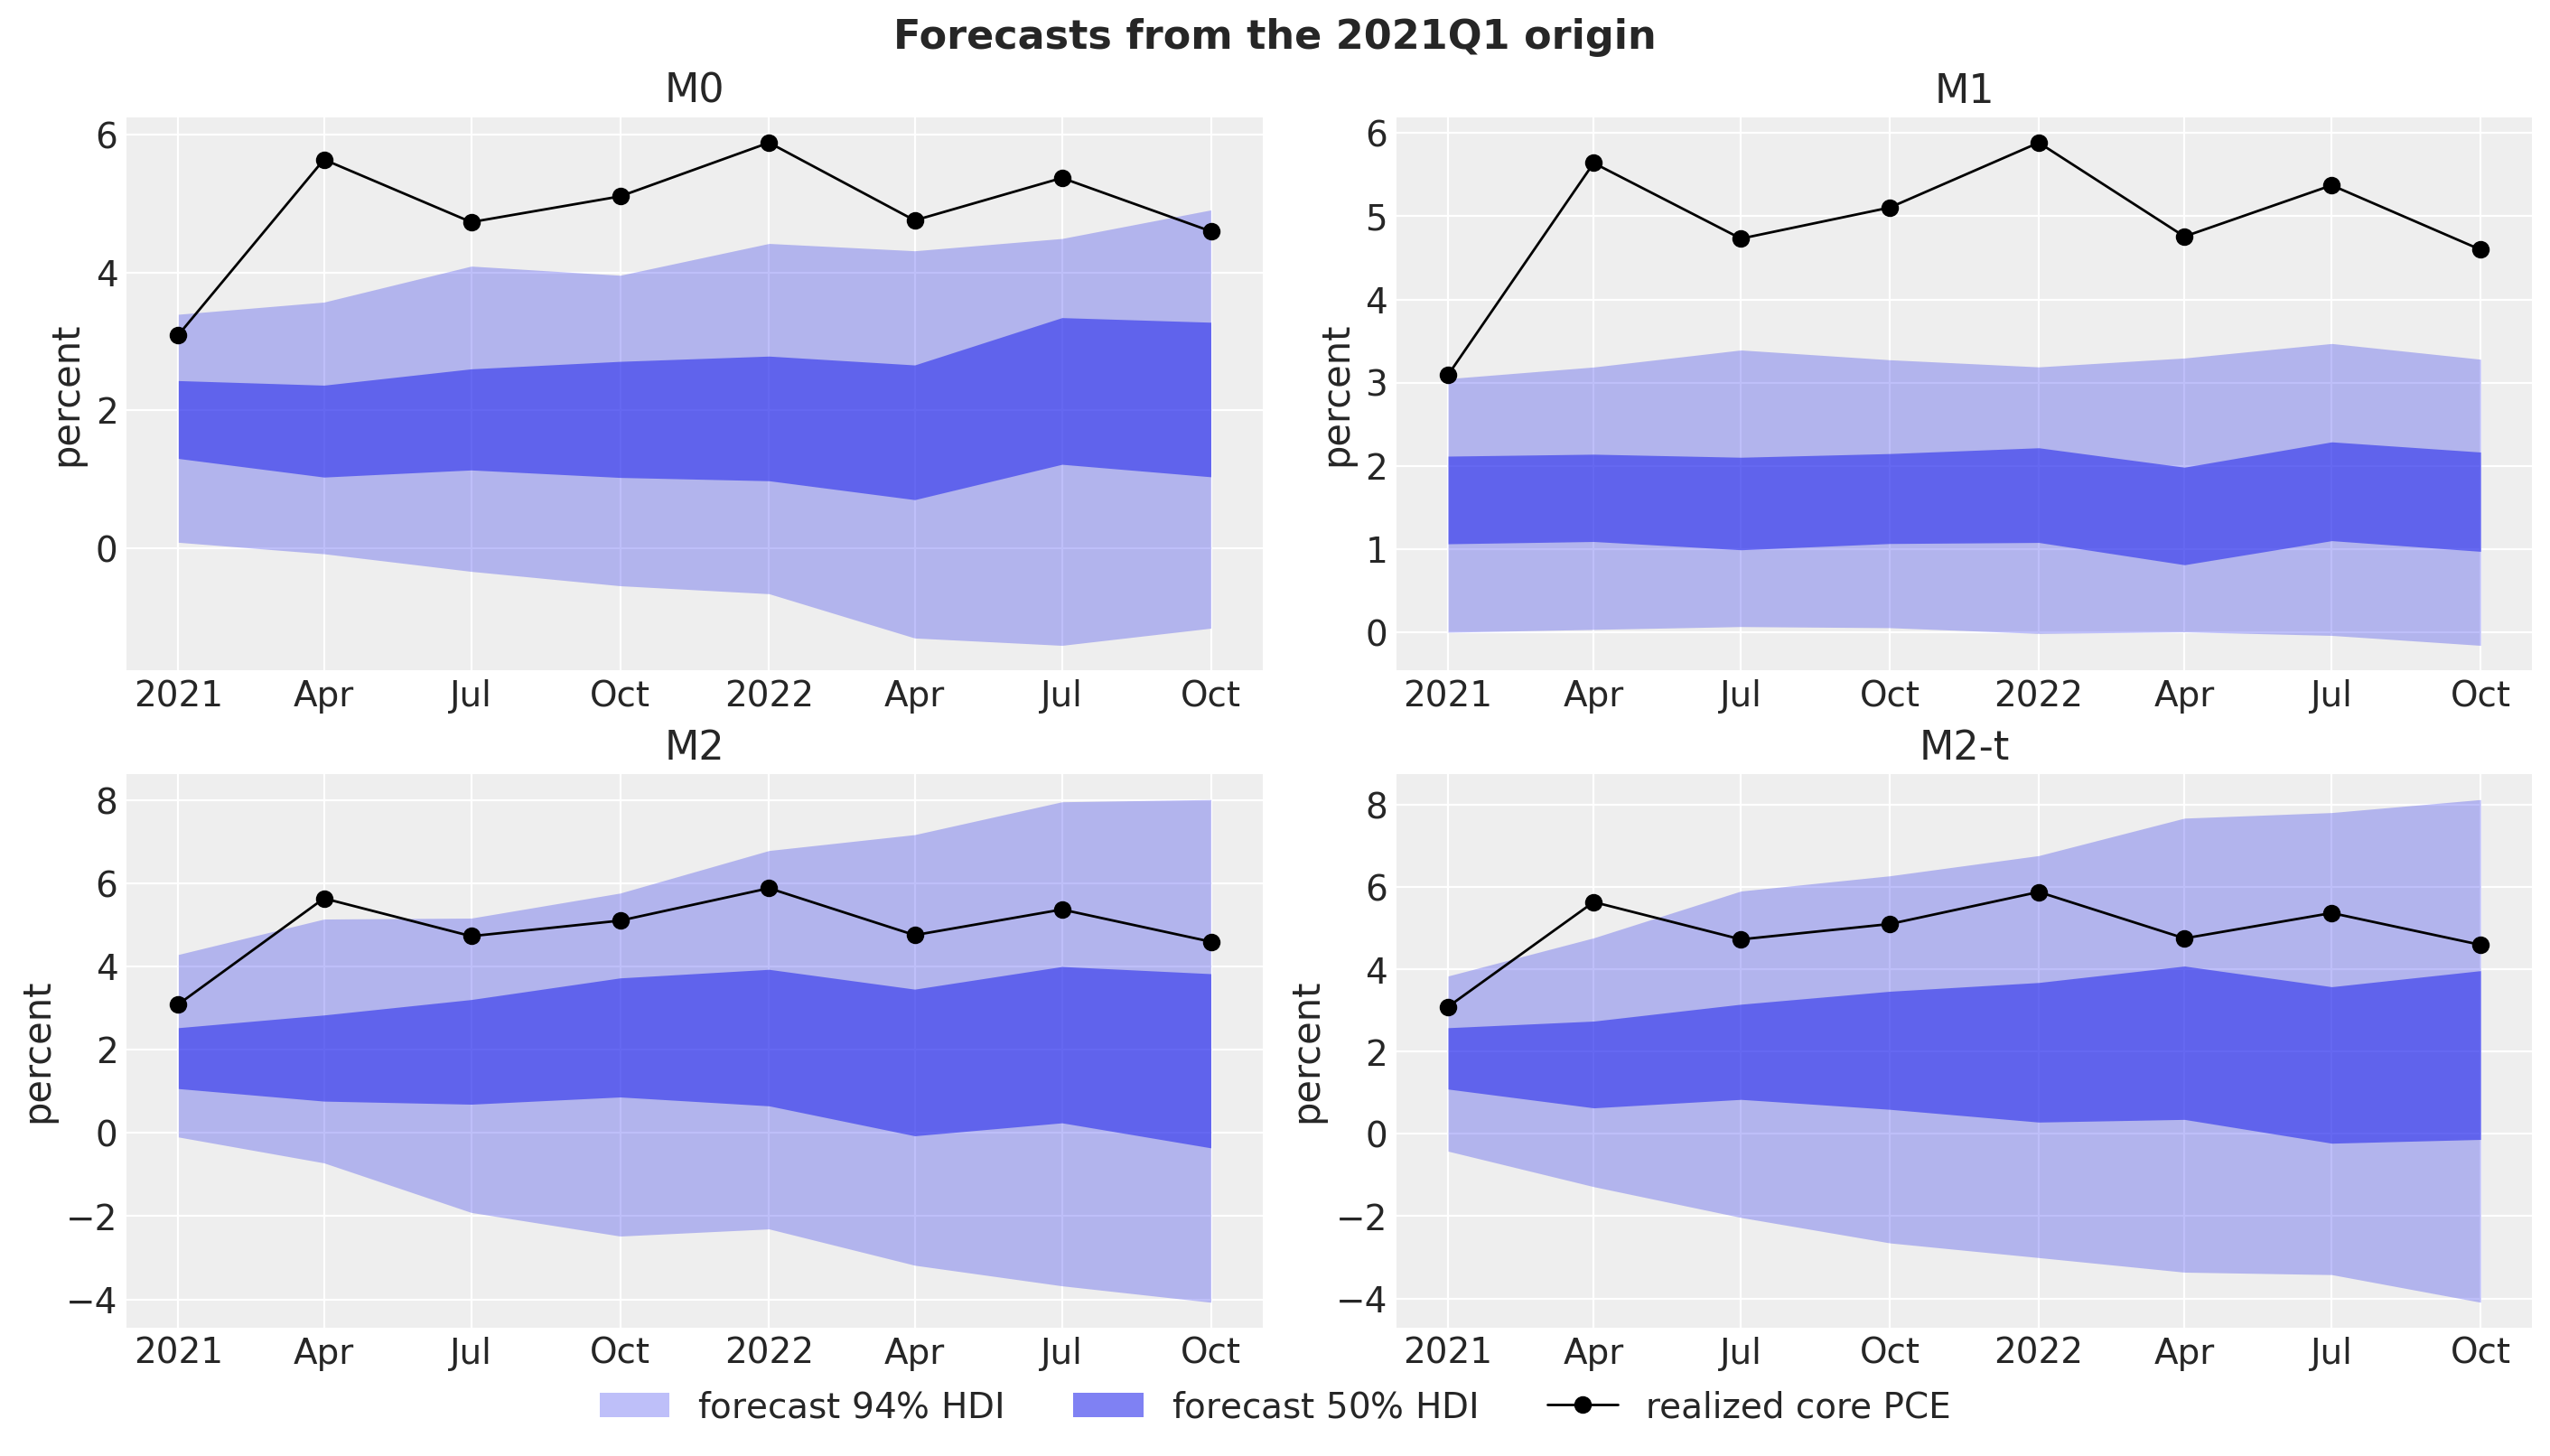

In [23]:
origin_2021 = int(np.flatnonzero(origins == np.datetime64("2021-01-01"))[0])
window = backtest_results["M2"][origin_2021]
window_dates = date_num[window.t1 : window.t2]
realized = rates[window.t1 : window.t2, -1]
draws_2021 = np.concatenate(
    [
        np.asarray(results[origin_2021].prediction)[..., -1:]
        for results in backtest_results.values()
    ],
    axis=-1,
)  # (samples, horizon, rungs): the core PCE draws of every rung from the 2021Q1 origin

pc, band_handles = plot_bands(
    draws_2021,
    window_dates,
    list(backtest_results),
    label="forecast ",
    col_wrap=2,
    figsize=(14, 8),
)
fig = pc.viz["figure"].item()

for ax, label in zip(fig.axes, backtest_results, strict=True):
    (realized_line,) = ax.plot(
        window_dates, realized, color="black", lw=1, marker="o", label="realized core PCE"
    )
    ax.set(title=label, ylabel="percent")

fig.legend(handles=[*band_handles, realized_line], loc="outside lower center", ncols=3)
fig.suptitle("Forecasts from the 2021Q1 origin", fontsize=16, fontweight="bold");

Takeaway, to be read from the figure after execution.

The last check on the backtest is the fits themselves: the divergences of every window, per rung.

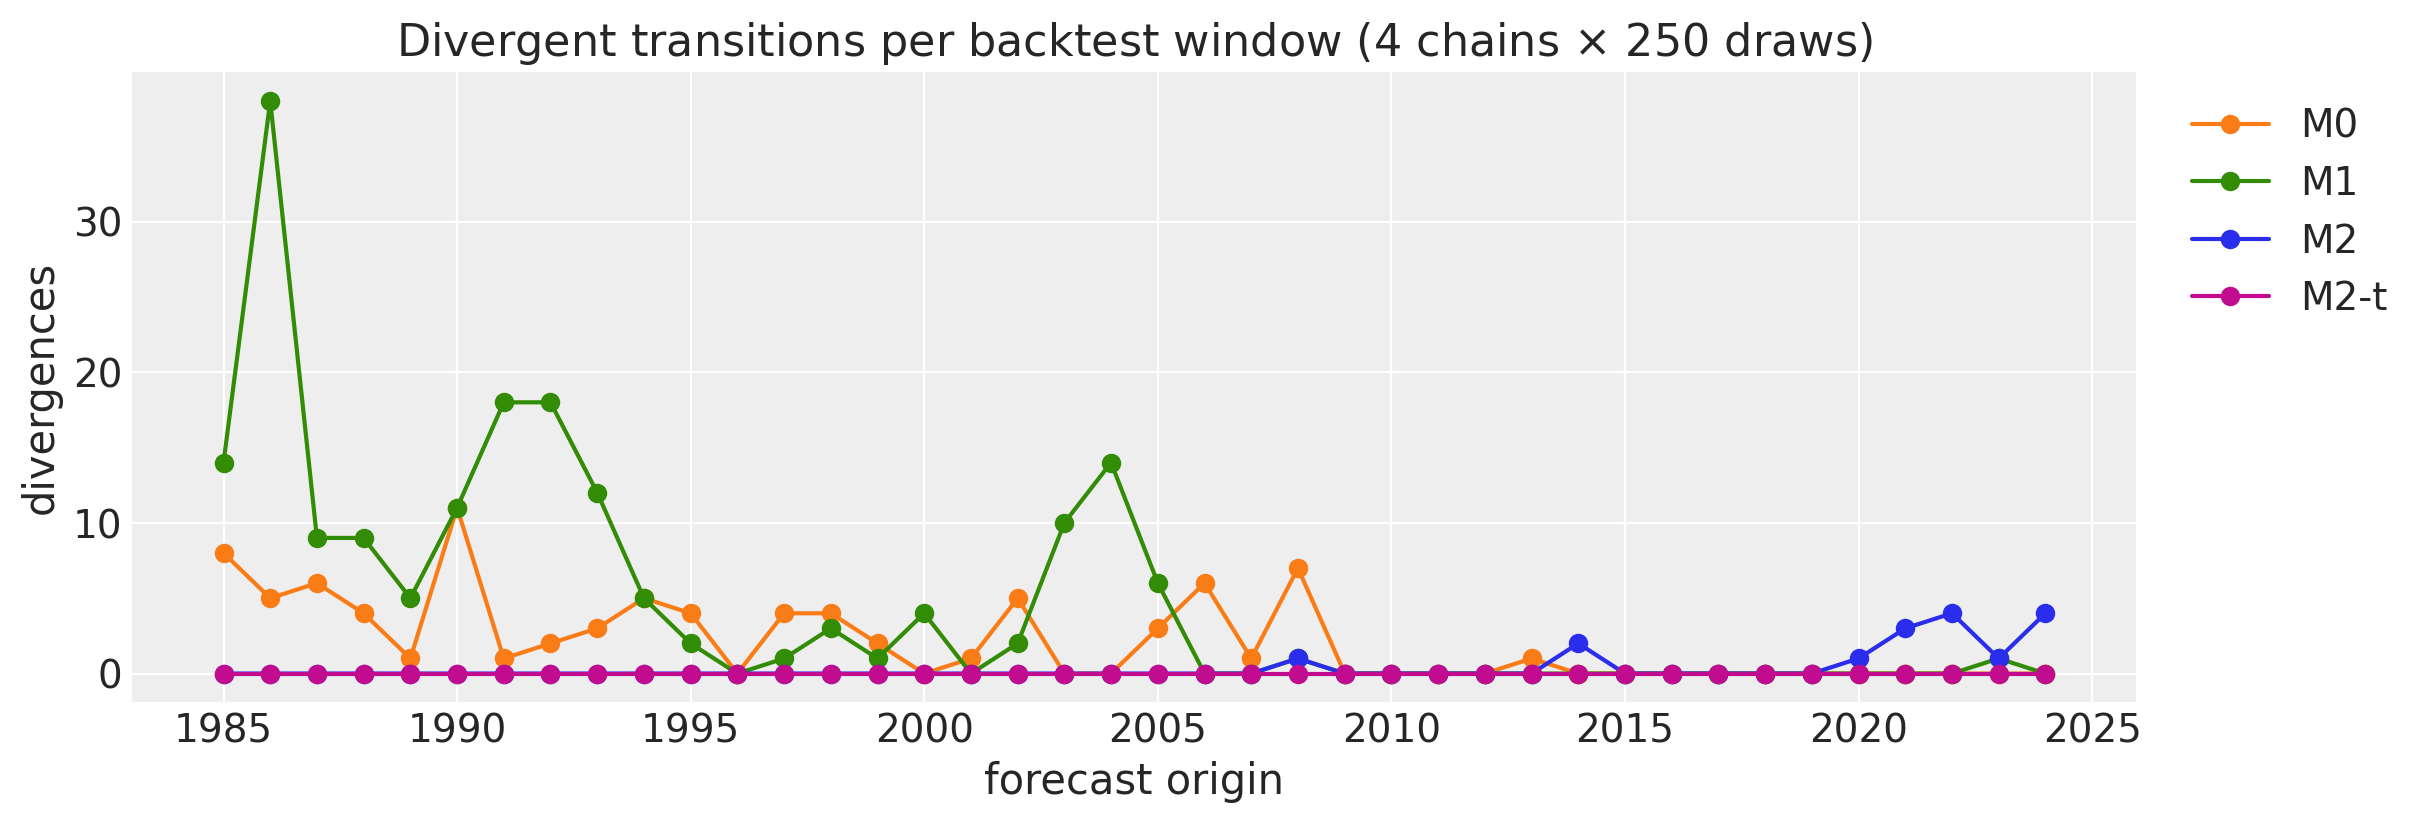

In [24]:
fig, ax = plt.subplots(figsize=(12, 4))

for label in backtest_results:
    counts = [count for rung, _, count in backtest_divergences if rung == label]
    ax.plot(origins, counts, marker="o", color=RUNG_COLORS[label], label=label)

locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title=r"Divergent transitions per backtest window (4 chains $\times$ 250 draws)",
    xlabel="forecast origin",
    ylabel="divergences",
);

Takeaway, to be read from the figure after execution.

## Sensitivity to the vol-of-vol

$\gamma$ is the one number we fixed. Three checks say how much it matters:

- The posterior of the trend volatility under $\gamma \in \{0.05, 0.1, 0.2\}$, from three full fits.
- The backtest CRPS of M2 under the same three values.
- A fit that learns $\gamma$ with the prior $\gamma \sim \text{LogNormal}(\log 0.1, 0.3)$, whose central $94\%$ range is $0.056$ to $0.18$.

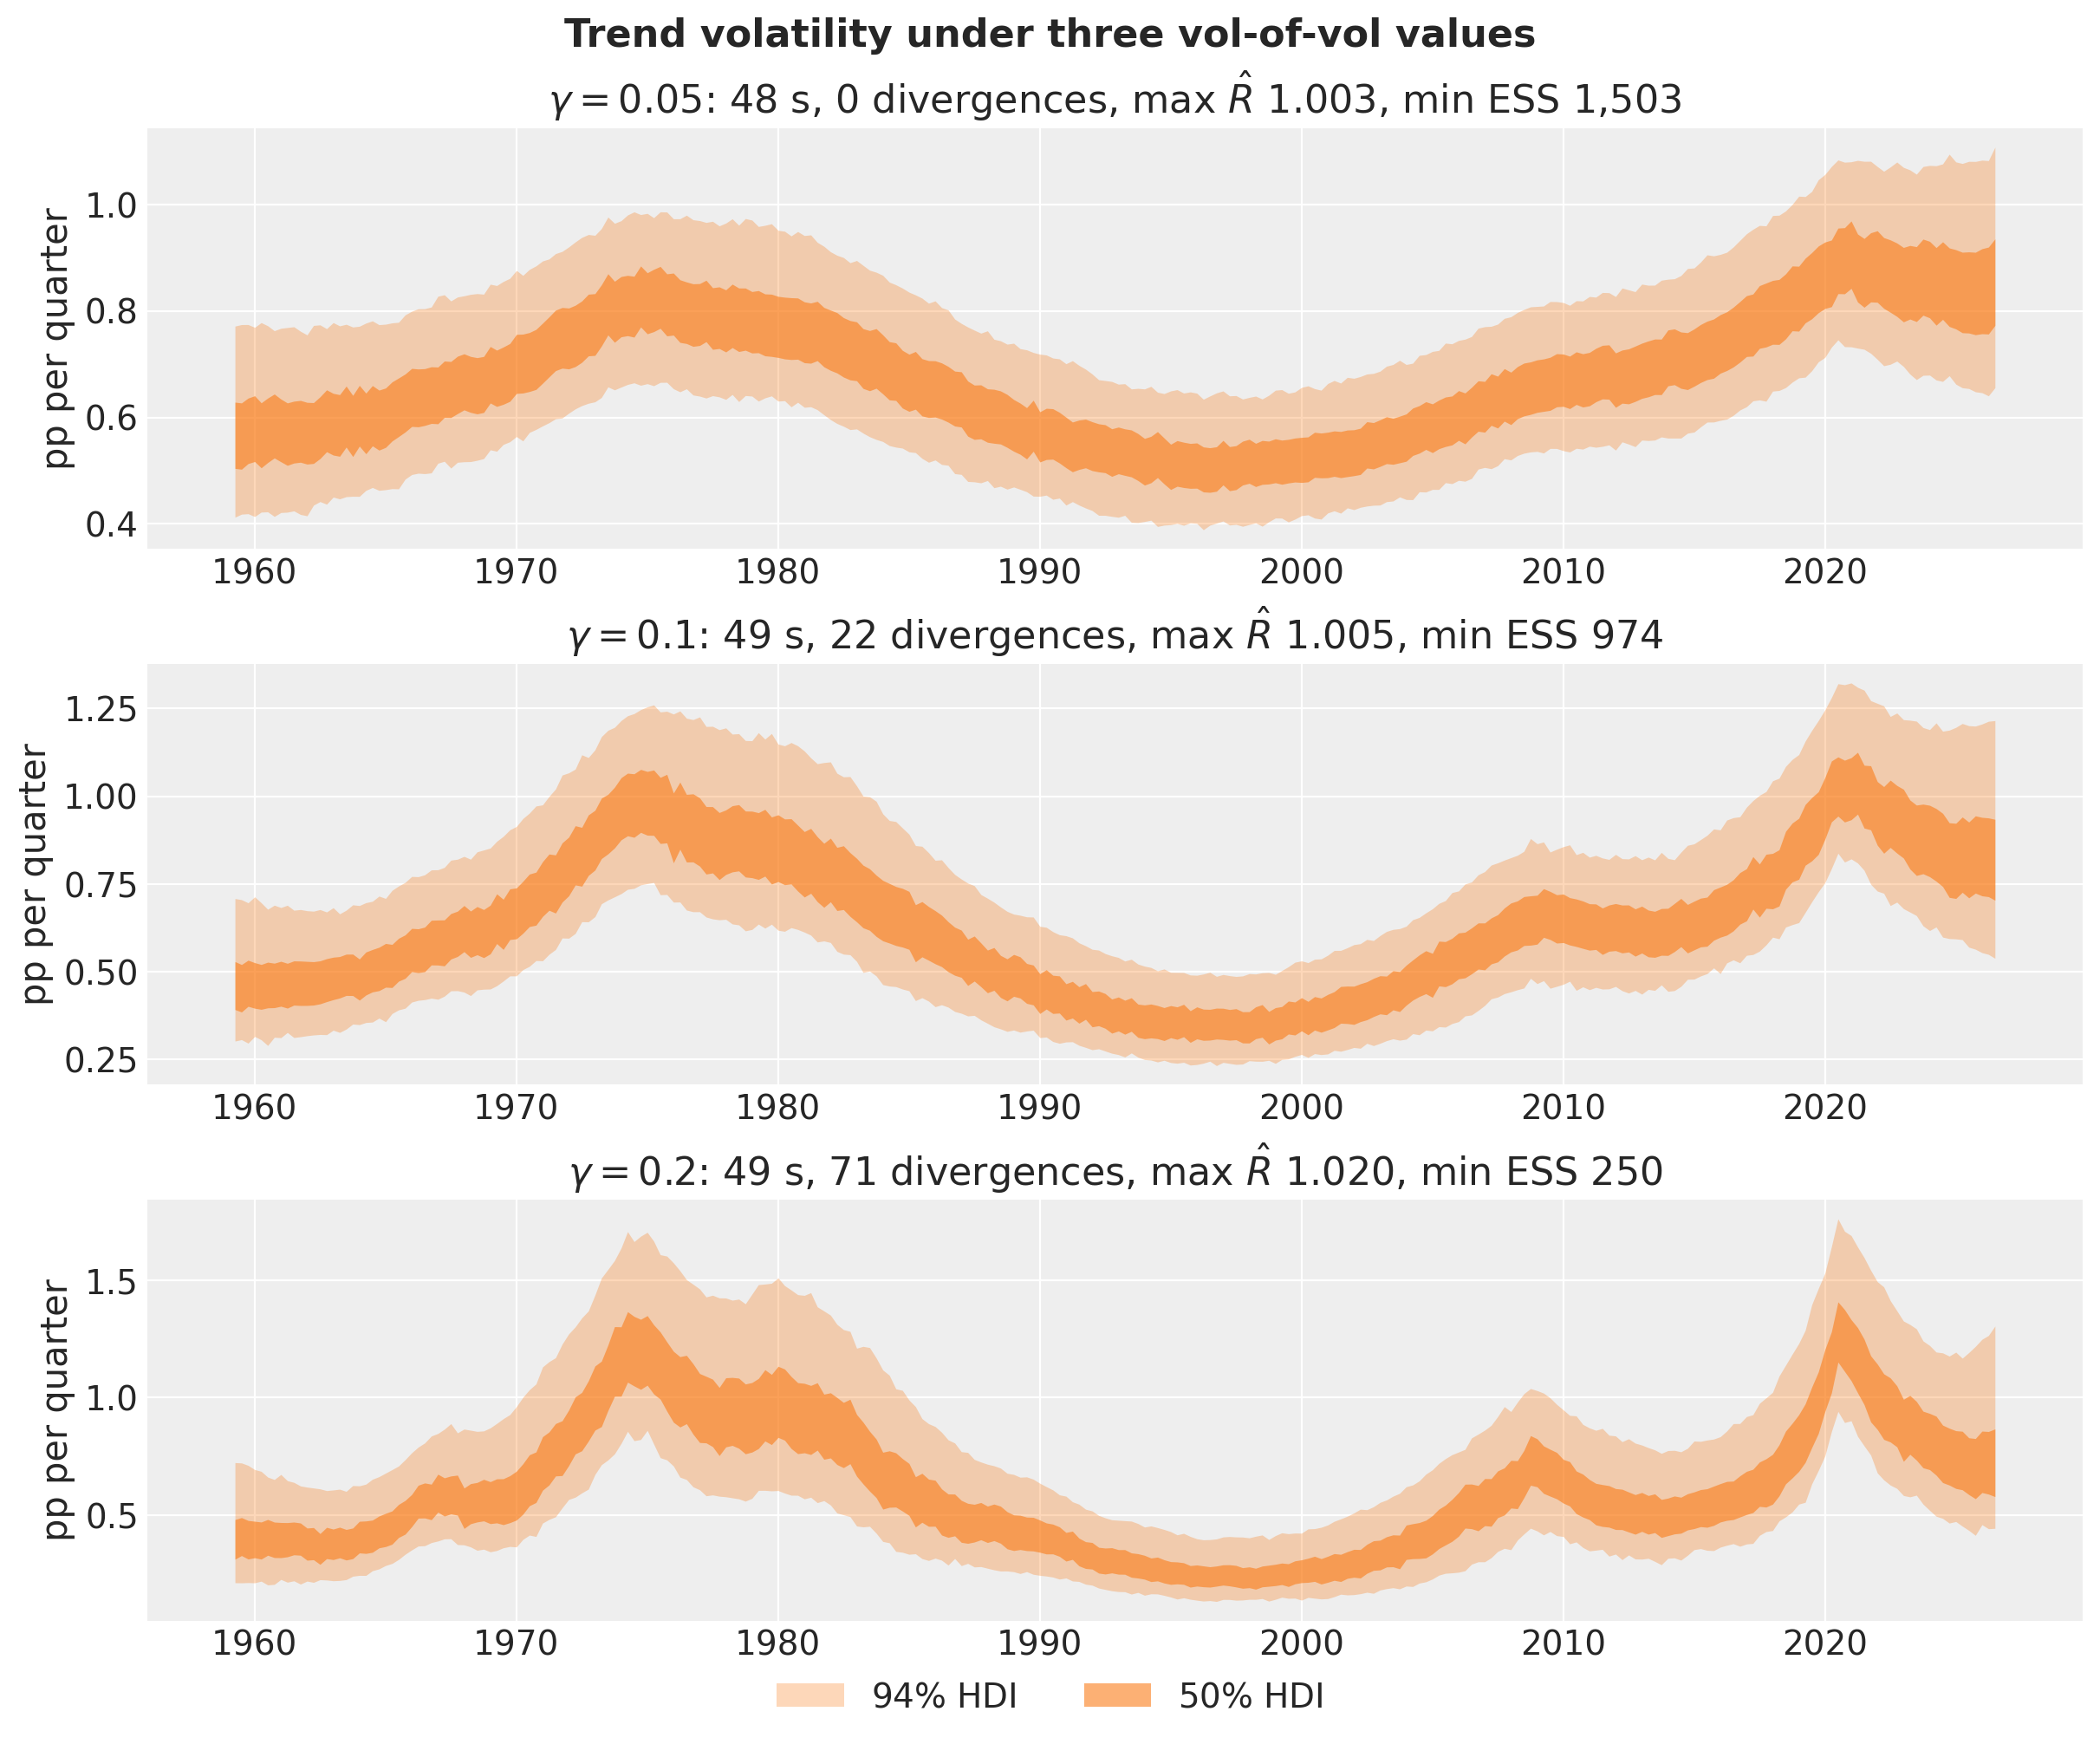

In [25]:
VOL_OF_VOL_GRID = (0.05, 0.1, 0.2)
grid_fits: dict[float, tuple[MCMC, float]] = {0.1: (mcmc, seconds)}

for gamma in VOL_OF_VOL_GRID:
    if gamma not in grid_fits:
        rng_key, key_fit = random.split(rng_key)
        grid_fits[gamma] = fit_nuts(
            key_fit,
            make_trend_inflation_model(num_measures, vol_of_vol=gamma),
            rates,
            num_warmup=FULL_WARMUP,
            num_samples=FULL_SAMPLES,
        )

grid_draws = np.concatenate(
    [np.asarray(grid_fits[gamma][0].get_samples()["trend_vol"]) for gamma in VOL_OF_VOL_GRID],
    axis=-1,
)  # (samples, quarters, 3): one column per gamma
pc, band_handles = plot_bands(
    grid_draws,
    date_num,
    [rf"$\gamma = {gamma}$" for gamma in VOL_OF_VOL_GRID],
    color="C1",
    figsize=(12, 10),
)
fig = pc.viz["figure"].item()

for ax, gamma in zip(fig.axes, VOL_OF_VOL_GRID, strict=True):
    ax.set(title=fit_title(rf"$\gamma = {gamma}$", *grid_fits[gamma]), ylabel="pp per quarter")

fig.legend(handles=band_handles, loc="outside lower center", ncols=2)
fig.suptitle("Trend volatility under three vol-of-vol values", fontsize=16, fontweight="bold");

Takeaway, to be read from the figure after execution.

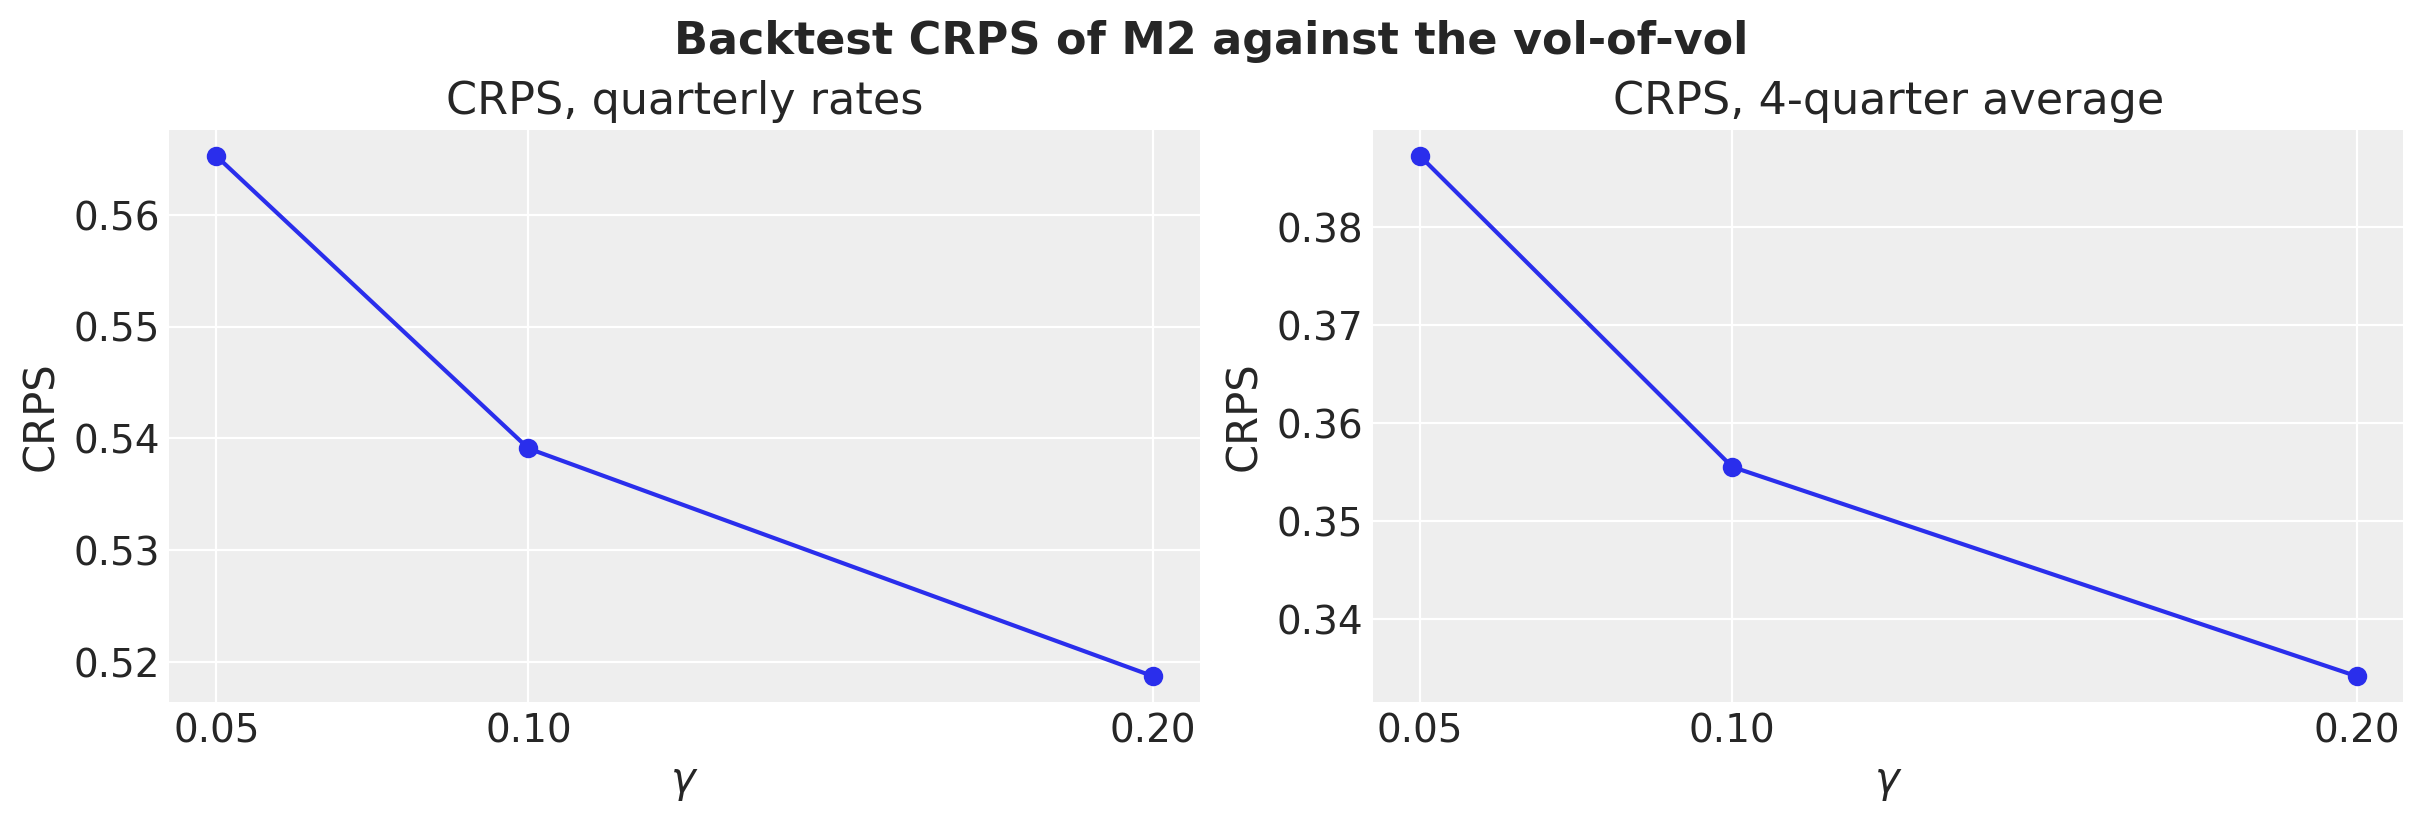

In [26]:
grid_results: dict[float, list[BacktestResult]] = {0.1: backtest_results["M2"]}

for gamma in VOL_OF_VOL_GRID:
    if gamma not in grid_results:
        rng_key, key_backtest = random.split(rng_key)
        grid_results[gamma] = run_backtest(
            key_backtest,
            f"M2 ($\\gamma = {gamma}$)",
            partial(make_trend_inflation_model, num_measures, vol_of_vol=gamma),
            rates,
        )

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4), layout="constrained")

for ax, metric, title in zip(
    axes, ("crps", "crps_4q"), ("quarterly rates", "4-quarter average"), strict=True
):
    means = [metric_values(grid_results[gamma], metric).mean() for gamma in VOL_OF_VOL_GRID]
    ax.plot(VOL_OF_VOL_GRID, means, marker="o", color="C0")
    ax.set(title=f"CRPS, {title}", xlabel=r"$\gamma$", xticks=VOL_OF_VOL_GRID, ylabel="CRPS")

fig.suptitle("Backtest CRPS of M2 against the vol-of-vol", fontsize=16, fontweight="bold");

Takeaway, to be read from the figure after execution.

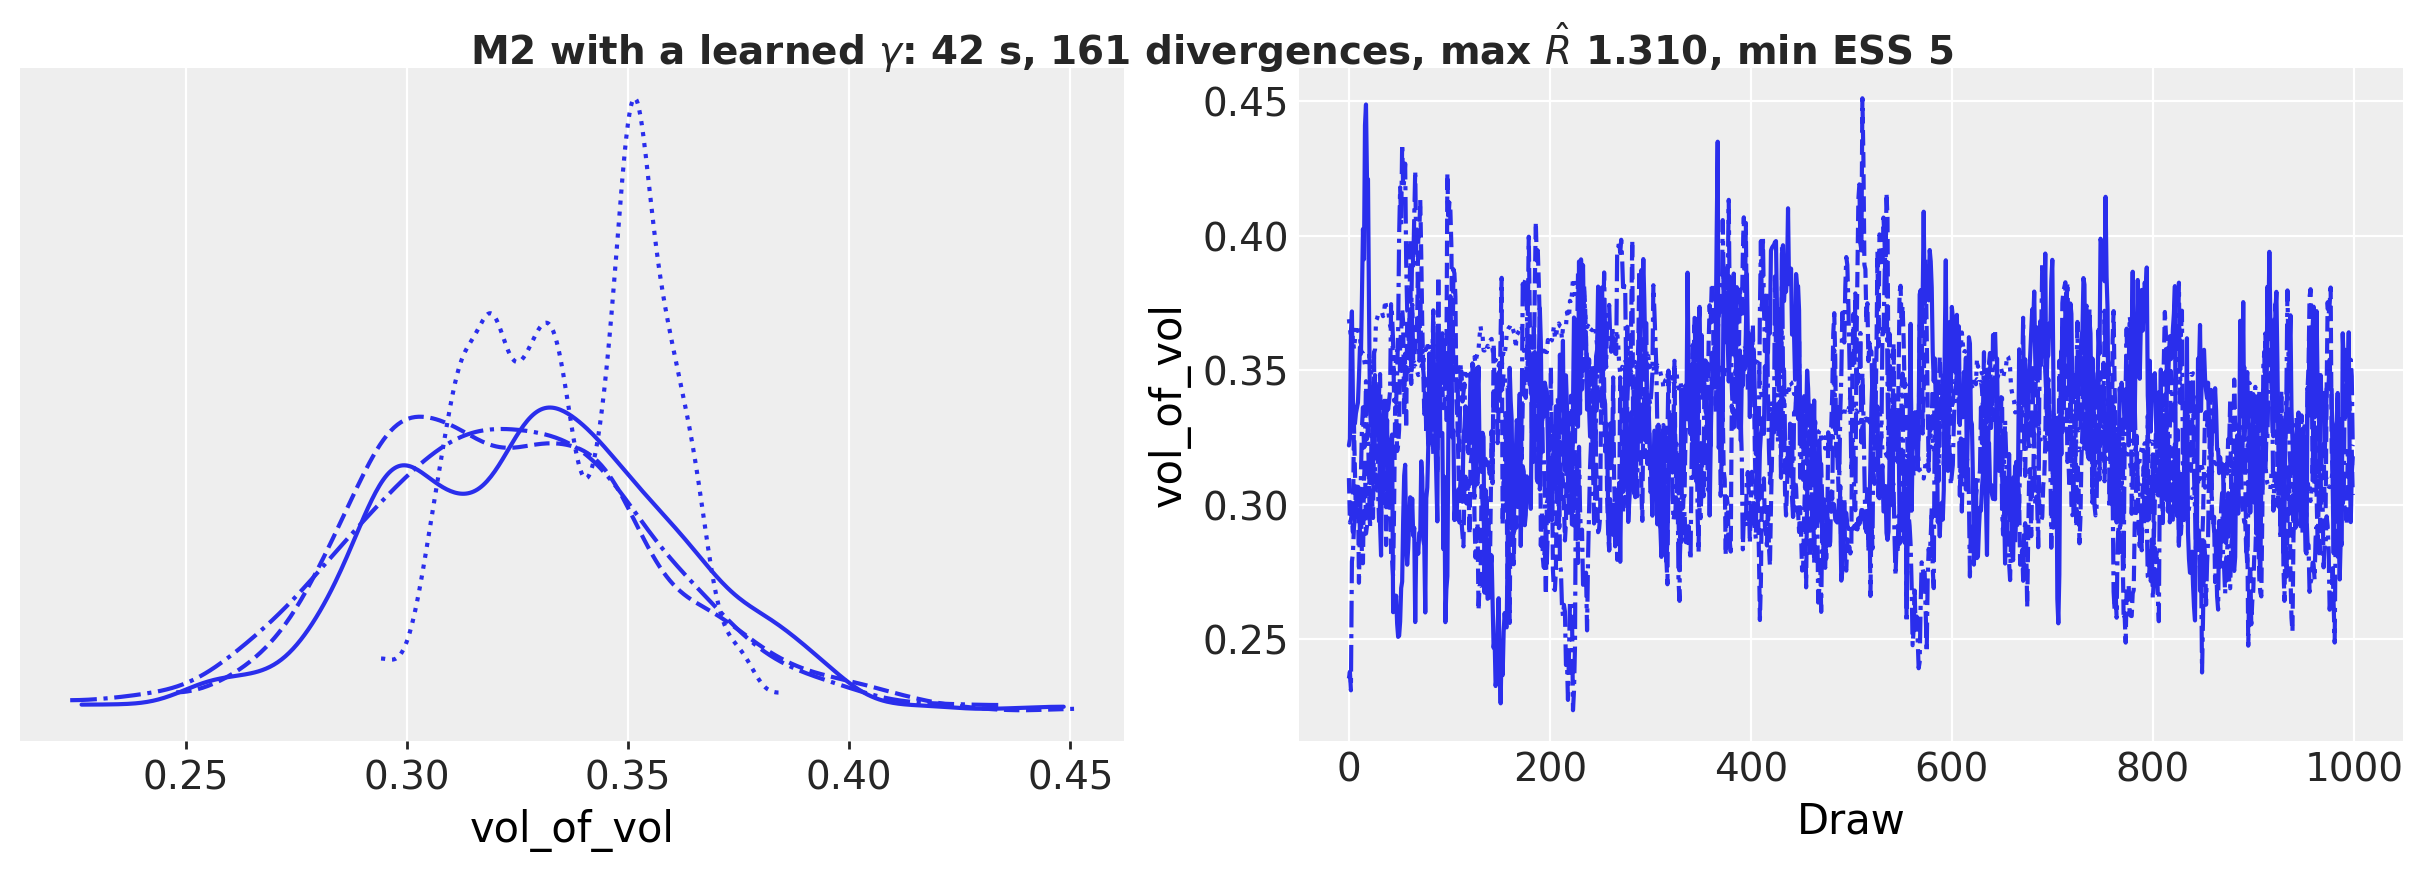

In [27]:
def learned_vol_of_vol_model(covariates: Array, data: Array | None = None) -> None:
    """M2 with the vol-of-vol as a parameter, shared by the trend and the gaps."""
    vol_of_vol = numpyro.sample("vol_of_vol", dist.LogNormal(jnp.log(0.1), 0.3))
    make_trend_inflation_model(num_measures, vol_of_vol=vol_of_vol)(covariates, data)


rng_key, key_fit, key_tree = random.split(rng_key, 3)
mcmc_learned, seconds_learned = fit_nuts(
    key_fit, learned_vol_of_vol_model, rates, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES
)
tree_learned = export(key_tree, learned_vol_of_vol_model, mcmc_learned)

pc = az.plot_trace_dist(tree_learned, var_names=["vol_of_vol"], figure_kwargs={"figsize": (12, 4)})
pc.viz["figure"].item().suptitle(
    fit_title(r"M2 with a learned $\gamma$", mcmc_learned, seconds_learned),
    fontsize=14,
    fontweight="bold",
    y=1.05,
);

Takeaway, to be read from the figure after execution.

## Cost

The full M2 fit and the backtests are the expensive parts of the notebook. We time one more full fit: the same model wrapped in [`time_reparam`](../../reference/reparam.time_reparam.html) with the discrete cosine transform, which rotates the in-sample innovation sites of a model so that a random walk with a learned step scale samples faster. Here the steps are already standardized, so the rotation has nothing to decorrelate, and the figure says what it costs.

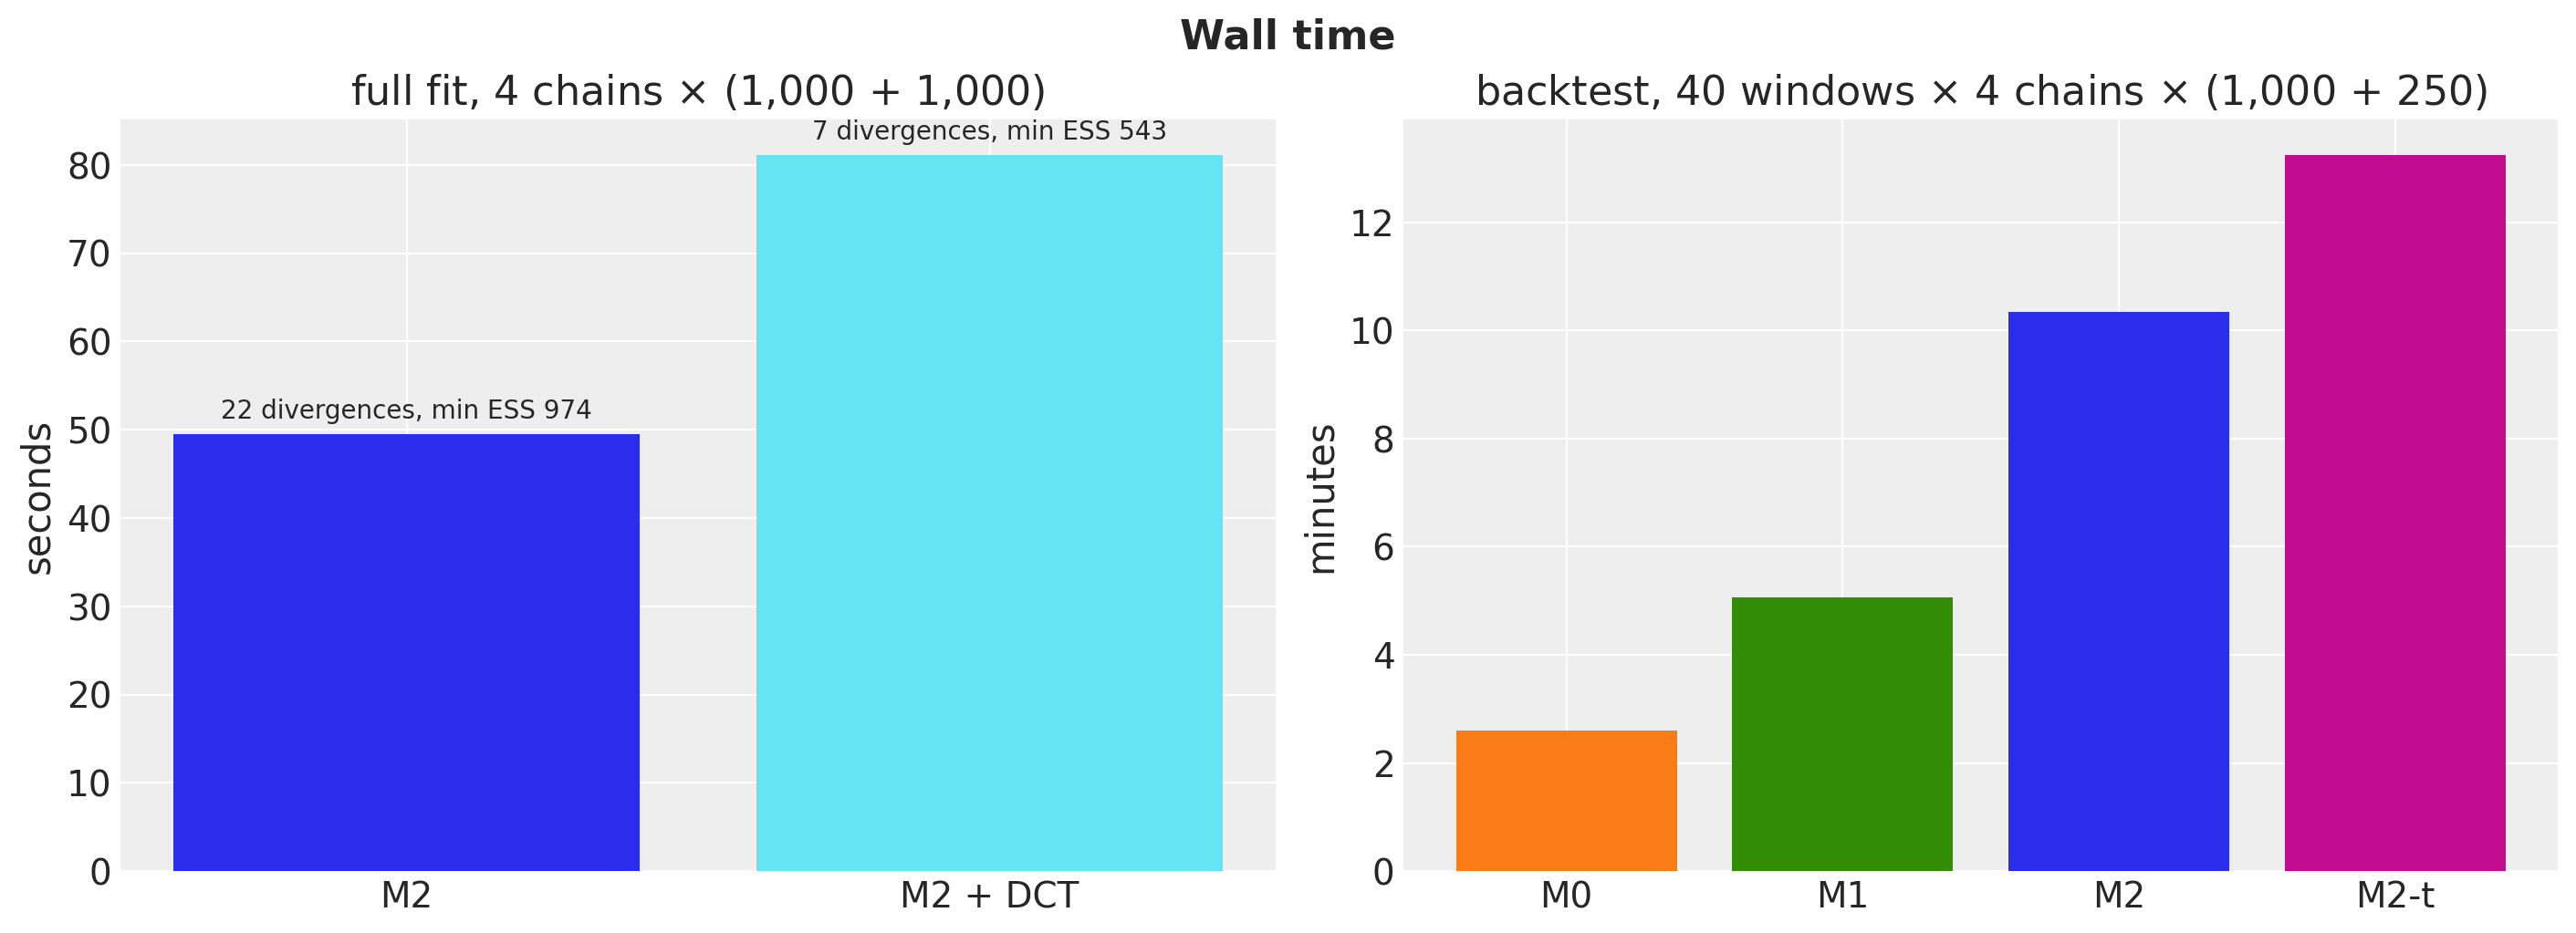

In [28]:
rng_key, key_fit = random.split(rng_key)
mcmc_dct, seconds_dct = fit_nuts(
    key_fit, time_reparam(model, "dct"), rates, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES
)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), layout="constrained")
full_fits = {"M2": (mcmc, seconds), "M2 + DCT": (mcmc_dct, seconds_dct)}
axes[0].bar(list(full_fits), [fit[1] for fit in full_fits.values()], color=["C0", "C5"])

for position, (fit, fit_seconds) in enumerate(full_fits.values()):
    r_hat, ess = diagnostics(fit)
    axes[0].annotate(
        f"{num_divergences(fit)} divergences, min ESS {ess:,.0f}",
        (position, fit_seconds),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
    )

axes[0].set(title=r"full fit, 4 chains $\times$ (1,000 + 1,000)", ylabel="seconds")
backtest_seconds = {
    label: sum(result.walltime for result in results)
    for label, results in backtest_results.items()
}
axes[1].bar(
    list(backtest_seconds),
    [seconds / 60 for seconds in backtest_seconds.values()],
    color=[RUNG_COLORS[label] for label in backtest_seconds],
)
axes[1].set(
    title=r"backtest, 40 windows $\times$ 4 chains $\times$ (1,000 + 250)", ylabel="minutes"
)
fig.suptitle("Wall time", fontsize=16, fontweight="bold");

Takeaway, to be read from the figure after execution.

## Discussion

Discussion, to be written from the outputs after execution.

## References

- Atkeson, A., Ohanian, L. E. (2001). [*Are Phillips curves useful for forecasting inflation?*](https://www.minneapolisfed.org/research/quarterly-review/are-phillips-curves-useful-for-forecasting-inflation). Federal Reserve Bank of Minneapolis Quarterly Review, 25(1).
- Clark, T. E. (2011). [*Real-time density forecasts from Bayesian vector autoregressions with stochastic volatility*](https://doi.org/10.1198/jbes.2010.09248). Journal of Business & Economic Statistics, 29(3).
- Gneiting, T., Raftery, A. E. (2007). [*Strictly proper scoring rules, prediction, and estimation*](https://doi.org/10.1198/016214506000001437). Journal of the American Statistical Association, 102(477).
- Mertens, E. (2016). [*Measuring the level and uncertainty of trend inflation*](https://doi.org/10.1162/REST_a_00549). Review of Economics and Statistics, 98(5).
- Stock, J. H., Watson, M. W. (2007). [*Why has U.S. inflation become harder to forecast?*](https://doi.org/10.1111/j.1538-4616.2007.00014.x). Journal of Money, Credit and Banking, 39(s1).
- Stock, J. H., Watson, M. W. (2016). [*Core inflation and trend inflation*](https://doi.org/10.1162/REST_a_00608). Review of Economics and Statistics, 98(4).
- Data: U.S. Bureau of Labor Statistics, [CPIAUCSL](https://fred.stlouisfed.org/series/CPIAUCSL) and [CPILFESL](https://fred.stlouisfed.org/series/CPILFESL); U.S. Bureau of Economic Analysis, [PCEPI](https://fred.stlouisfed.org/series/PCEPI) and [PCEPILFE](https://fred.stlouisfed.org/series/PCEPILFE); all retrieved from FRED, Federal Reserve Bank of St. Louis, on 2026-11-08.
- Related examples: [vector autoregression](var.html), [univariate forecasting](forecasting_univariate.html).